In [1]:
import os
import pandas as pd
import numpy as np
import json 
from pathlib import Path
import itertools 

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.lines import Line2D
import seaborn as sns

from neuron_morphology.swc_io import morphology_from_swc
from neuron_morphology.constants import BASAL_DENDRITE, APICAL_DENDRITE
from morph_utils.visuals import basic_morph_plot
from morph_utils.measurements import leftextent, rightextent 
from morph_utils.templates import load_layer_template

from scipy.stats import kde, kruskal, mannwhitneyu
from statsmodels.stats.multitest import fdrcorrection
from scikit_posthocs import posthoc_dunn
from statannotations.Annotator import Annotator

import random
import warnings
import operator

import pickle

import sys 
sys.path.append('/root/capsule/code/figures') 
from core_utils import get_seaad_colors, get_tx_order, format_box_plot
from morphology_utils import add_swc_paths, AVERAGE_DISTANCE_BETWEEN_NODES

plt.rcParams['pdf.fonttype'] = 42 # ensures that the text is editable when imported into Illustrator


/opt/conda/lib/python3.10/site-packages/google/api_core/_python_version_support.py:254: FutureWarning: You are using a Python version (3.10.12) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


In [2]:
#HANN mapping
class_col = 'class_label_Hierarchical'
subclass_col = 'subclass_label_Hierarchical'
cluster_col = 'cluster_label_Hierarchical'

In [3]:
# Save root 
output_dir = Path('/root/capsule/scratch') / '20260807' / 'dendrite'
os.makedirs(output_dir, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')

metadata_path =              DATA_ROOT / 'human'            / 'metadata'   / '20260807' / 'human_metadata.csv'

data_root =                  DATA_ROOT / 'human' / 'morphology' / 'dendrite' / '20260712'
layer_aligned_dir =          DATA_ROOT / 'human' / 'morphology' / 'swc'      / '20260625' / 'SWC_LayerAligned'

morpho_feature_rename_file = DATA_ROOT / 'formatting_dicts' / 'morpho_feature_rename.csv'
l23_ttype_rename_file =      DATA_ROOT / 'formatting_dicts' / 'L23_ttype_rename.json'
ttype_layer_file =           DATA_ROOT / 'formatting_dicts' / 'ttype_layer_dict.json'

lobe_color_file =            DATA_ROOT / 'colors'           / 'lobe_colors.json'
paradigm_color_file =        DATA_ROOT / 'colors'           / 'paradigm_colors.json'
layer_color_file =           DATA_ROOT / 'colors'           / 'layer_colors.json'


#load data
morpho_feature_rename_df = pd.read_csv(morpho_feature_rename_file)
morpho_feature_rename_dict = dict(zip(morpho_feature_rename_df.old_feature_name, morpho_feature_rename_df.new_feature_name))

with open(l23_ttype_rename_file, "r") as f:
    L23_ttype_rename_dict = json.load(f)

with open(ttype_layer_file, "r") as f:
    ttype_to_layer_dict = json.load(f)

aligned_histogram = pd.read_csv(os.path.join(data_root, 'AlignedHistogram.csv'))
aligned_soma_depths = pd.read_csv(os.path.join(data_root, 'AlignedSomaDepths.csv'))

raw_feature_wide = pd.read_csv(os.path.join(data_root, 'RawFeatureWide.csv'))
raw_feature_wide = raw_feature_wide.rename(columns=morpho_feature_rename_dict)

metadata = pd.read_csv(metadata_path)
metadata = metadata[metadata.cell_id.isin(raw_feature_wide.specimen_id.to_list())]


In [4]:
#data wrangling

#combine data and get la file paths 
metadata = metadata.rename(columns={"cell_id": "specimen_id", cluster_col: "t_type", subclass_col:'subclass_label'})#, "Pinned Structure and Layer": "final_structure"})
metadata = metadata[['specimen_id', 't_type', 'subclass_label', 'lobe', 'paradigm']] #, 'seuratQCpass'
metadata['lobe_group'] = metadata['lobe'].apply(lambda x: x if x == 'TemL' else 'Other')

#remove vals without a seaad mapping
metadata['t_type'] = metadata['t_type'].fillna('TBD')
metadata['subclass_label'] = metadata['subclass_label'].fillna('TBD')

#massage metadata
metadata['subclass_label'] = metadata['subclass_label'].replace('L5 ET_ME', 'L5 ET')
metadata['subclass_label'] = metadata['subclass_label'].replace('L5 ET(ME)', 'L5 ET')
metadata['t_type'] = metadata['t_type'].replace('L5 ET_ME', 'L5 ET(ME)')
metadata['t_type'] = metadata['t_type'].apply(lambda x: L23_ttype_rename_dict.get(x, x))
metadata['layer'] = metadata["t_type"].map(ttype_to_layer_dict)

#add soma depths and features
data = metadata.merge(aligned_soma_depths, how='inner', on='specimen_id')
data = add_swc_paths(data, layer_aligned_dir, column_name='SWC_layer_aligned')
data = data.merge(raw_feature_wide, how='inner', on='specimen_id') 

#sort the cells
sorted_data = data.sort_values(by=['t_type', 'soma_distance_from_pia'])

#delete columns where any vals are nan
sorted_clean_data = sorted_data.dropna(axis=1, how='all')


In [5]:
# get avg layer template
species = 'human'
layer_info, layer_labels, layer_colors = load_layer_template(species)


#Get color dicts
color_dict = get_seaad_colors()
with open(layer_color_file, "r") as f: layer_color_dict = json.load(f)
with open(lobe_color_file, "r") as f: lobe_color_dict = json.load(f)
with open(paradigm_color_file, "r") as f: paradigm_color_dict = json.load(f)

color_dicts = {
    't_type' : color_dict, 
    'subclass_label' : color_dict, 
    'lobe' : lobe_color_dict, 
    'lobe_group' : lobe_color_dict,
    'paradigm' : paradigm_color_dict,
    'layer' : layer_color_dict  
}


#Get custom transcriptomic order
ttype_order, subclass_order = get_tx_order()
group_order = {
    'subclass_label' : subclass_order,
    't_type' :  ttype_order,
    'lobe' : ['TemL', 'FroL'],
    'lobe_group' : ['TemL', 'Other'],
    'paradigm' : ['acute', 'culture'],
    'layer' : sorted(list(set(ttype_to_layer_dict.values())))
}

Subclass x feature box plots with stats

In [6]:
# subclass x feature stats
x_var = 'subclass_label' #what to do box plots on 
x_var_order = group_order[x_var]

features = raw_feature_wide.columns.tolist()[1:]

# Kruskal-Wallis H test on all features
kw_pvals = dict()
kw_hvals = dict()
for f in features:
    # Create a list of groups dynamically
    groups = [sorted_clean_data.loc[sorted_clean_data[x_var] == x][f].dropna() for x in x_var_order]
    
    # Only include groups that have data
    groups = [group for group in groups if not group.empty]

    if len(groups) < 2:
        print(f"Not enough groups with data for feature {f}")
        continue
    try:
        hvalue, pvalue = kruskal(*groups, nan_policy='omit')
        kw_hvals[f] = hvalue
        kw_pvals[f] = pvalue
    except ValueError as e:
        print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

# FDR correction
kw_pvals_list = list(kw_pvals.values())
kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

# Post Hoc Dunn test for significant KW features, with FDR correction
dunn_pvals_fdr = dict()
for k, v in kw_rejected.items():
    if v:  # if null hypothesis was rejected, calculate Dunn post hoc
        dunn_pvals_fdr[k] = posthoc_dunn(sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)


/tmp/ipykernel_779895/1837185732.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT vs. L5 IT: Custom statistical test, P_val:2.026e-02
L5/6 NP vs. L5 ET: Custom statistical test, P_val:2.852e-03
L5 IT vs. L5 ET: Custom statistical test, P_val:2.299e-03
L4 IT vs. L5 ET: Custom statistical test, P_val:3.769e-06
L2/3 IT vs. L5 ET: Custom statistical test, P_val:1.405e-05
L4 IT vs. L6 IT Car3: Custom statistical test, P_val:1.209e-03
L4 IT vs. L6 IT: Custom statistical test, P_val:2.299e-03
L2/3 IT vs. L6 IT Car3: Custom statistical test, P_val:3.621e-03
L2/3 IT vs. L6 IT: Custom statistical test, P_val:8.098e-03


/tmp/ipykernel_779895/1837185732.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT vs. L4 IT: Custom statistical test, P_val:4.214e-14
L4 IT vs. L5 IT: Custom statistical test, P_val:4.168e-03
L2/3 IT vs. L5 IT: Custom statistical test, P_val:9.428e-24
L4 IT vs. L5/6 NP: Custom statistical test, P_val:2.037e-03
L2/3 IT vs. L5/6 NP: Custom statistical test, P_val:4.214e-14
L2/3 IT vs. L5 ET: Custom statistical test, P_val:3.652e-08
L4 IT vs. L6 IT Car3: Custom statistical test, P_val:3.803e-04
L4 IT vs. L6 IT: Custom statistical test, P_val:7.472e-05
L2/3 IT vs. L6 IT Car3: Custom statistical test, P_val:1.668e-16
L4 IT vs. L6 CT: Custom statistical test, P_val:4.607e-04
L2/3 IT vs. L6 IT: Custom statistical test, P_val:3.666e-16
L2/3 IT vs. L6 CT: Custom statistical test, P_val:2.036e-12
L4 IT vs. L6b: Custom statistical test, P_val:3.775e-03
L2/3 IT vs. L6b: Custom stat

/tmp/ipykernel_779895/1837185732.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT vs. L4 IT: Custom statistical test, P_val:4.390e-13
L4 IT vs. L5 IT: Custom statistical test, P_val:1.043e-06
L5/6 NP vs. L5 ET: Custom statistical test, P_val:4.309e-04
L6 IT vs. L6 CT: Custom statistical test, P_val:4.331e-02
L5 IT vs. L5 ET: Custom statistical test, P_val:9.265e-04
L4 IT vs. L5/6 NP: Custom statistical test, P_val:4.873e-02
L5/6 NP vs. L6 IT Car3: Custom statistical test, P_val:3.724e-02
L4 IT vs. L5 ET: Custom statistical test, P_val:2.450e-10
L5 ET vs. L6 CT: Custom statistical test, P_val:1.003e-03
L5/6 NP vs. L6 IT: Custom statistical test, P_val:3.019e-02
L2/3 IT vs. L5 ET: Custom statistical test, P_val:1.537e-03
L4 IT vs. L6 IT Car3: Custom statistical test, P_val:1.172e-07
L4 IT vs. L6 IT: Custom statistical test, P_val:4.039e-07
L4 IT vs. L6b: Custom statistica

... (85 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT vs. L4 IT: Custom statistical test, P_val:1.074e-18
L5/6 NP vs. L5 ET: Custom statistical test, P_val:1.642e-02
L5 ET vs. L6 IT Car3: Custom statistical test, P_val:5.308e-03
L2/3 IT vs. L5 IT: Custom statistical test, P_val:5.848e-23
L5 IT vs. L5 ET: Custom statistical test, P_val:2.601e-05
L5 ET vs. L6 IT: Custom statistical test, P_val:9.359e-05
L4 IT vs. L5 ET: Custom statistical test, P_val:1.184e-03
L2/3 IT vs. L5/6 NP: Custom statistical test, P_val:1.980e-05
L5 ET vs. L6 CT: Custom statistical test, P_val:2.679e-03
L5 ET vs. L6b: Custom statistical test, P_val:1.184e-03
L2/3 IT vs. L6 IT Car3: Custom statistical test, P_val:7.230e-07
L2/3 IT vs. L6 IT: Custom statistical test, P_val:4.158e-10
L2/3 IT vs. L6 CT: Custom statistical test, P_val:8.888e-06
L2/3 IT vs. L6b: Custom statis

/tmp/ipykernel_779895/1837185732.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT vs. L4 IT: Custom statistical test, P_val:1.608e-06
L4 IT vs. L5 IT: Custom statistical test, P_val:1.513e-02
L5 ET vs. L6 IT Car3: Custom statistical test, P_val:1.607e-09
L6 IT Car3 vs. L6 IT: Custom statistical test, P_val:9.797e-05
L2/3 IT vs. L5 IT: Custom statistical test, P_val:1.429e-12
L5 IT vs. L5 ET: Custom statistical test, P_val:2.158e-02
L4 IT vs. L5/6 NP: Custom statistical test, P_val:6.248e-03
L5 ET vs. L6 IT: Custom statistical test, P_val:3.038e-02
L5/6 NP vs. L6 IT Car3: Custom statistical test, P_val:6.752e-08
L6 IT Car3 vs. L6 CT: Custom statistical test, P_val:6.248e-03
L4 IT vs. L5 ET: Custom statistical test, P_val:1.088e-04
L2/3 IT vs. L5/6 NP: Custom statistical test, P_val:1.708e-08
L5 ET vs. L6 CT: Custom statistical test, P_val:1.195e-02
L5 IT vs. L6 IT Car3: 

/tmp/ipykernel_779895/1837185732.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


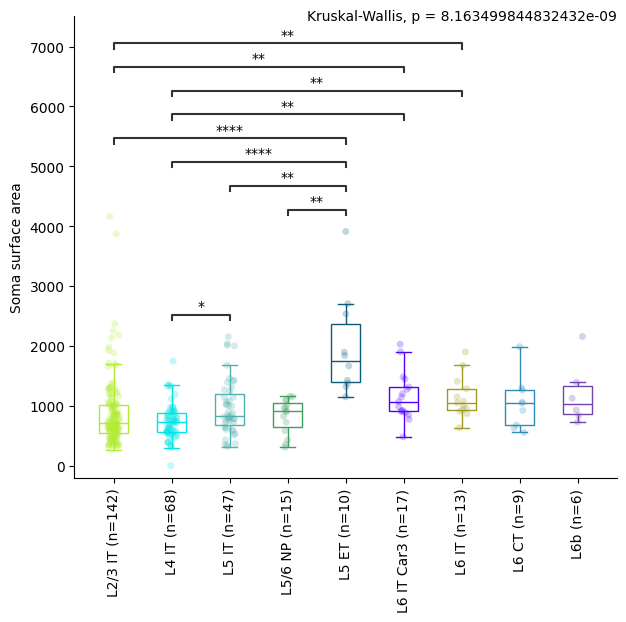

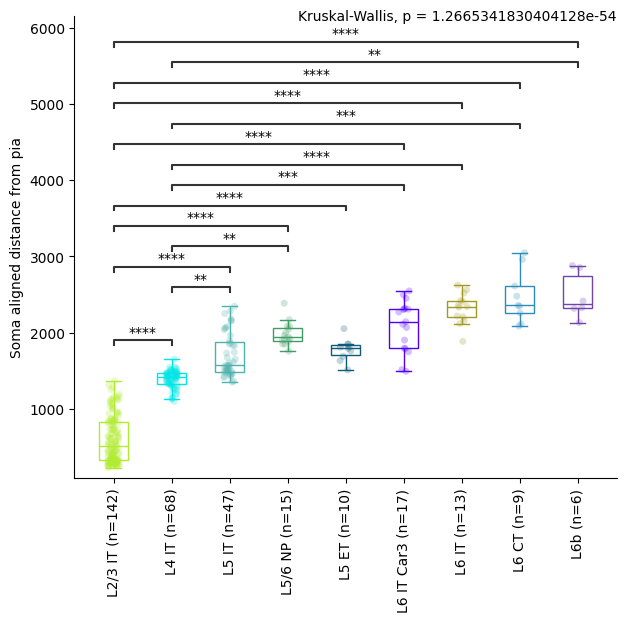

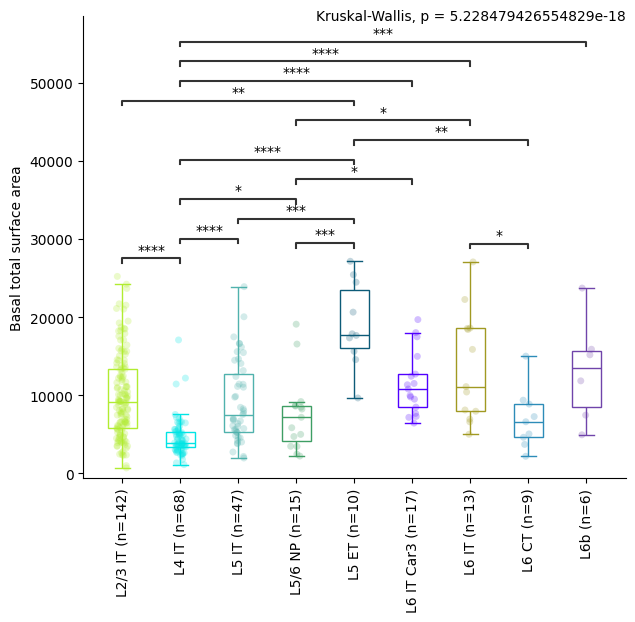

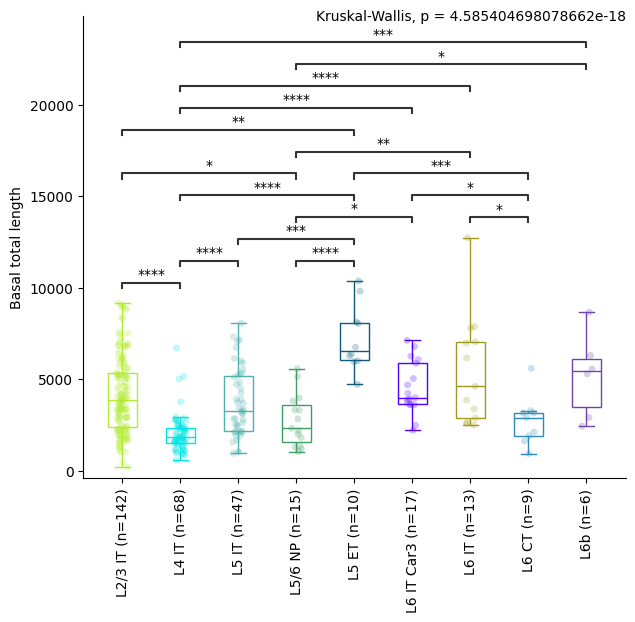

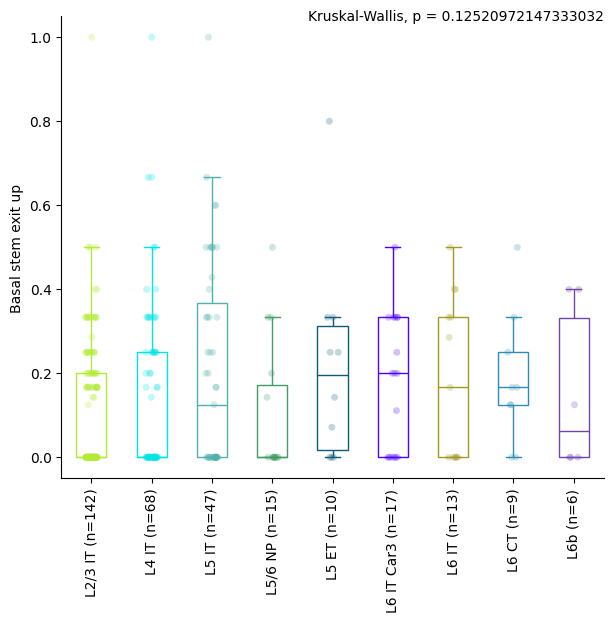

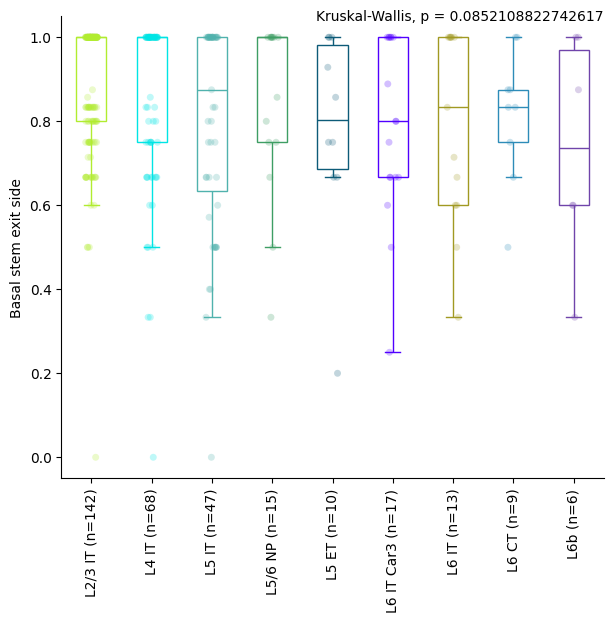

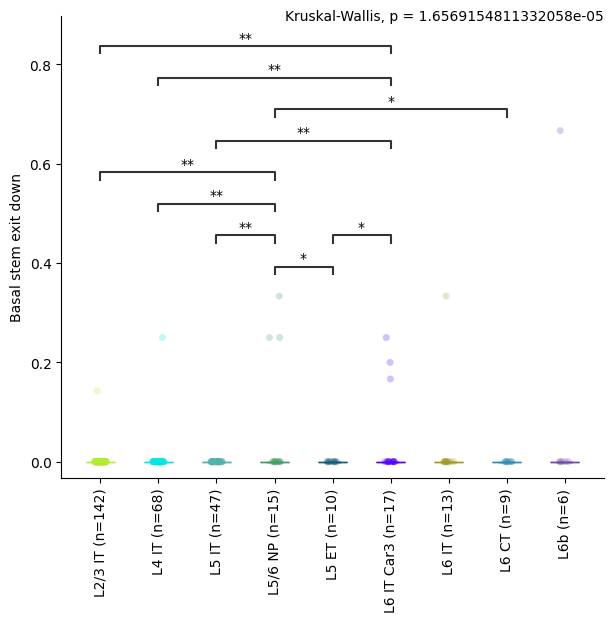

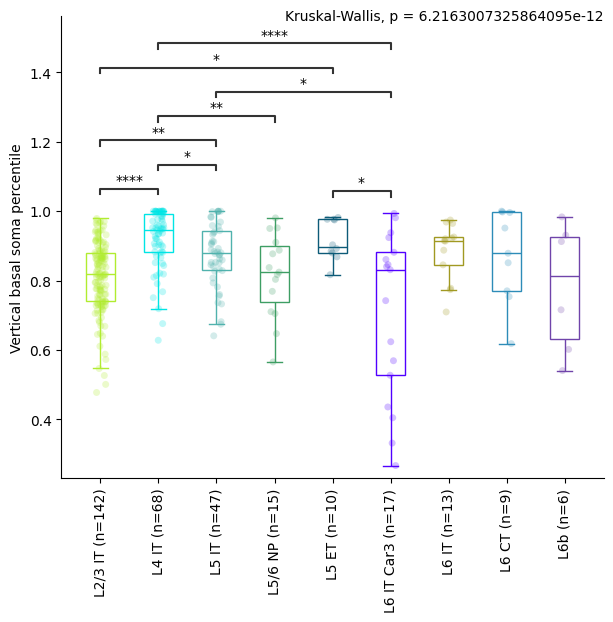

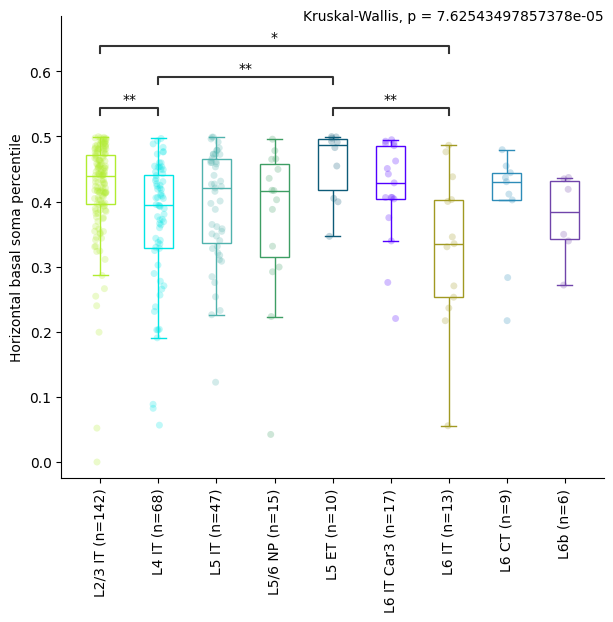

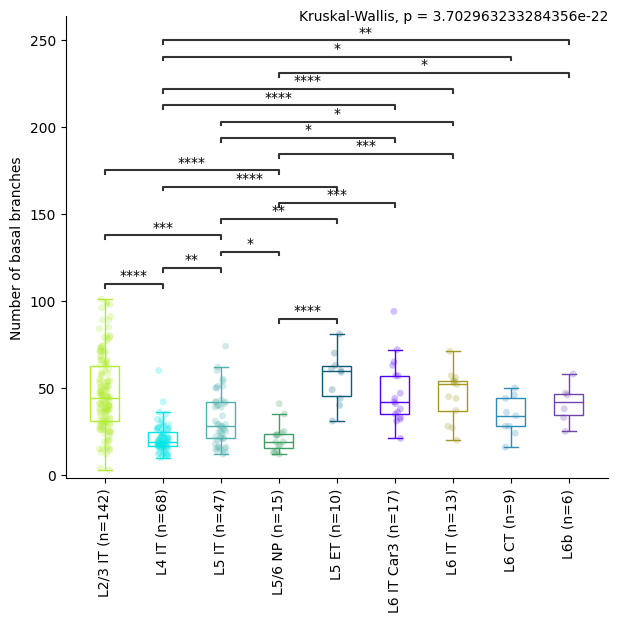

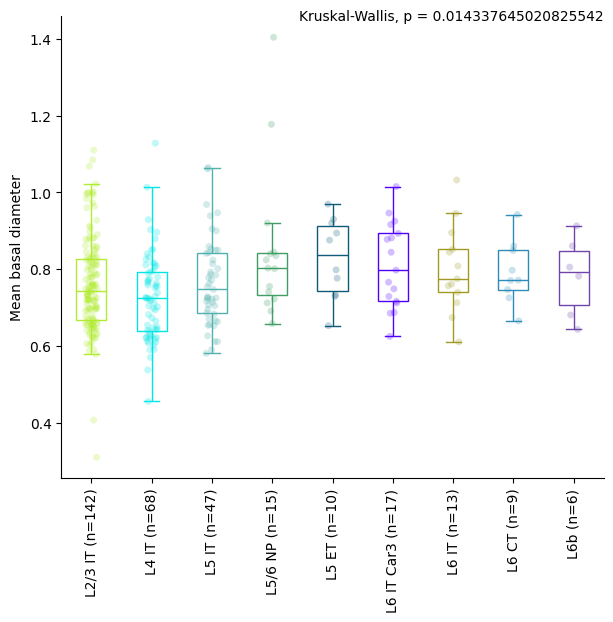

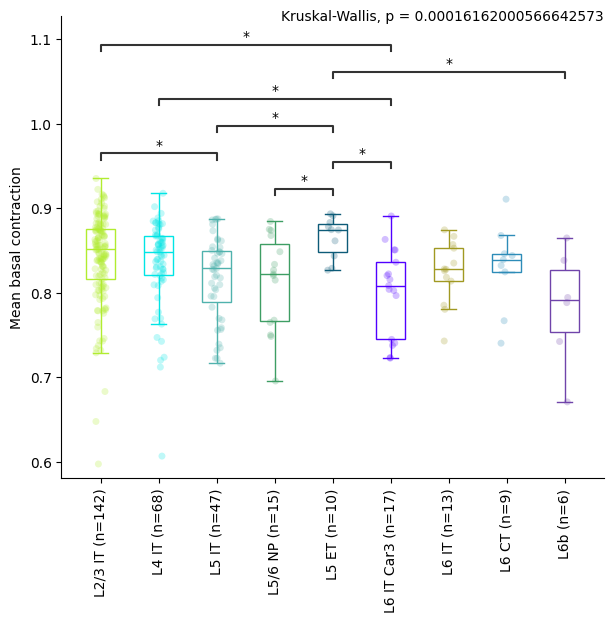

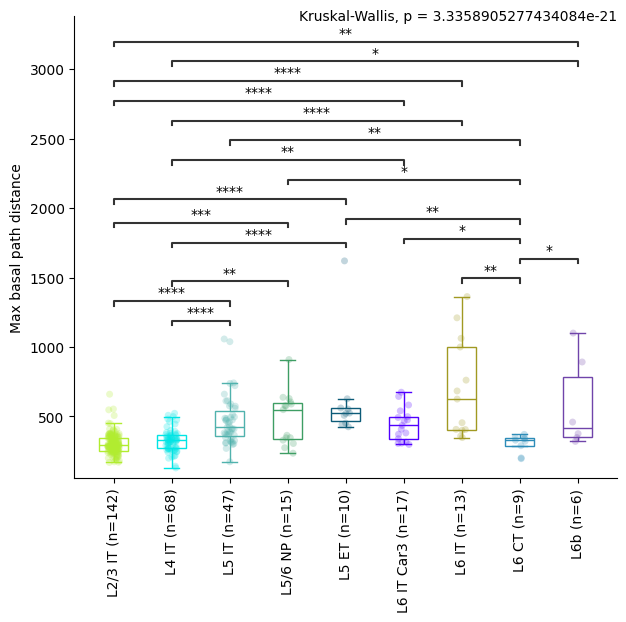

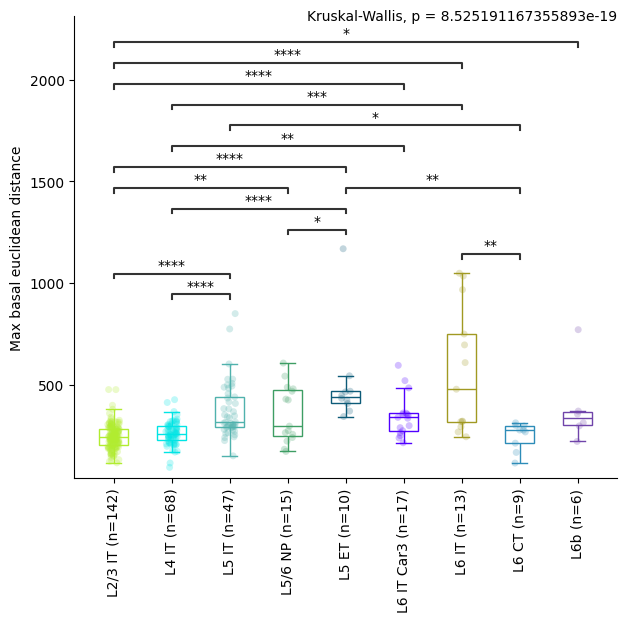

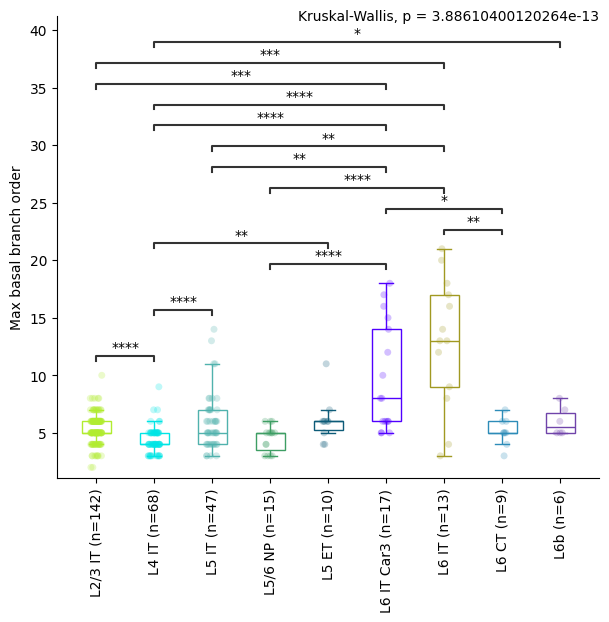

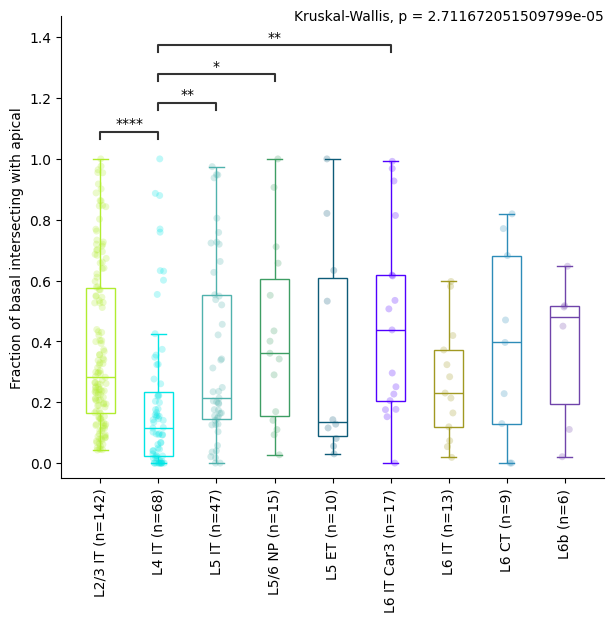

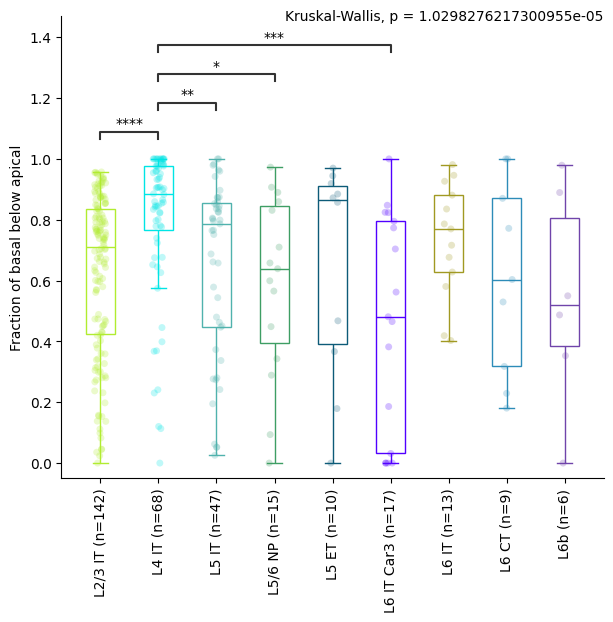

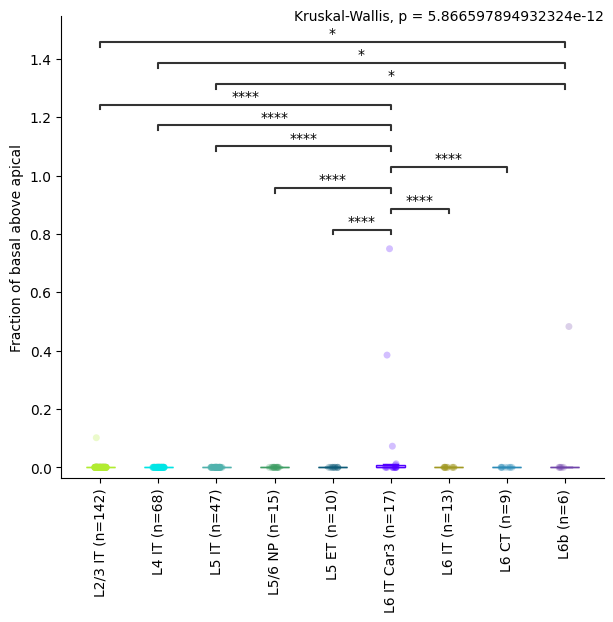

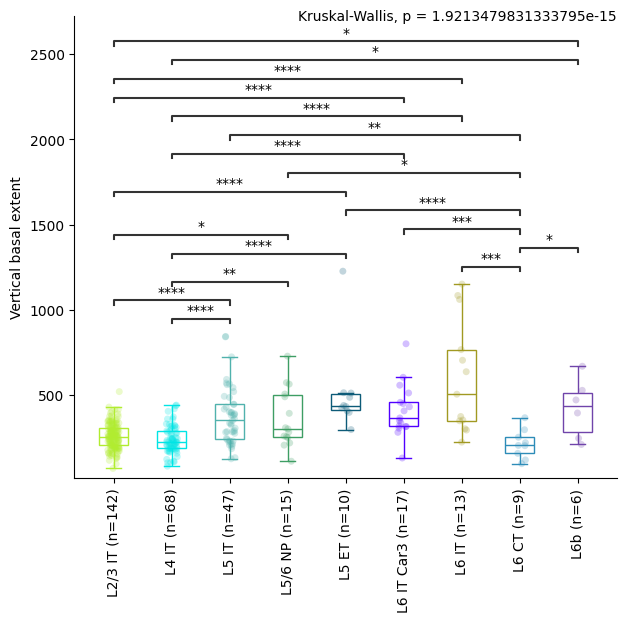

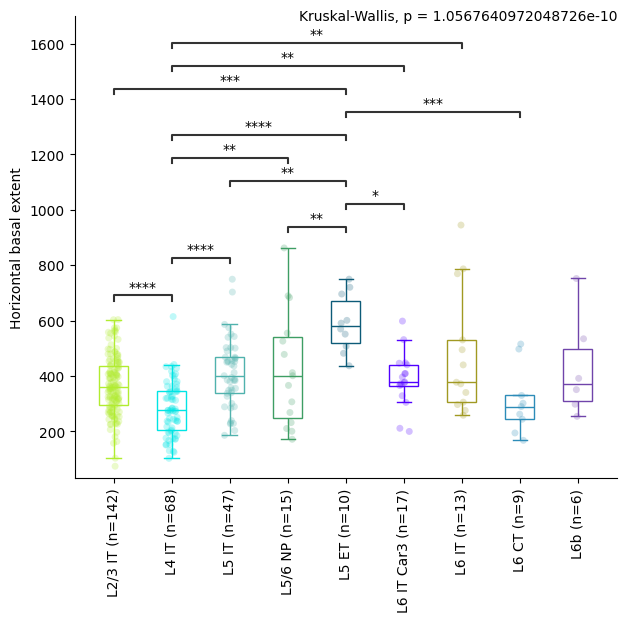

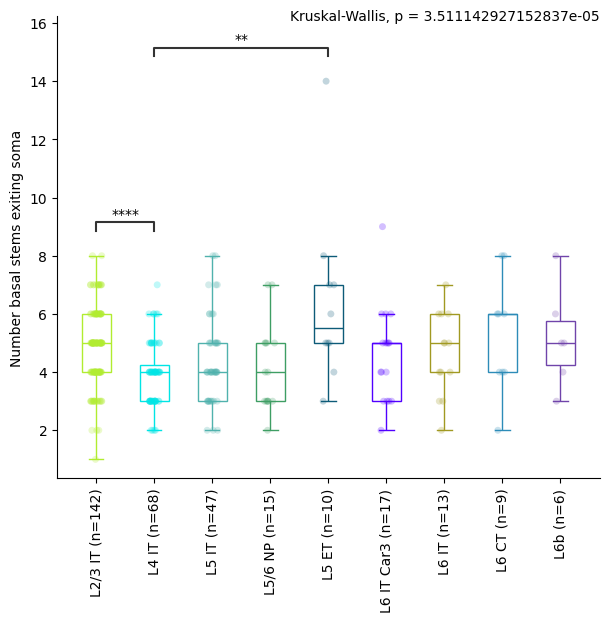

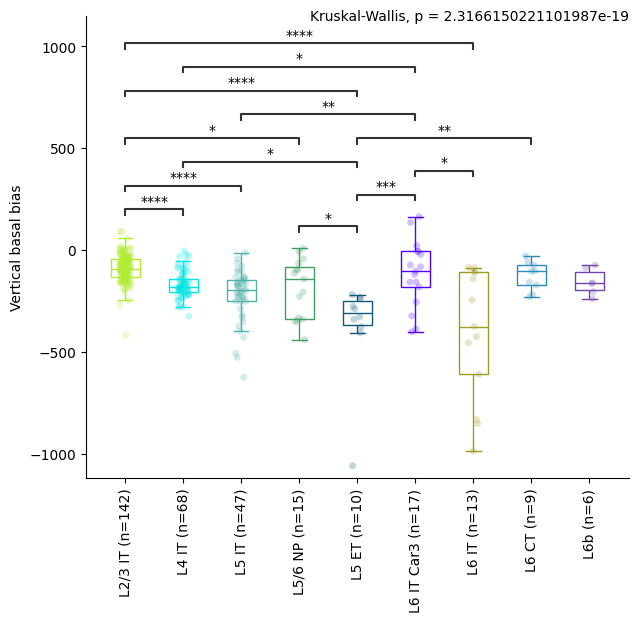

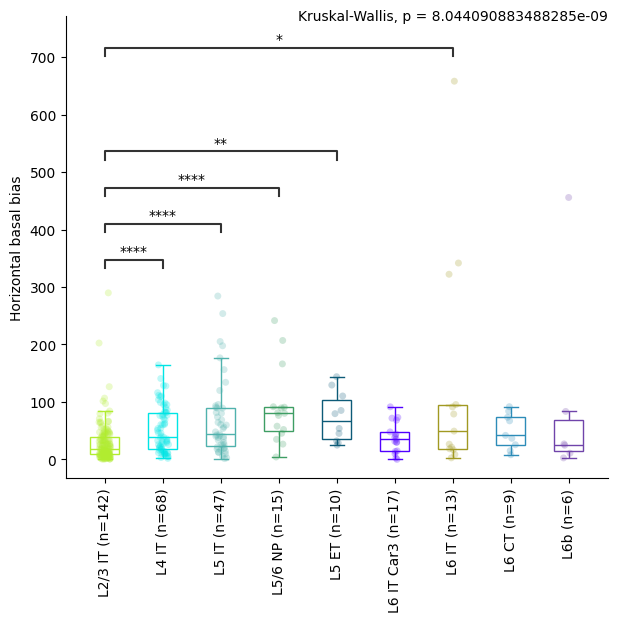

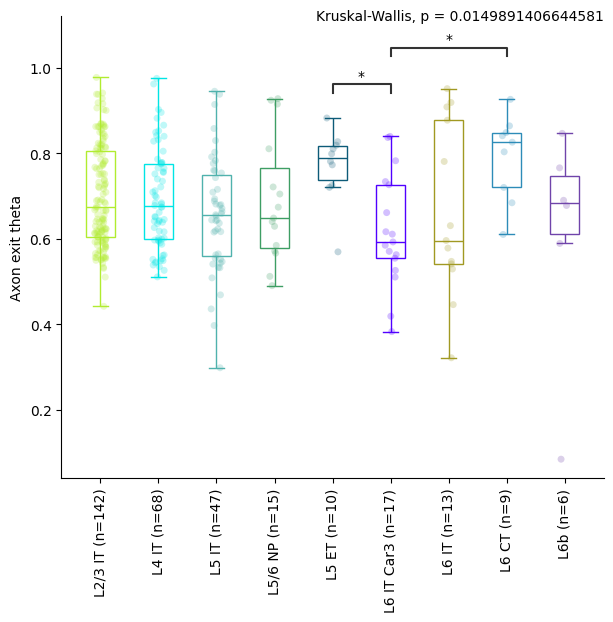

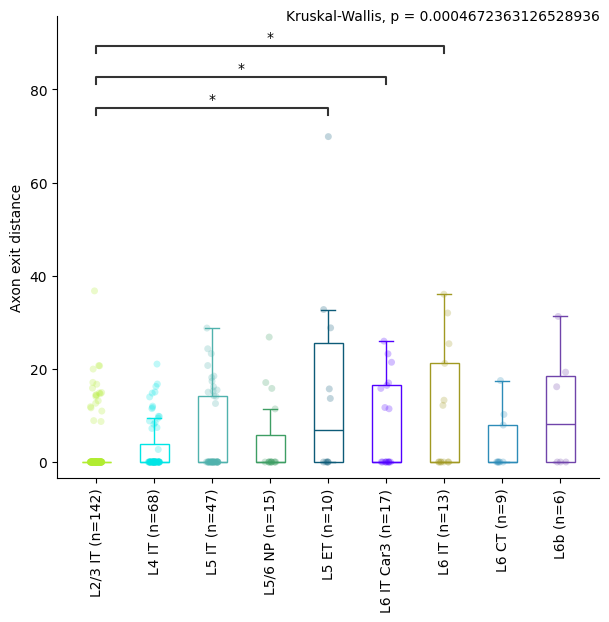

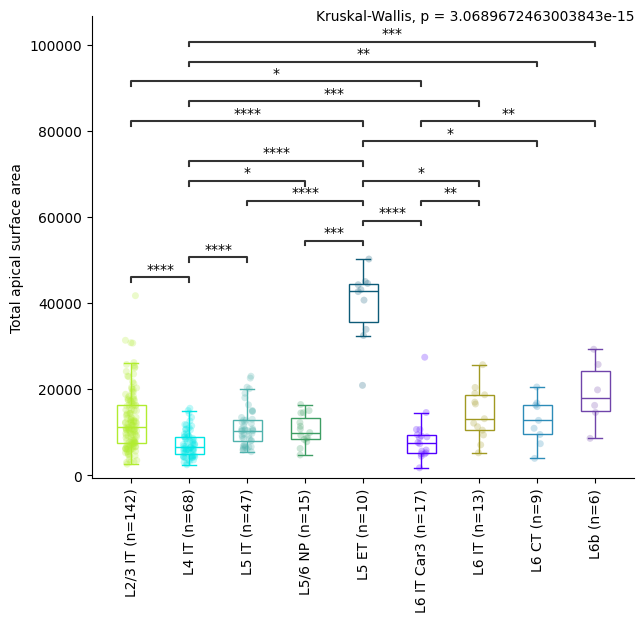

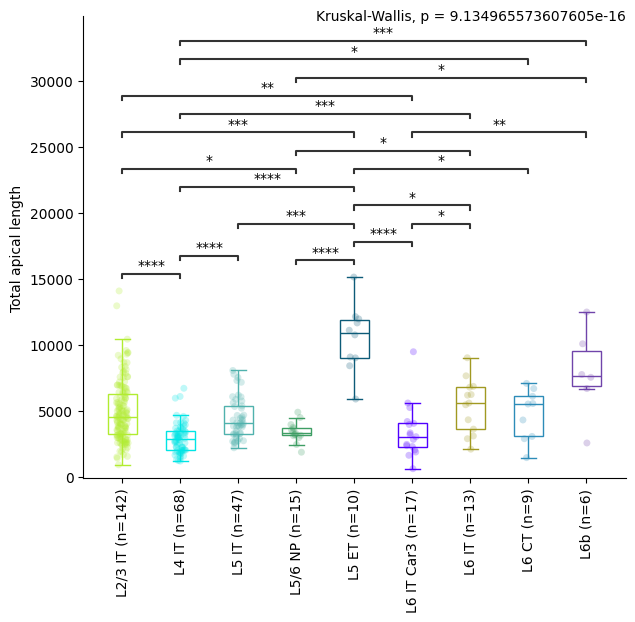

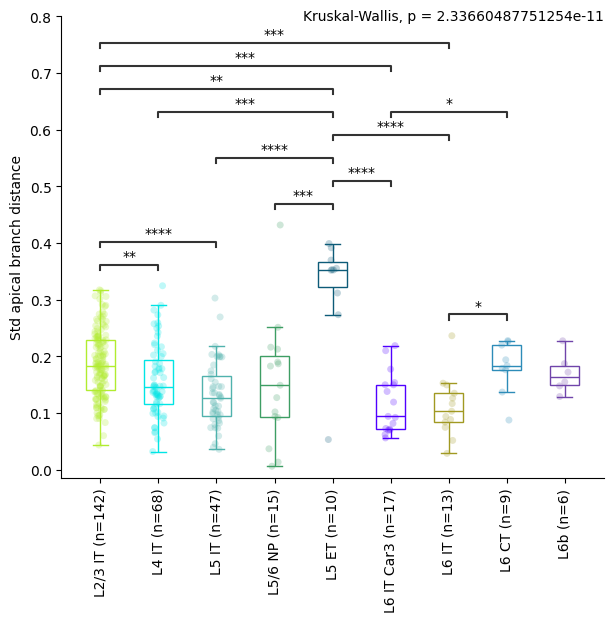

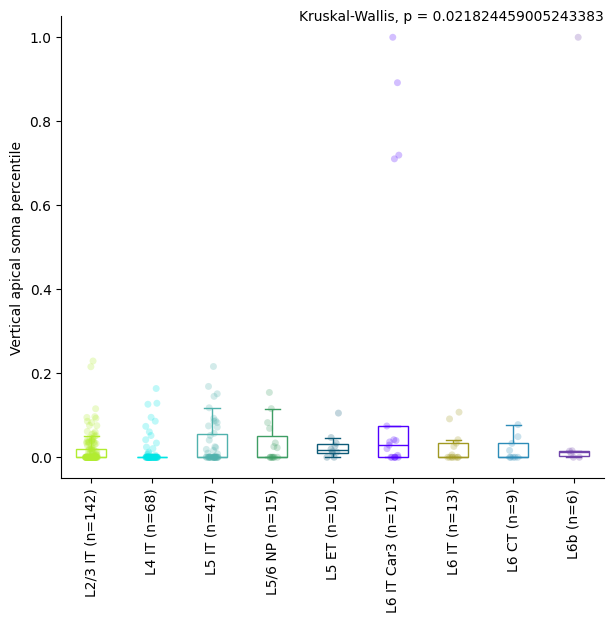

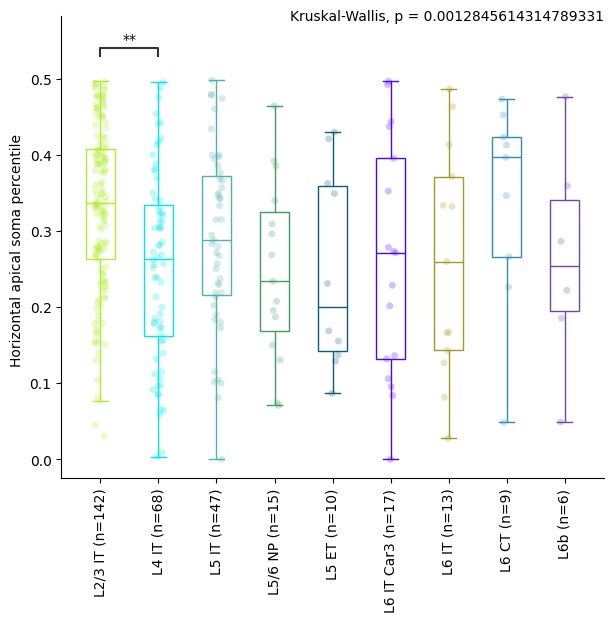

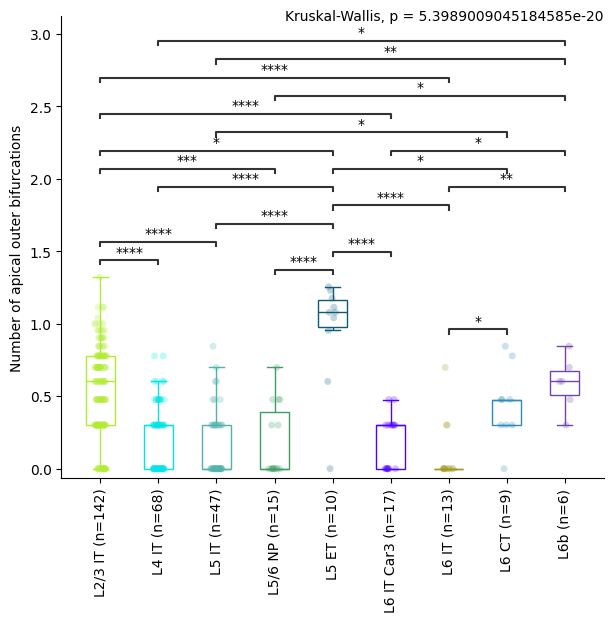

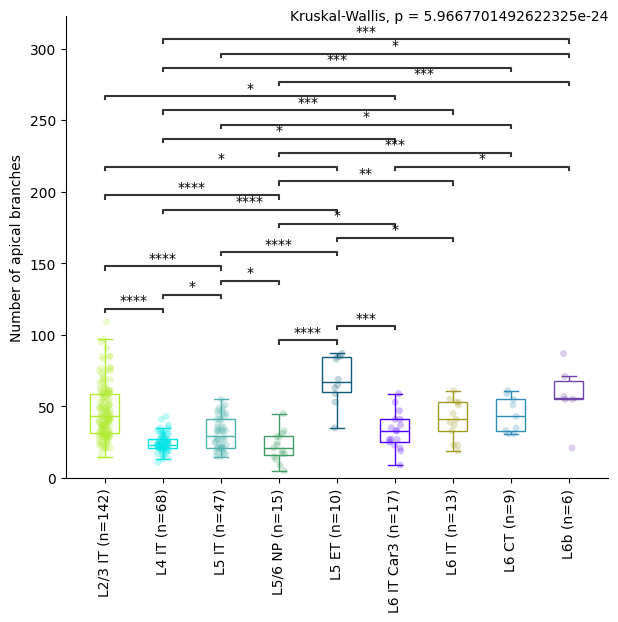

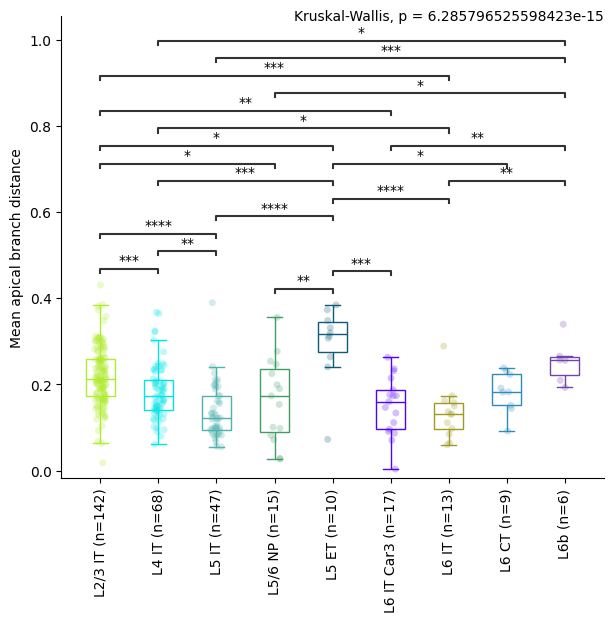

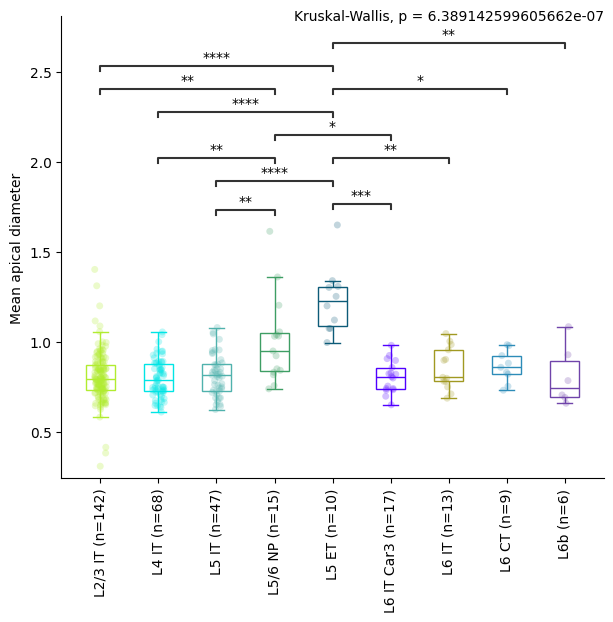

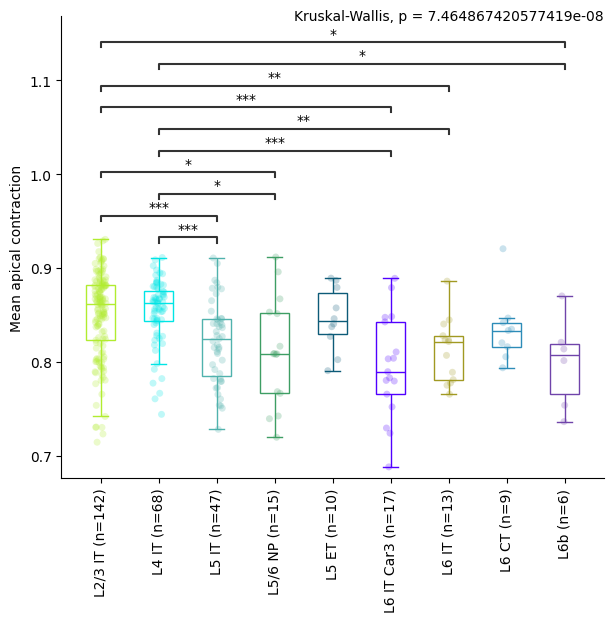

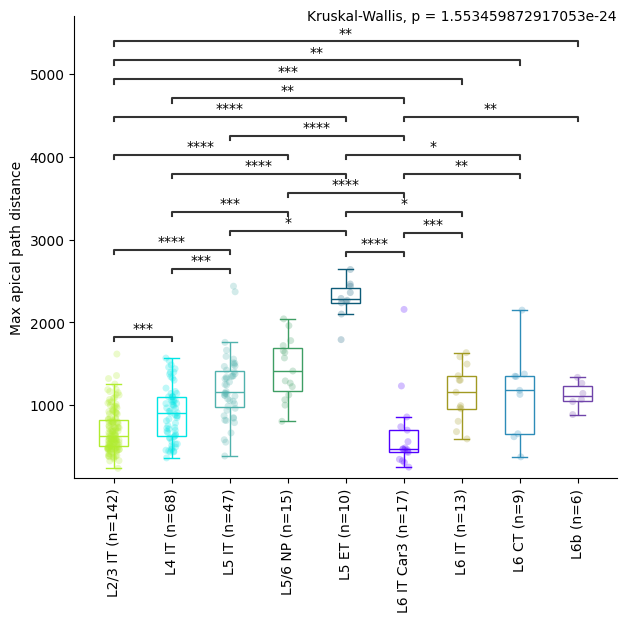

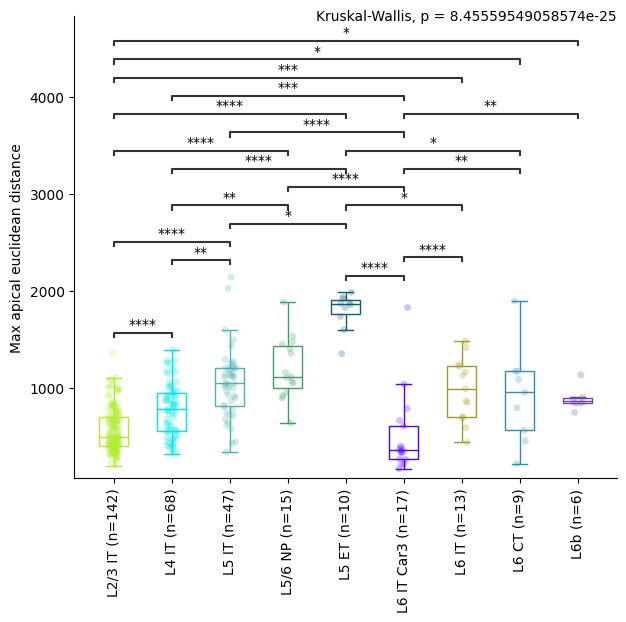

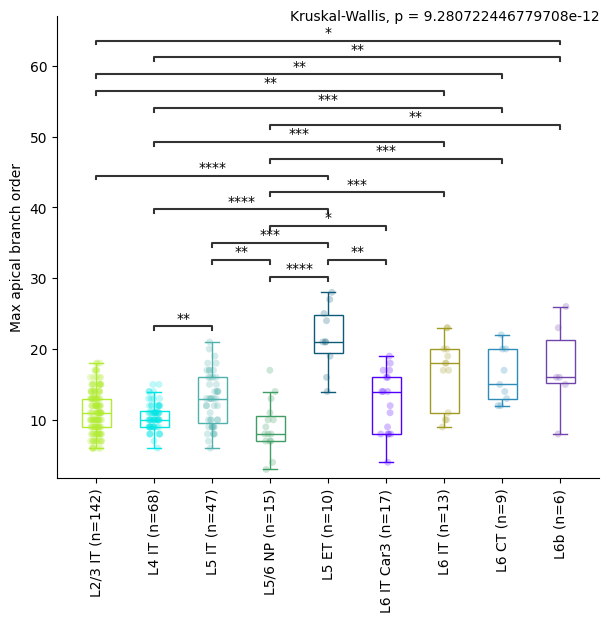

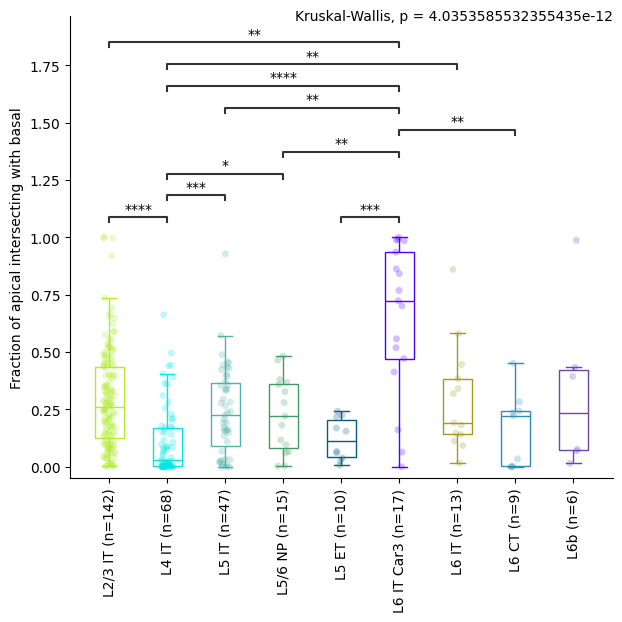

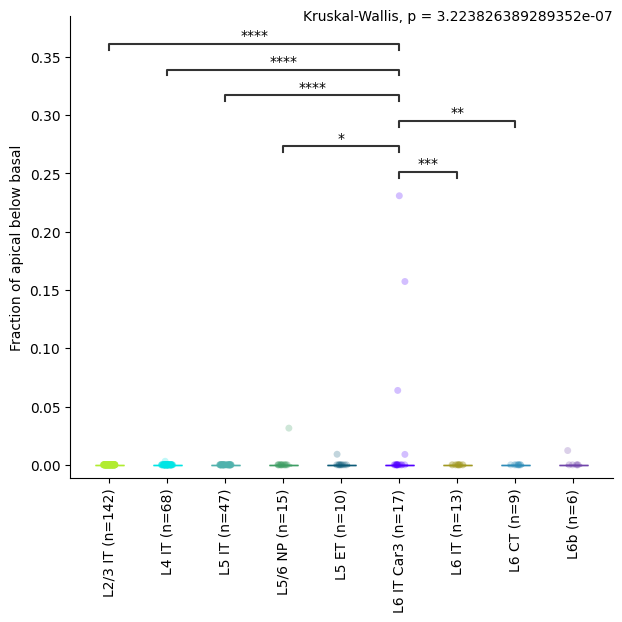

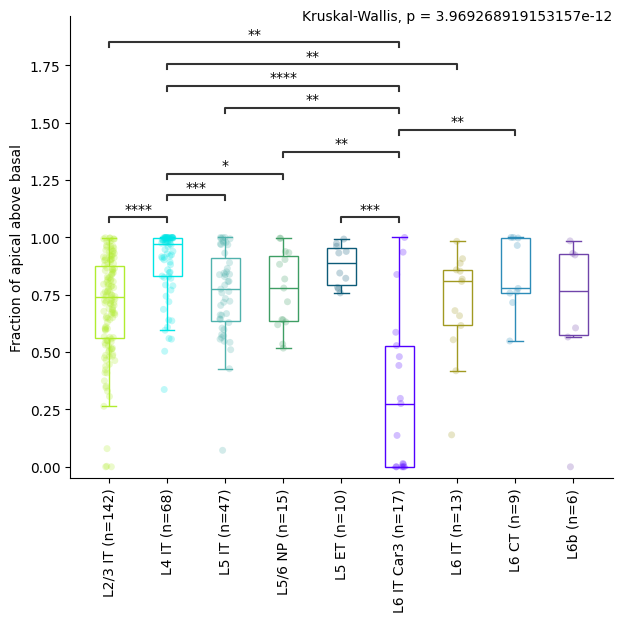

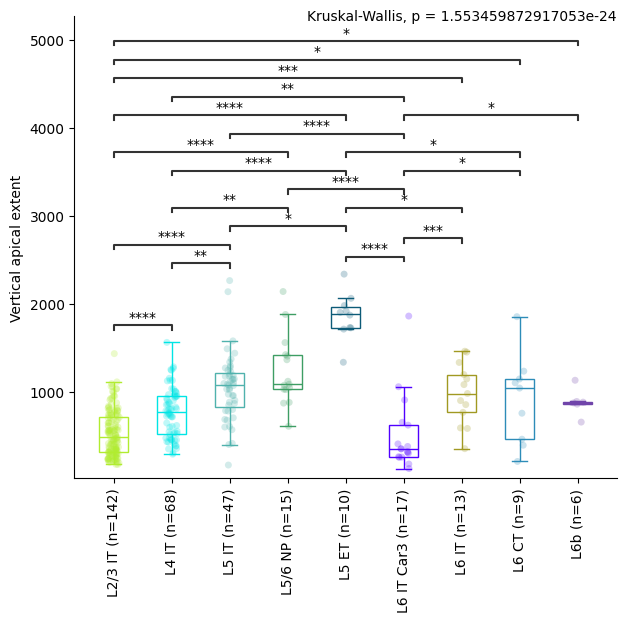

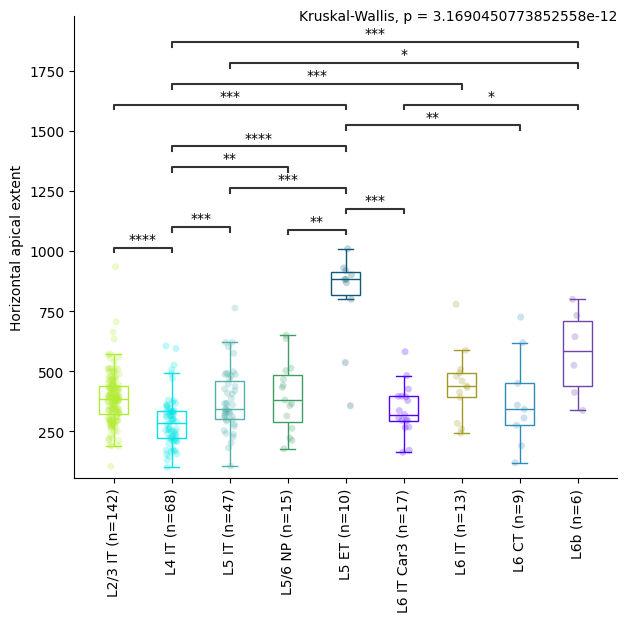

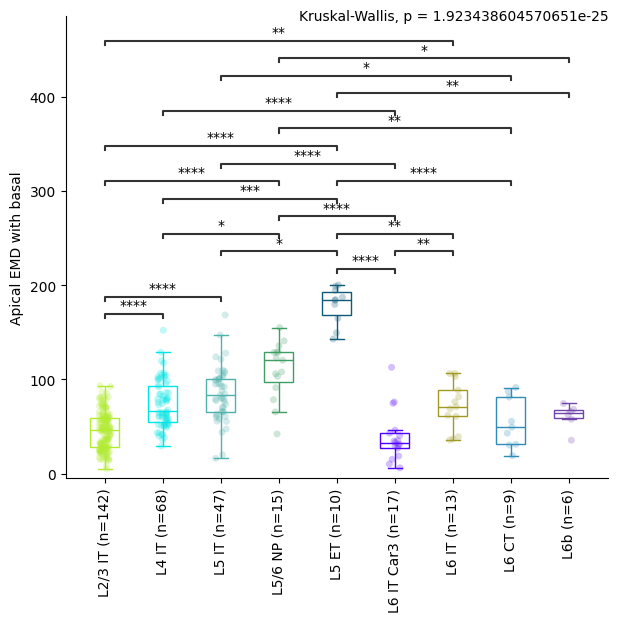

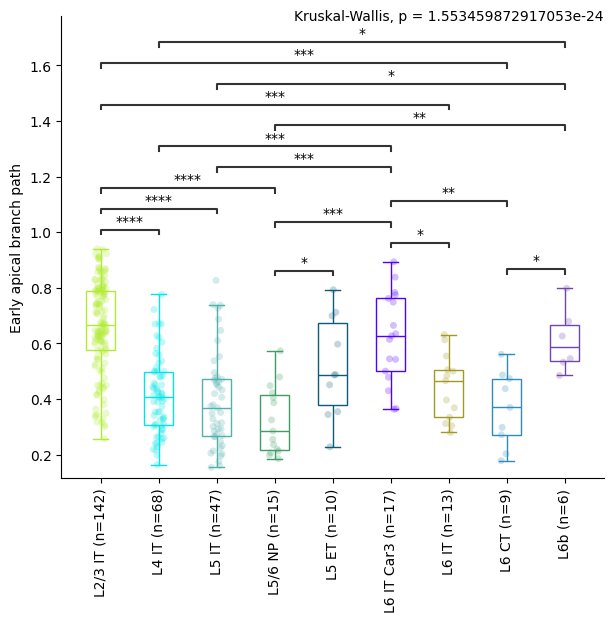

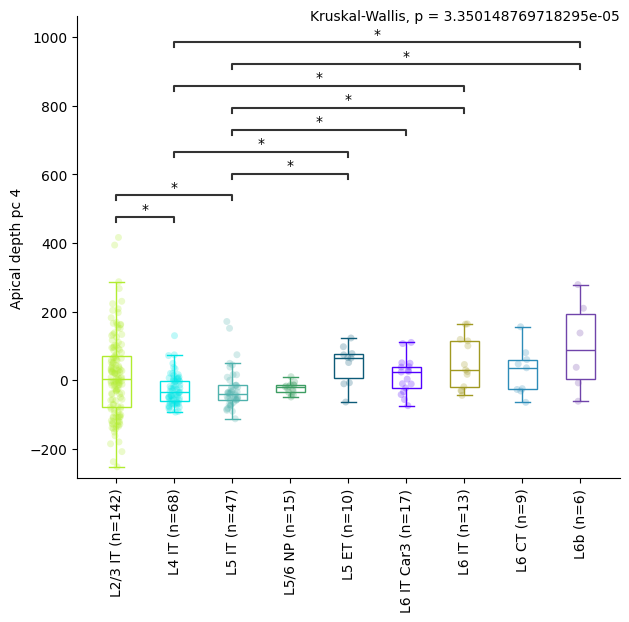

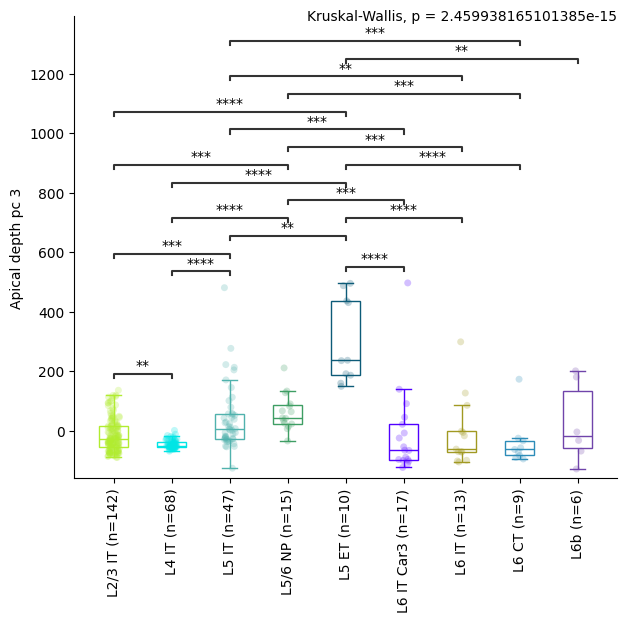

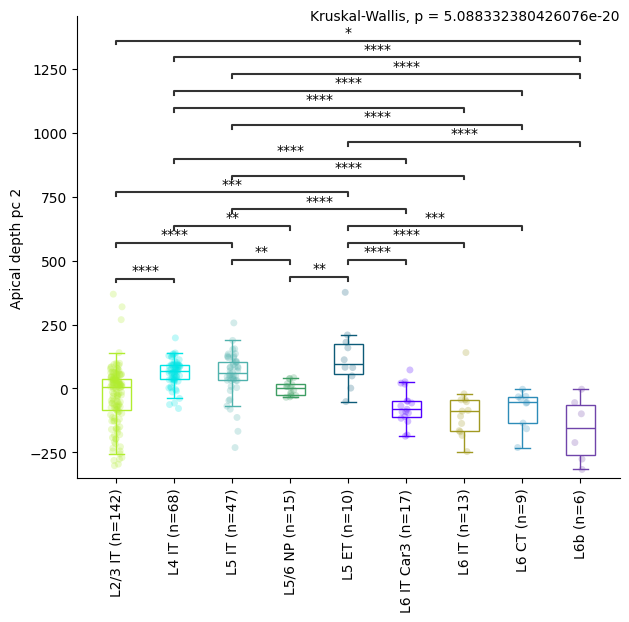

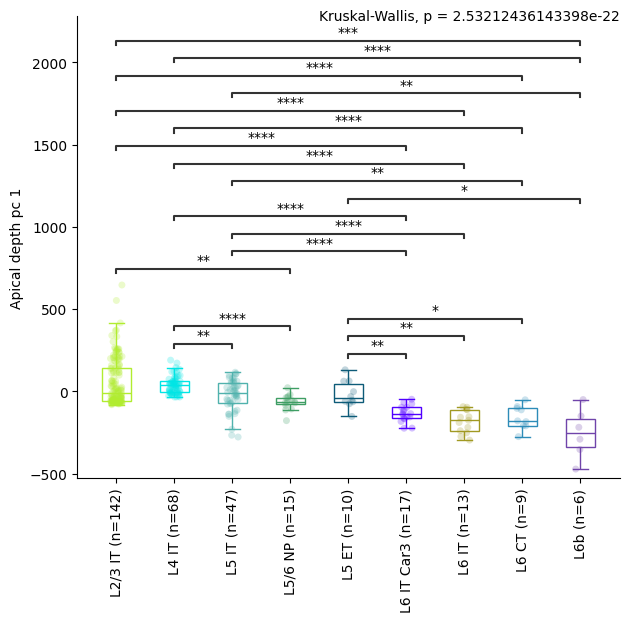

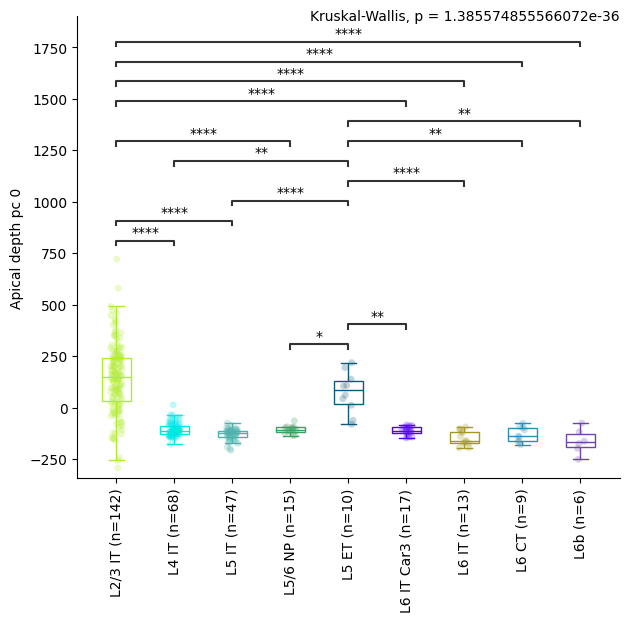

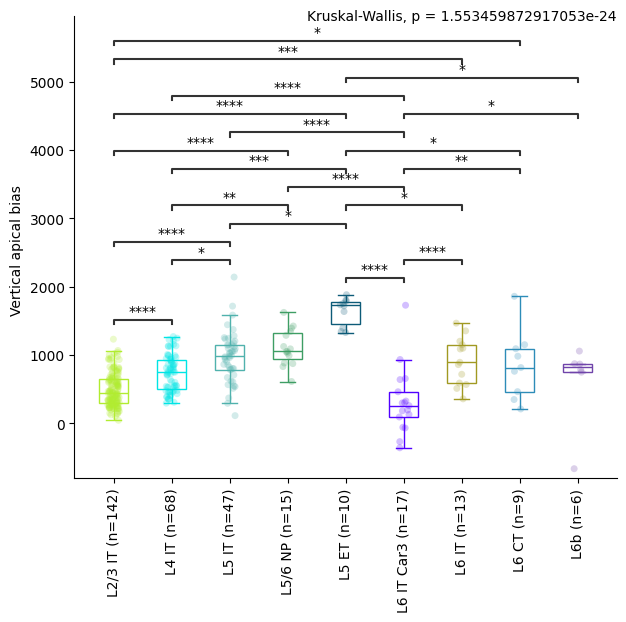

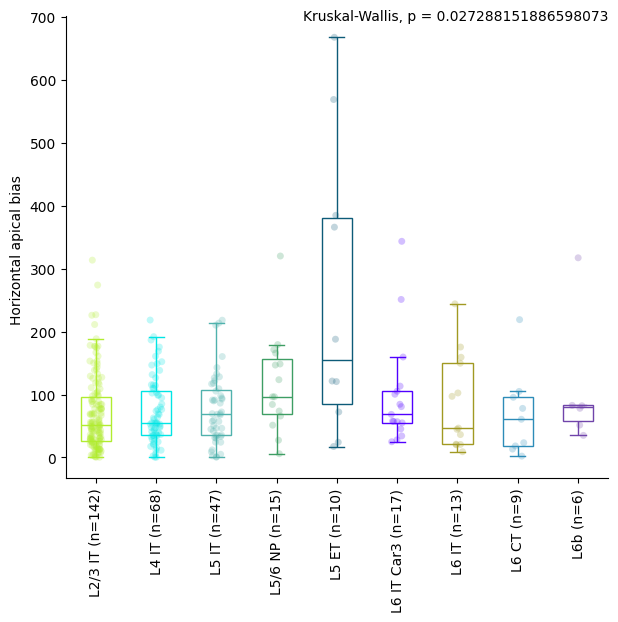

<Figure size 640x480 with 0 Axes>

In [7]:
# subclass x feature box plots

#ADJUST VARS
fig_name = 'human_excitatory_boxplots_dendrite_features_KW_Dunn_FDR_bySubclass.pdf'

color_palette = color_dict #colors for x_var
hue_var = 't_type' #seperate strip plots into these categories 
hue_color_palette = color_dict #color palette for hue_var
##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

#######################

fig_path = os.path.join(output_dir, fig_name)
features = raw_feature_wide.columns.tolist()[1:] 

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        while features != []:
            
            #one fig per page, each has page (fig) has 4 rows. 
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
            # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
            
            y_var = features.pop()
            
            sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
            # sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=hue_color_palette, alpha=0.25, 
            #                   hue=hue_var, dodge=True, jitter=False) #TODO figure out how to do this with no legend
            # ax.legend_.remove()
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
            format_box_plot(ax) #color line not fill of boxplot


            #add num observations per x_var
            nobs = []
            for t in x_var_order:
                n = len(sorted_clean_data[sorted_clean_data[x_var] == t])
                nobs.append(" (n=%s)" % str(n))
            new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
            ax.set_xticklabels(new_x_tick_labels)

            # add stats (KW w/ Dunn post hoc FDR corrected)

            #plot signif dunn fdr p-vals 
            if y_var in dunn_pvals_fdr.keys(): 
                #kw fdr val was signif so there are dunn fdr vals to plot
                
                this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                this_dunn_pvals_fdr[remove] = np.nan
                dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                #set insignificant pvals to nan 
                p_thresh = 0.05 #threshold for plotting p vals 
                dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                #plot bar for all signif fdr corrected dunn p vals 
                pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                if len(pairs): 
                    #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                    p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                    annotator = Annotator(ax=ax, pairs=pairs, data=sorted_clean_data, x=x_var, y=y_var, order=x_var_order)
                    annotator.configure(text_format="star", loc="inside") #text_format="simple"
                    annotator.set_pvalues_and_annotate(p_values)
                    
            #plot Kruskal-Wallis fdr p-vals
            if y_var in kw_pvals_fdr.keys():
                xlimit = ax.get_xlim()
                ylimit = ax.get_ylim()
                p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

            #rotate and format x_var labels 
            ax.set(xlabel=None)
            ax.tick_params(axis='x', rotation=90)
            ax.set_ylabel(y_var.replace("_", " "), rotation=90)
            ax.spines[['right', 'top']].set_visible(False)

            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf()
        print()



In [8]:
# save stats

combined_rows = []

for feature in kw_pvals:
    kw_info = {
        "feature": feature,
        "KW_H_statistic": kw_hvals[feature],
        "KW_p_value": kw_pvals[feature],
        "KW_p_value_fdr": kw_pvals_fdr[feature],
        "KW_significant_fdr": kw_rejected[feature],
    }

    if feature in dunn_pvals_fdr:
        dunn_matrix = dunn_pvals_fdr[feature]

        for i, group_1 in enumerate(dunn_matrix.index):
            for j, group_2 in enumerate(dunn_matrix.columns):
                # Exclude self-comparisons and duplicate comparisons
                if j > i:
                    dunn_p = dunn_matrix.loc[group_1, group_2]

                    combined_rows.append({
                        **kw_info,
                        "group_1": group_1,
                        "group_2": group_2,
                        "Dunn_p_value_fdr": dunn_p,
                        "Dunn_significant_fdr": dunn_p < 0.05,
                    })
    else:
        # Retain features that did not receive a Dunn test
        combined_rows.append({
            **kw_info,
            "group_1": None,
            "group_2": None,
            "Dunn_p_value_fdr": None,
            "Dunn_significant_fdr": None,
        })

combined_results = pd.DataFrame(combined_rows)

combined_results = combined_results.sort_values(
    ["KW_p_value_fdr", "feature", "Dunn_p_value_fdr"],
    na_position="last"
)

combined_results.to_csv(
    fig_path.replace('.pdf', '.csv'),
    index=False
)

T-type x feature box plots with stats

In [ ]:
# ttype x feature stats

x_var = 't_type'  # what to do box plots on
x_var_order = [x for x in group_order[x_var] if x in sorted_clean_data[x_var].tolist()]

features = raw_feature_wide.columns.tolist()[1:]

# Kruskal-Wallis H test on all features
kw_pvals = dict()
kw_hvals = dict()
for f in features:
    # Create a list of groups dynamically
    groups = [sorted_clean_data.loc[sorted_clean_data[x_var] == x][f].dropna() for x in x_var_order]
    
    # Only include groups that have data
    groups = [group for group in groups if not group.empty]

    if len(groups) < 2:
        print(f"Not enough groups with data for feature {f}")
        continue
    try:
        hvalue, pvalue = kruskal(*groups, nan_policy='omit')
        kw_hvals[f] = hvalue
        kw_pvals[f] = pvalue
    except ValueError as e:
        print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

# FDR correction
kw_pvals_list = list(kw_pvals.values())
kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

# Post Hoc Dunn test for significant KW features, with FDR correction
dunn_pvals_fdr = dict()
for k, v in kw_rejected.items():
    if v:  # if null hypothesis was rejected, calculate Dunn post hoc
        dunn_pvals_fdr[k] = posthoc_dunn(sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)

In [ ]:
# ttype x feature box plots

#ADJUST VARS
fig_name = 'human_excitatory_boxplots_dendrite_features_KW_Dunn_FDR_byTtype.pdf'
color_palette = color_dict #colors for x_var
hue_var = 't_type' #seperate strip plots into these categories 
hue_color_palette = color_dict #color palette for hue_var
##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

#######################

fig_path = os.path.join(output_dir, fig_name)
features = raw_feature_wide.columns.tolist()[1:]

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        while features != []:
            
            #one fig per page, each has page (fig) has 4 rows. 
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
            # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
            
            y_var = features.pop()
            
            sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
            # sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=hue_color_palette, alpha=0.25, 
            #                   hue=hue_var, dodge=True, jitter=False) #TODO figure out how to do this with no legend
            # ax.legend_.remove()
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
            format_box_plot(ax) #color line not fill of boxplot


            #add num observations per x_var
            nobs = []
            for t in x_var_order:
                n = len(sorted_clean_data[sorted_clean_data[x_var] == t])
                nobs.append(" (n=%s)" % str(n))
            new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
            ax.set_xticklabels(new_x_tick_labels)

            # add stats (KW w/ Dunn post hoc FDR corrected)

            #plot signif dunn fdr p-vals 
            if y_var in dunn_pvals_fdr.keys(): 
                #kw fdr val was signif so there are dunn fdr vals to plot
                
                this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                this_dunn_pvals_fdr[remove] = np.nan
                dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                #set insignificant pvals to nan 
                p_thresh = 0.05 #threshold for plotting p vals 
                dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                #plot bar for all signif fdr corrected dunn p vals 
                pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                if len(pairs): 
                    #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                    p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                    annotator = Annotator(ax, pairs, data=sorted_clean_data, x=x_var, y=y_var, order=x_var_order)
                    annotator.configure(text_format="star", loc="inside") #text_format="simple"
                    annotator.set_pvalues_and_annotate(p_values)
                    
            #plot Kruskal-Wallis fdr p-vals
            if y_var in kw_pvals_fdr.keys():
                xlimit = ax.get_xlim()
                ylimit = ax.get_ylim()
                p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

            #rotate and format x_var labels 
            ax.set(xlabel=None)
            ax.tick_params(axis='x', rotation=90)
            ax.set_ylabel(y_var.replace("_", " "), rotation=90)
            ax.spines[['right', 'top']].set_visible(False)

            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf()
        print()



T-Types within each Subclass x feature box plots with stats

In [ ]:
#ttypes within each subclass

features = raw_feature_wide.columns.tolist()[1:]
ttype_order = group_order['t_type']

# subclass x feature stats
subcalss_var = 'subclass_label' #what to do box plots on 
subclass_var_order = group_order['subclass_label']


kw_pvals_fdr_subclass = dict()
dunn_pvals_fdr_subclass = dict()
for subclass in subclass_var_order:
    print(subclass)
    subclass_data = sorted_clean_data.loc[sorted_clean_data[subcalss_var] == subclass]

    #now run stats on the ttypes in this subclass 
    x_var = 't_type'  # what to do box plots on
    x_var_order = [t for t in ttype_order if t in subclass_data[x_var].unique()]

    # Kruskal-Wallis H test on all features
    kw_hvals = dict()
    kw_pvals = dict()
    for f in features:
        # Create a list of groups dynamically
        groups = [subclass_data.loc[subclass_data[x_var] == x][f].dropna() for x in x_var_order]
        
        # Only include groups that have data
        groups = [group for group in groups if not group.empty]

        if len(groups) < 2:
            print(f"Not enough groups with data for feature {f}")
            continue
        try:
            hvalue, pvalue = kruskal(*groups, nan_policy='omit')
            kw_hvals[f] = hvalue
            kw_pvals[f] = pvalue
        except ValueError as e:
            print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

    # FDR correction
    kw_pvals_list = list(kw_pvals.values())
    kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

    kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
    kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

    # Post Hoc Dunn test for significant KW features, with FDR correction
    dunn_pvals_fdr = dict()
    for k, v in kw_rejected.items():
        if v:  # if null hypothesis was rejected, calculate Dunn post hoc
            dunn_pvals_fdr[k] = posthoc_dunn(subclass_data[subclass_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)

    kw_pvals_fdr_subclass[subclass] = kw_pvals_fdr
    dunn_pvals_fdr_subclass[subclass] = dunn_pvals_fdr

In [ ]:
# ttype x feature box plots

ttype_order = group_order['t_type']

for subclass in kw_pvals_fdr_subclass.keys():
    if kw_pvals_fdr_subclass[subclass]:
        #subclass has results (there were enough ttypes in the subclass, etc.)
        subclass_data = sorted_clean_data.loc[sorted_clean_data[subcalss_var] == subclass]
        kw_pvals_fdr = kw_pvals_fdr_subclass[subclass]  
        dunn_pvals_fdr = dunn_pvals_fdr_subclass[subclass]
        x_var = 't_type'  # what to do box plots on
        x_var_order = [t for t in ttype_order if t in subclass_data[x_var].unique()]

        #ADJUST VARS
        fig_name = 'human_excitatory_boxplots_dendrite_features_KW_Dunn_FDR_{}_byTtype.pdf'.format(subclass.replace('/', '-').replace(' ', '_'))
        color_palette = color_dict #colors for x_var
        hue_var = 't_type' #seperate strip plots into these categories 
        hue_color_palette = color_dict #color palette for hue_var
        ##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

        #######################

        fig_path = os.path.join(output_dir, fig_name)
        features = raw_feature_wide.columns.tolist()[1:]

        with warnings.catch_warnings():
            warnings.simplefilter(action='ignore', category=FutureWarning)

            with PdfPages(fig_path) as pdf:
                while features != []:
                    
                    #one fig per page, each has page (fig) has 4 rows. 
                    fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
                    # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
                    
                    y_var = features.pop()
                    
                    sns.stripplot(data=subclass_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
                    sns.boxplot(data=subclass_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
                    format_box_plot(ax) #color line not fill of boxplot


                    #add num observations per x_var
                    nobs = []
                    for t in x_var_order:
                        n = len(subclass_data[subclass_data[x_var] == t])
                        nobs.append(" (n=%s)" % str(n))
                    new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
                    ax.set_xticklabels(new_x_tick_labels)

                    # add stats (KW w/ Dunn post hoc FDR corrected)

                    #plot signif dunn fdr p-vals 
                    if y_var in dunn_pvals_fdr.keys(): 
                        #kw fdr val was signif so there are dunn fdr vals to plot
                        
                        this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                        remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                        this_dunn_pvals_fdr[remove] = np.nan
                        dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                        #set insignificant pvals to nan 
                        p_thresh = 0.05 #threshold for plotting p vals 
                        dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                        #plot bar for all signif fdr corrected dunn p vals 
                        pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                        if len(pairs): 
                            #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                            p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                            annotator = Annotator(ax, pairs, data=subclass_data, x=x_var, y=y_var, order=x_var_order)
                            annotator.configure(text_format="star", loc="inside") #text_format="simple"
                            annotator.set_pvalues_and_annotate(p_values)
                            
                    #plot Kruskal-Wallis fdr p-vals
                    if y_var in kw_pvals_fdr.keys():
                        xlimit = ax.get_xlim()
                        ylimit = ax.get_ylim()
                        p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                        ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

                    #rotate and format x_var labels 
                    ax.set(xlabel=None)
                    ax.tick_params(axis='x', rotation=90)
                    ax.set_ylabel(y_var.replace("_", " "), rotation=90)
                    ax.spines[['right', 'top']].set_visible(False)

                    fig.subplots_adjust(wspace=0, hspace=0.0)
                    pdf.savefig(dpi=600, bbox_inches='tight')
                plt.show()
                plt.clf()
                print()



T-Types within each Layer x feature box plots with stats

In [ ]:
#ttypes within each layer

ttype_order = group_order['t_type']
features = raw_feature_wide.columns.tolist()[1:]

# layer x feature stats
layer_var = 'layer' #what to do box plots on 
layer_var_order = group_order[layer_var]

kw_pvals_fdr_layer = dict()
dunn_pvals_fdr_layer = dict()
for layer in layer_var_order:
    print(layer)
    layer_data = sorted_clean_data.loc[sorted_clean_data[layer_var] == layer]

    #now run stats on the ttypes in this layer 
    x_var = 't_type'  # what to do box plots on
    x_var_order = [t for t in ttype_order if t in layer_data[x_var].unique()]

    # Kruskal-Wallis H test on all features
    kw_hvals = dict()
    kw_pvals = dict()
    for f in features:
        # Create a list of groups dynamically
        groups = [layer_data.loc[layer_data[x_var] == x][f].dropna() for x in x_var_order]
        
        # Only include groups that have data
        groups = [group for group in groups if not group.empty]

        if len(groups) < 2:
            print(f"Not enough groups with data for feature {f}")
            continue
        try:
            hvalue, pvalue = kruskal(*groups, nan_policy='omit')
            kw_hvals[f] = hvalue
            kw_pvals[f] = pvalue
        except ValueError as e:
            print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

    # FDR correction
    kw_pvals_list = list(kw_pvals.values())
    kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

    kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
    kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

    # Post Hoc Dunn test for significant KW features, with FDR correction
    dunn_pvals_fdr = dict()
    for k, v in kw_rejected.items():
        if v:  # if null hypothesis was rejected, calculate Dunn post hoc
            dunn_pvals_fdr[k] = posthoc_dunn(layer_data[layer_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)

    kw_pvals_fdr_layer[layer] = kw_pvals_fdr
    dunn_pvals_fdr_layer[layer] = dunn_pvals_fdr

In [ ]:
#Save stats
rows = []

for layer in layer_var_order:
    kw_dict = kw_pvals_fdr_layer.get(layer, {})
    dunn_dict = dunn_pvals_fdr_layer.get(layer, {})
    
    for feature, kw_p in kw_dict.items():
        # if Dunn exists for this feature
        if feature in dunn_dict:
            dunn_df = dunn_dict[feature]
            # Flatten Dunn results: pairwise comparisons
            for i in dunn_df.index:
                for j in dunn_df.columns:
                    if i != j:  # skip self-comparison
                        rows.append({
                            'layer': layer,
                            'feature': feature,
                            'kw_pval_fdr': kw_p,
                            'group1': i,
                            'group2': j,
                            'dunn_pval_fdr': dunn_df.loc[i, j]
                        })
        else:
            # No post-hoc, just KW
            rows.append({
                'layer': layer,
                'feature': feature,
                'kw_pval_fdr': kw_p,
                'group1': None,
                'group2': None,
                'dunn_pval_fdr': None
            })

# Convert to DataFrame
stats_df = pd.DataFrame(rows)
stats_df.to_csv(os.path.join(output_dir, r'morphology_feature_box_plot_stats_supertypes_within_layer.csv'), index=False)
stats_df

In [ ]:
# ttype x feature box plots

ttype_order = group_order['t_type']

for layer in kw_pvals_fdr_layer.keys():
    if kw_pvals_fdr_layer[layer]:
        #layer has results (there were enough ttypes in the layer, etc.)
        layer_data = sorted_clean_data.loc[sorted_clean_data[layer_var] == layer]
        kw_pvals_fdr = kw_pvals_fdr_layer[layer]  
        dunn_pvals_fdr = dunn_pvals_fdr_layer[layer]
        x_var = 't_type'  # what to do box plots on
        x_var_order = [t for t in ttype_order if t in layer_data[x_var].unique()]

        #ADJUST VARS
        fig_name = 'human_excitatory_boxplots_dendrite_features_KW_Dunn_FDR_{}_byTtype.pdf'.format(layer.replace('/', '-').replace(' ', '_'))
        color_palette = color_dict #colors for x_var
        hue_var = 't_type' #seperate strip plots into these categories 
        hue_color_palette = color_dicts[hue_var] #color palette for hue_var
        ##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

        #######################

        fig_path = os.path.join(output_dir, fig_name)
        features = raw_feature_wide.columns.tolist()[1:]

        with warnings.catch_warnings():
            warnings.simplefilter(action='ignore', category=FutureWarning)

            with PdfPages(fig_path) as pdf:
                while features != []:
                    
                    #one fig per page, each has page (fig) has 4 rows. 
                    fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
                    # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
                    
                    y_var = features.pop()
                    
                    sns.stripplot(data=layer_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
                    sns.boxplot(data=layer_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
                    format_box_plot(ax) #color line not fill of boxplot


                    #add num observations per x_var
                    nobs = []
                    for t in x_var_order:
                        n = len(layer_data[layer_data[x_var] == t])
                        nobs.append(" (n=%s)" % str(n))
                    new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
                    ax.set_xticklabels(new_x_tick_labels)

                    # add stats (KW w/ Dunn post hoc FDR corrected)

                    #plot signif dunn fdr p-vals 
                    if y_var in dunn_pvals_fdr.keys(): 
                        #kw fdr val was signif so there are dunn fdr vals to plot
                        
                        this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                        remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                        this_dunn_pvals_fdr[remove] = np.nan
                        dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                        #set insignificant pvals to nan 
                        p_thresh = 0.05 #threshold for plotting p vals 
                        dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                        #plot bar for all signif fdr corrected dunn p vals 
                        pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                        if len(pairs): 
                            #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                            p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                            annotator = Annotator(ax, pairs, data=layer_data, x=x_var, y=y_var, order=x_var_order)
                            annotator.configure(text_format="star", loc="inside") #text_format="simple"
                            annotator.set_pvalues_and_annotate(p_values)
                            
                    #plot Kruskal-Wallis fdr p-vals
                    if y_var in kw_pvals_fdr.keys():
                        xlimit = ax.get_xlim()
                        ylimit = ax.get_ylim()
                        p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                        ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

                    #rotate and format x_var labels 
                    ax.set(xlabel=None)
                    ax.tick_params(axis='x', rotation=90)
                    ax.set_ylabel(y_var.replace("_", " "), rotation=90)
                    ax.spines[['right', 'top']].set_visible(False)

                    fig.subplots_adjust(wspace=0, hspace=0.0)
                    pdf.savefig(dpi=600, bbox_inches='tight')
                plt.show()
                plt.clf()
                print()



Subclasses within Layer 5

In [6]:
# subclass x feature stats
x_var = 'subclass_label' #what to do box plots on 
x_var_order = [t for t in group_order[x_var] if t.startswith('L5')]

features = raw_feature_wide.columns.tolist()[1:]

# Kruskal-Wallis H test on all features
kw_pvals = dict()
kw_hvals = dict()
for f in features:
    # Create a list of groups dynamically
    groups = [sorted_clean_data.loc[sorted_clean_data[x_var] == x][f].dropna() for x in x_var_order]
    
    # Only include groups that have data
    groups = [group for group in groups if not group.empty]

    if len(groups) < 2:
        print(f"Not enough groups with data for feature {f}")
        continue
    try:
        hvalue, pvalue = kruskal(*groups, nan_policy='omit')
        kw_hvals[f] = hvalue
        kw_pvals[f] = pvalue
    except ValueError as e:
        print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

# FDR correction
kw_pvals_list = list(kw_pvals.values())
kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

# Post Hoc Dunn test for significant KW features, with FDR correction
dunn_pvals_fdr = dict()
for k, v in kw_rejected.items():
    if v:  # if null hypothesis was rejected, calculate Dunn post hoc
        dunn_pvals_fdr[k] = posthoc_dunn(sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)


Kruskal-Wallis not calculated for Fraction of basal above apical because of an error: All numbers are identical in kruskal


/tmp/ipykernel_7320/764491145.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5/6 NP vs. L5 ET: Custom statistical test, P_val:2.006e-04
L5 IT vs. L5 ET: Custom statistical test, P_val:1.950e-04


/tmp/ipykernel_7320/764491145.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7320/764491145.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT vs. L5/6 NP: Custom statistical test, P_val:5.004e-04
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5/6 NP vs. L5 ET: Custom statistical test, P_val:1.205e-04
L5 IT vs. L5 ET: Custom statistical test, P_val:1.205e-04
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5/6 NP vs. L5 ET: Custom statistical test, P_val:2.171e-05


/tmp/ipykernel_7320/764491145.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


L5 IT vs. L5 ET: Custom statistical test, P_val:1.495e-04


... (49 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5/6 NP vs. L5 ET: Custom statistical test, P_val:7.718e-03
L5 IT vs. L5/6 NP: Custom statistical test, P_val:7.718e-03
L5 IT vs. L5 ET: Custom statistical test, P_val:1.457e-07


/tmp/ipykernel_7320/764491145.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5/6 NP vs. L5 ET: Custom statistical test, P_val:3.558e-03
L5 IT vs. L5 ET: Custom statistical test, P_val:7.572e-06
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT vs. L5 ET: Custom statistical test, P_val:3.740e-02


/tmp/ipykernel_7320/764491145.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


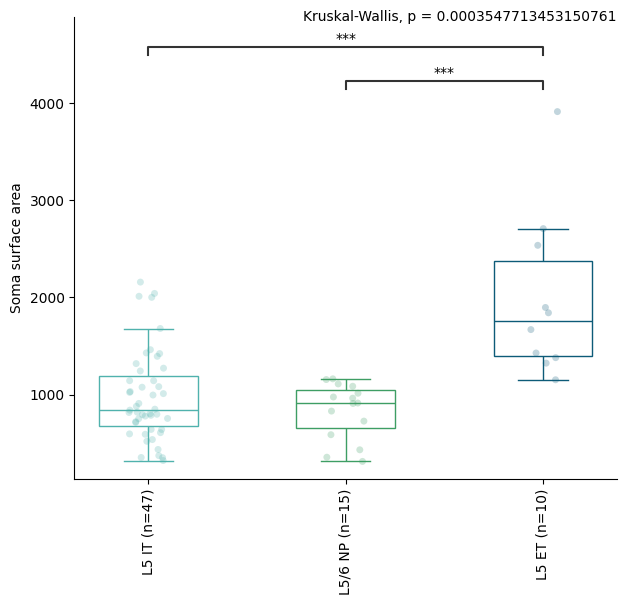

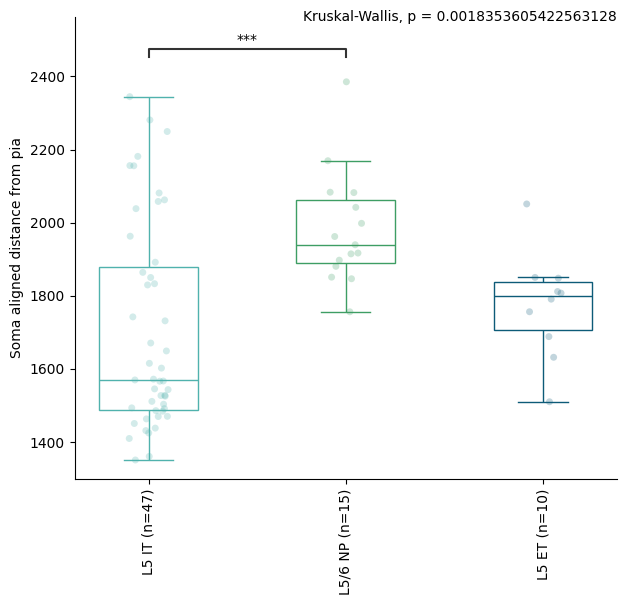

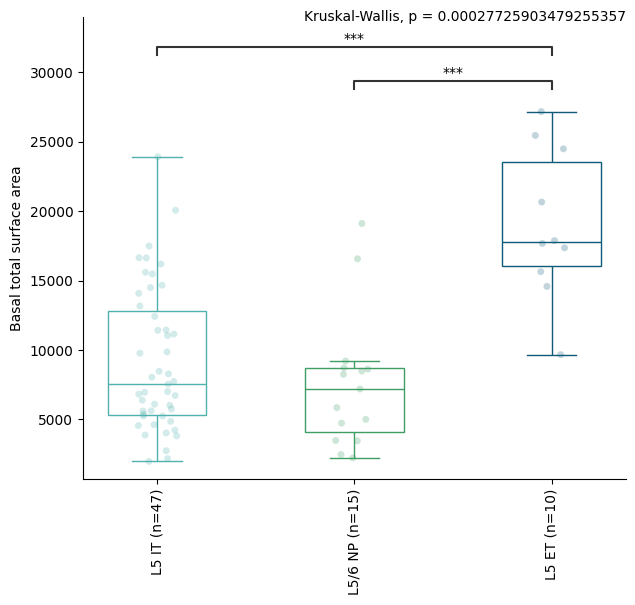

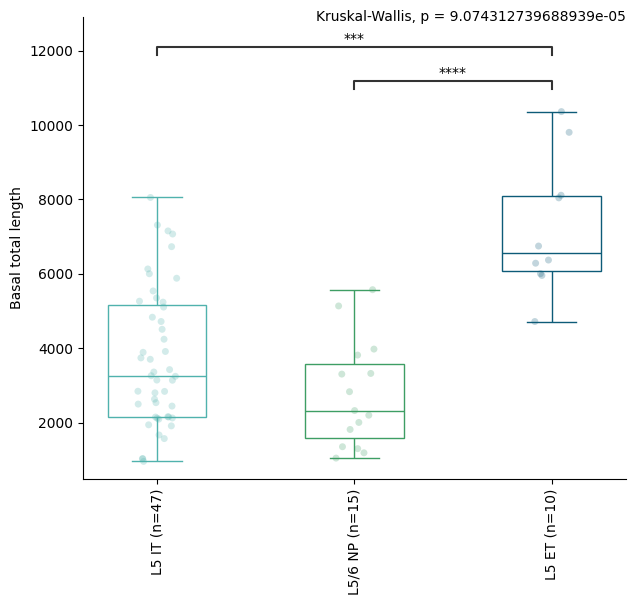

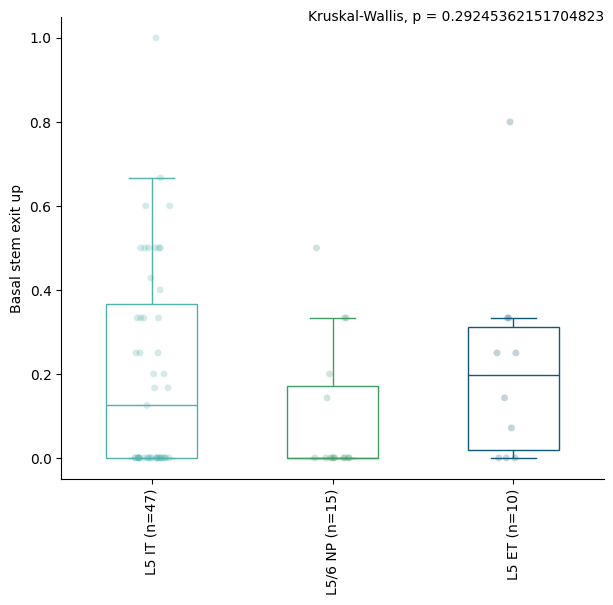

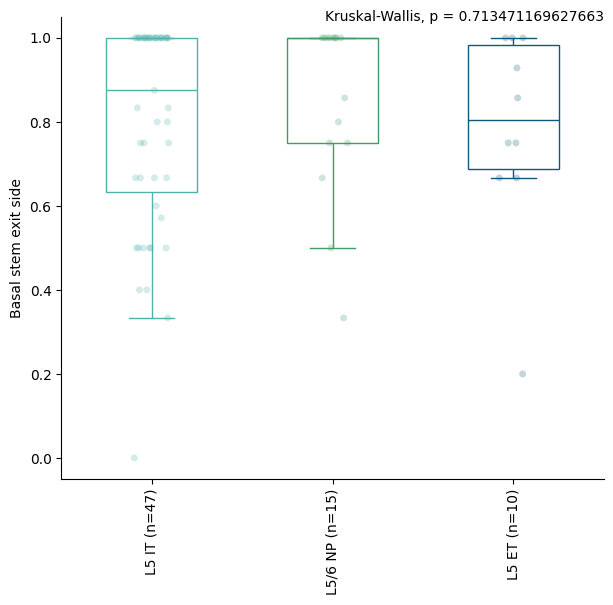

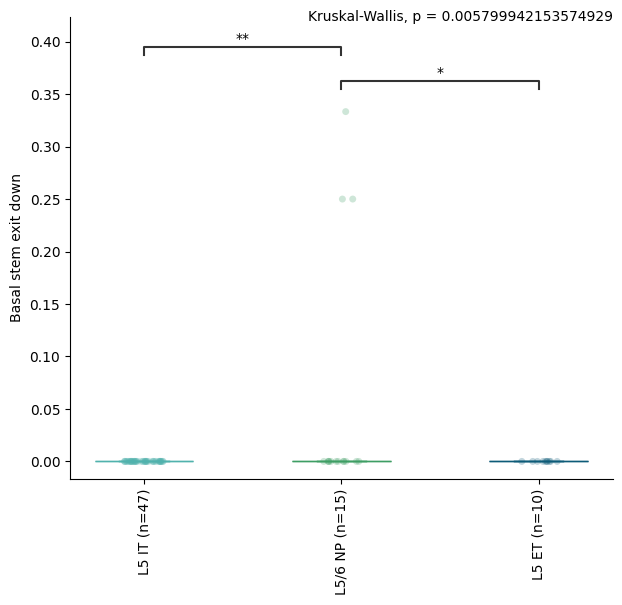

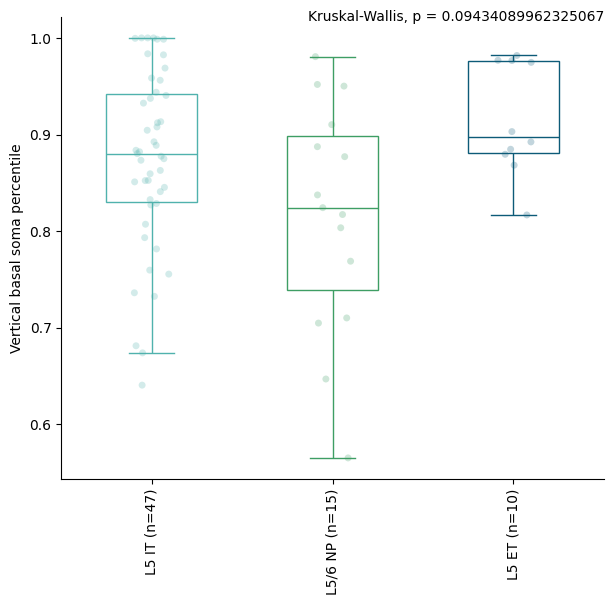

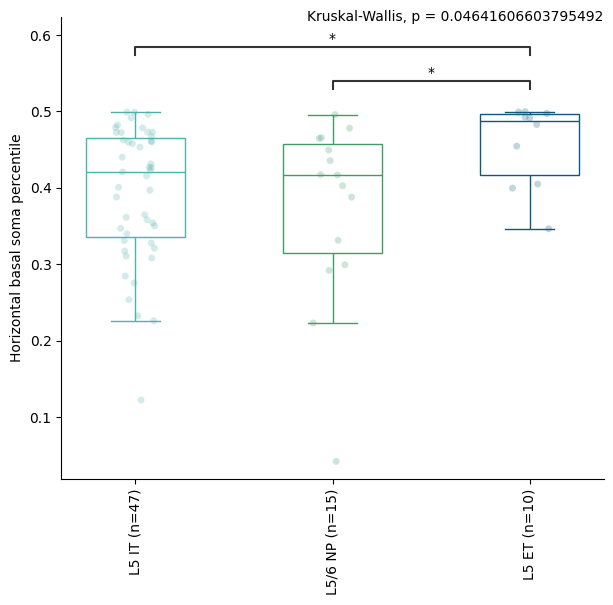

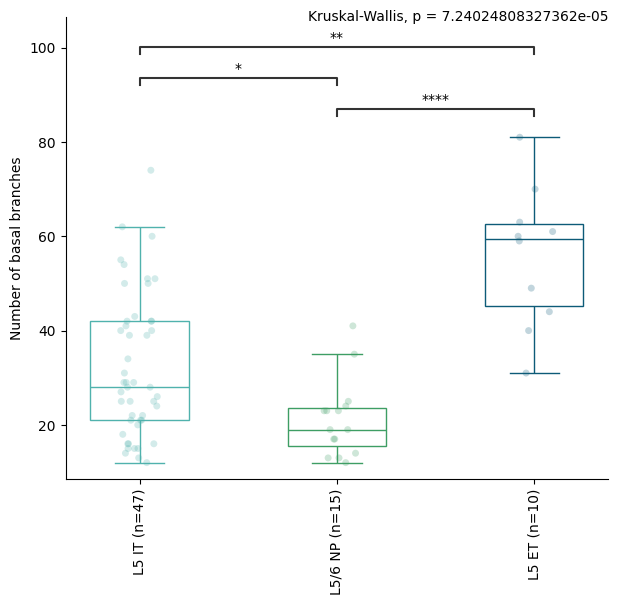

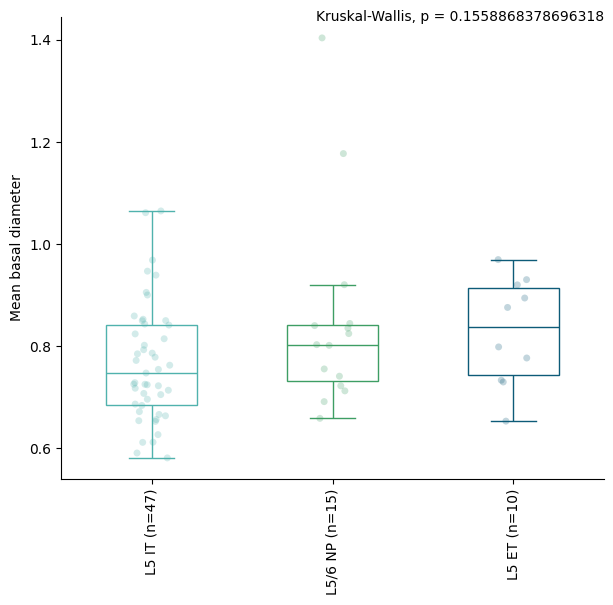

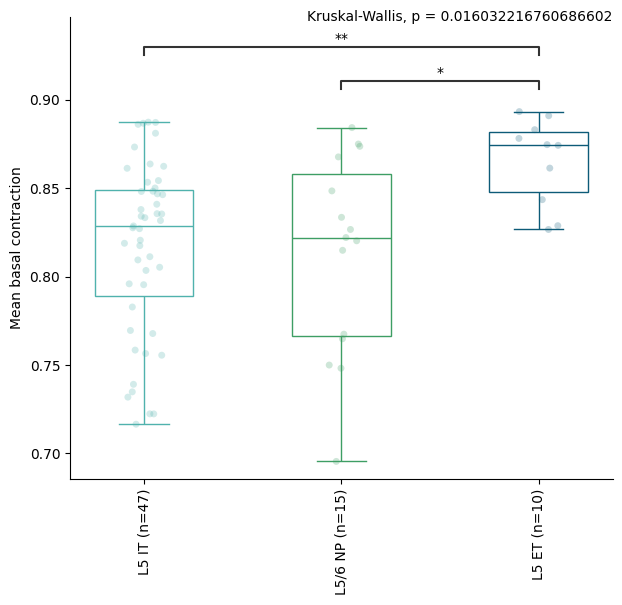

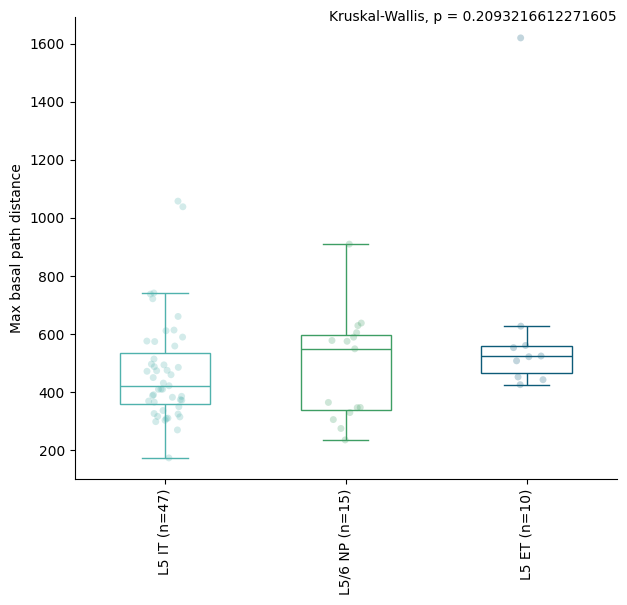

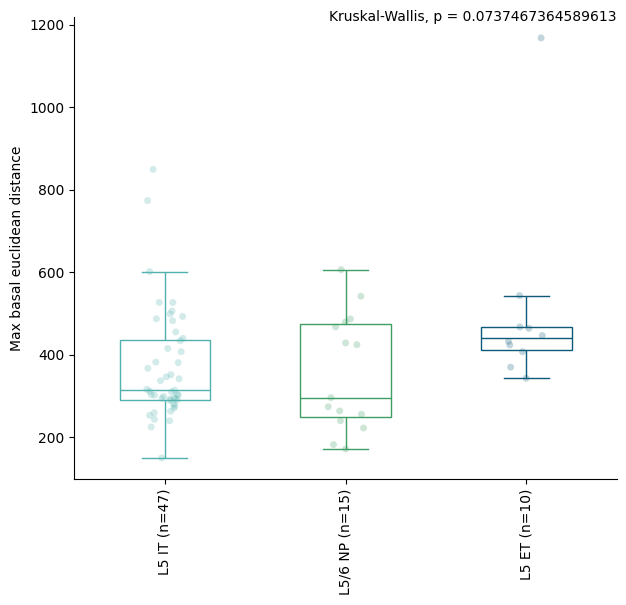

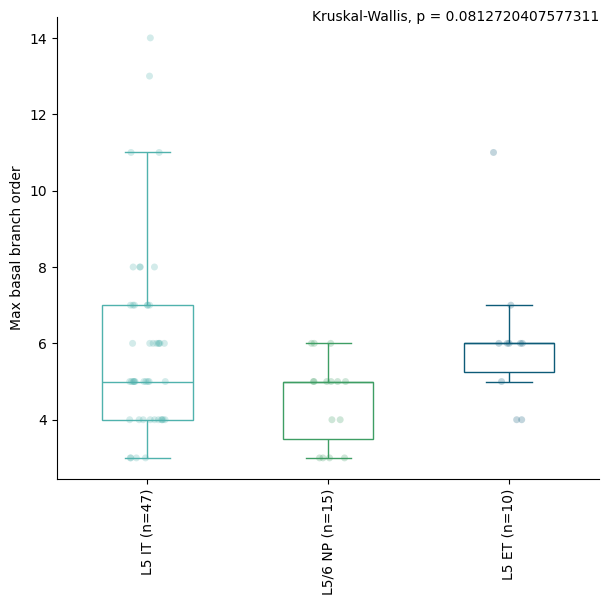

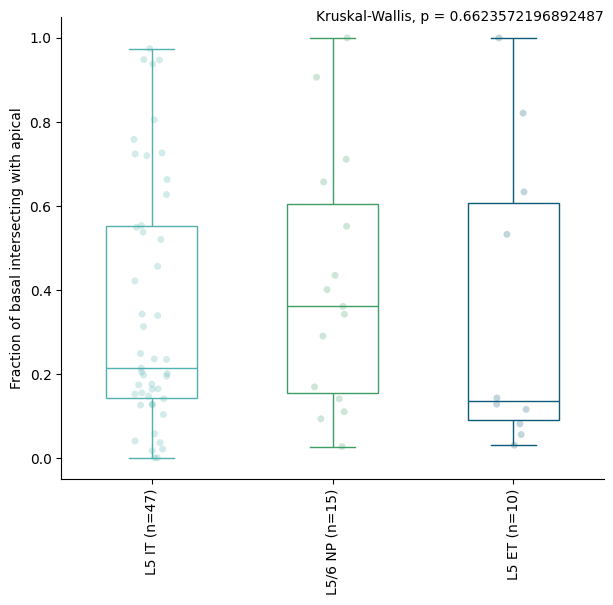

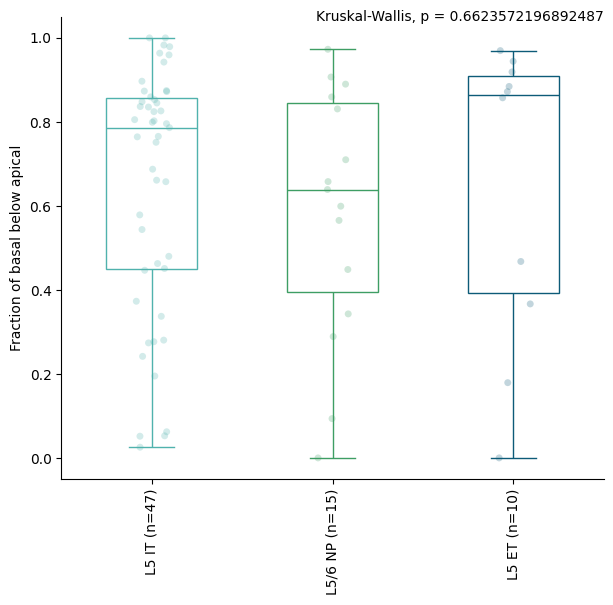

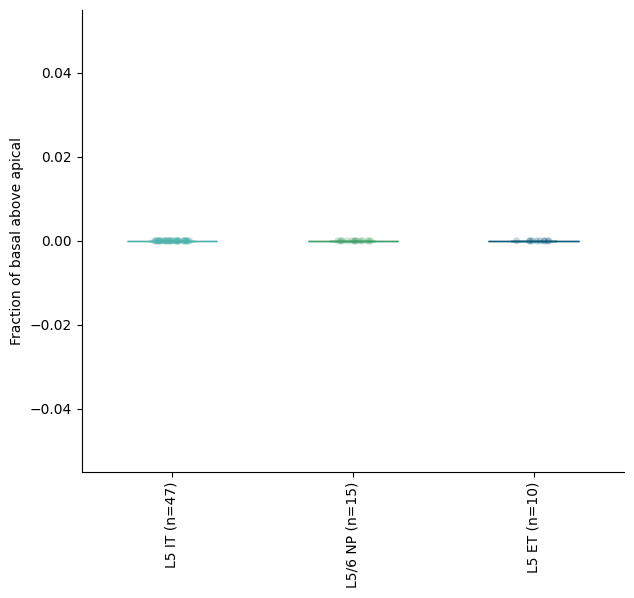

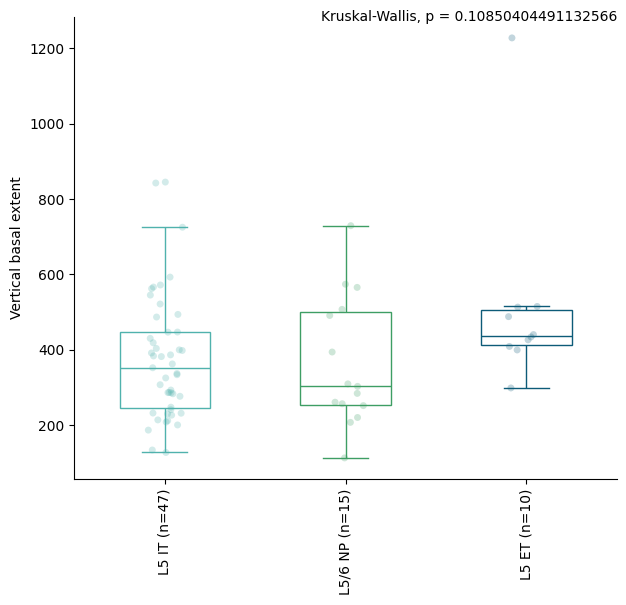

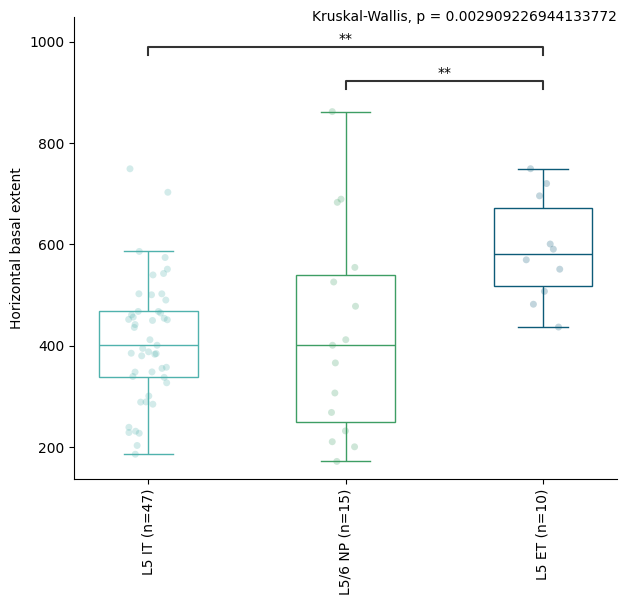

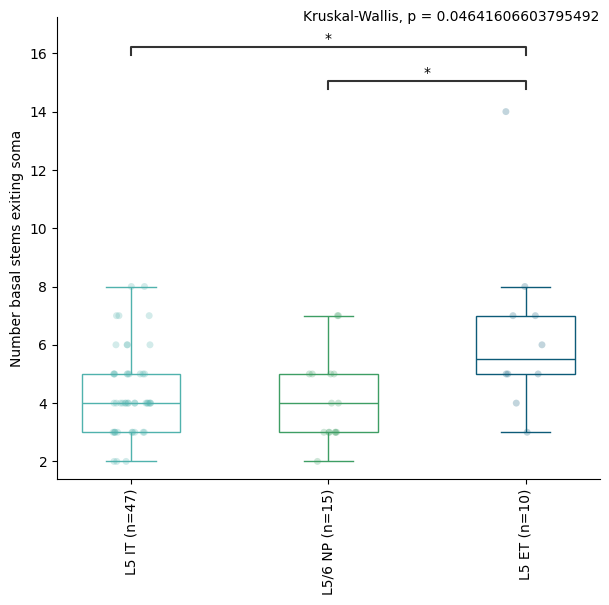

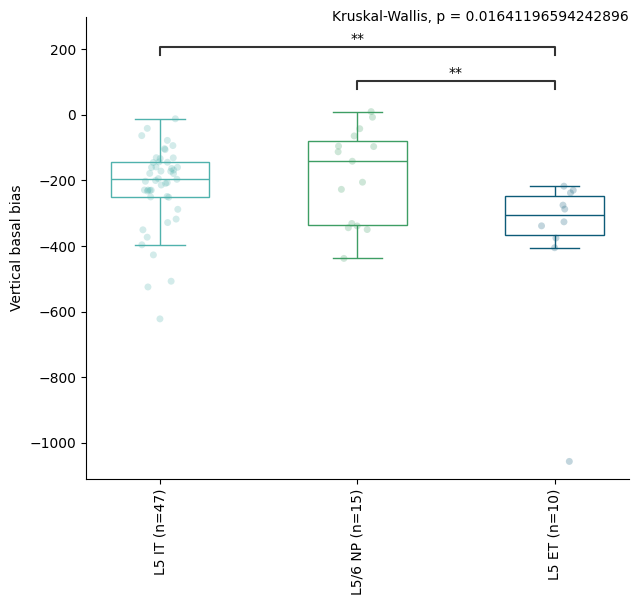

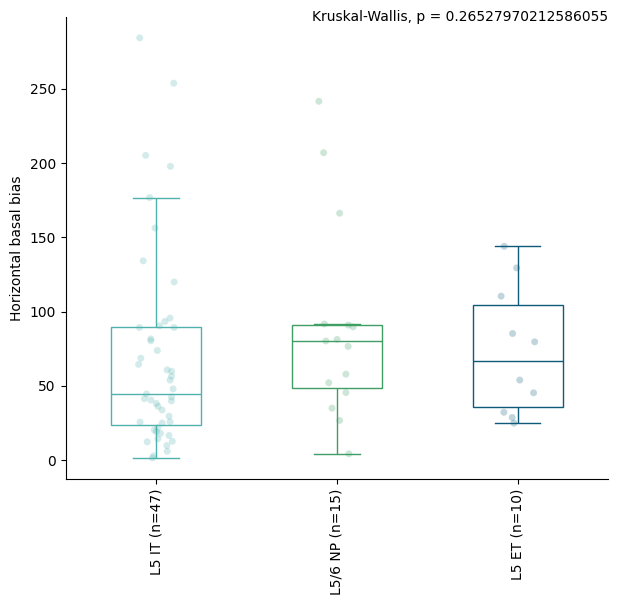

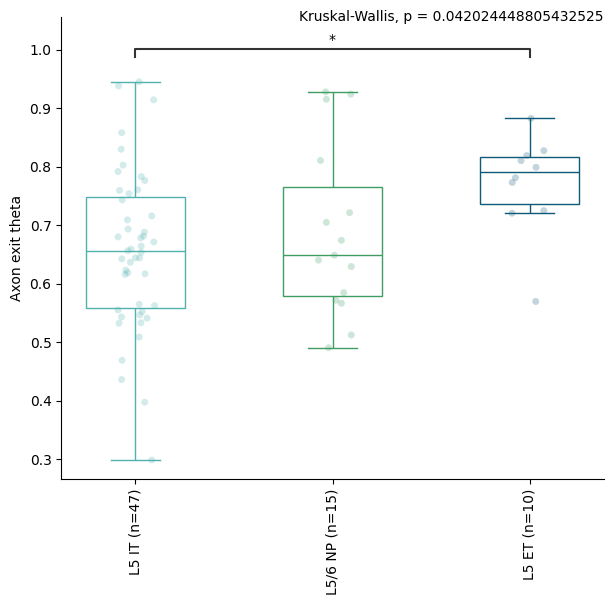

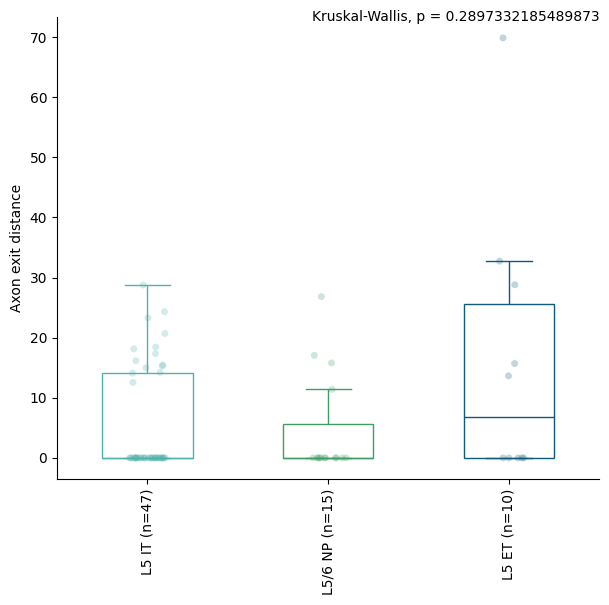

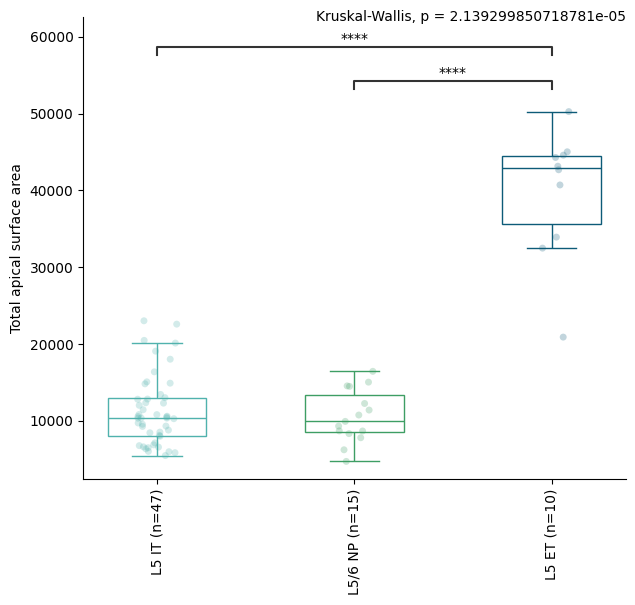

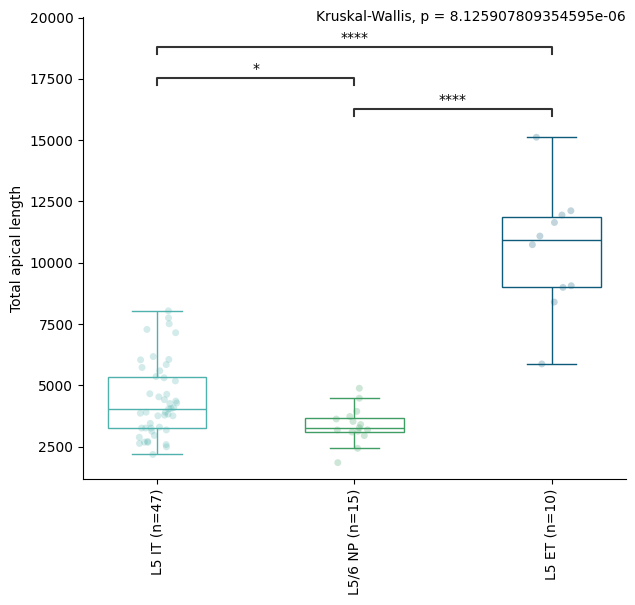

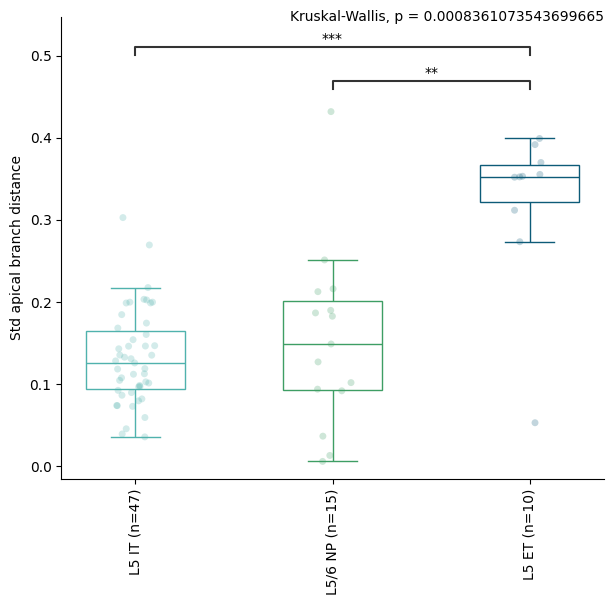

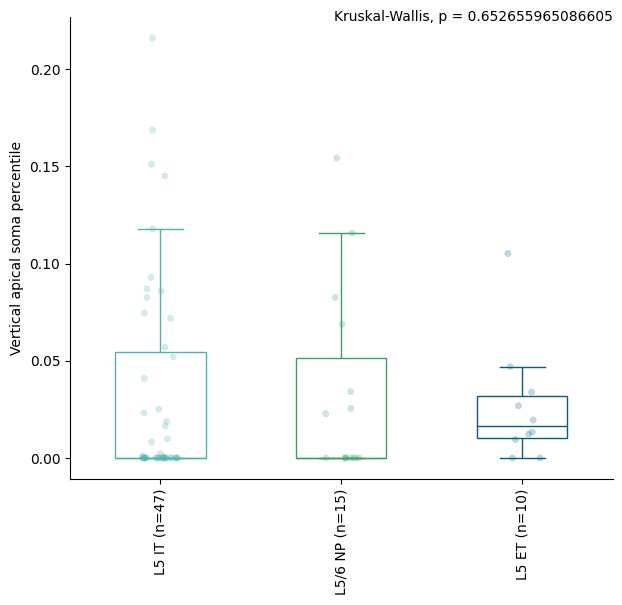

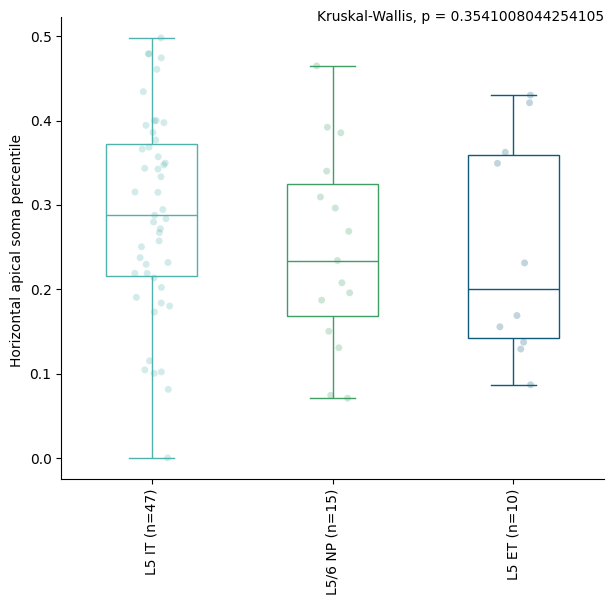

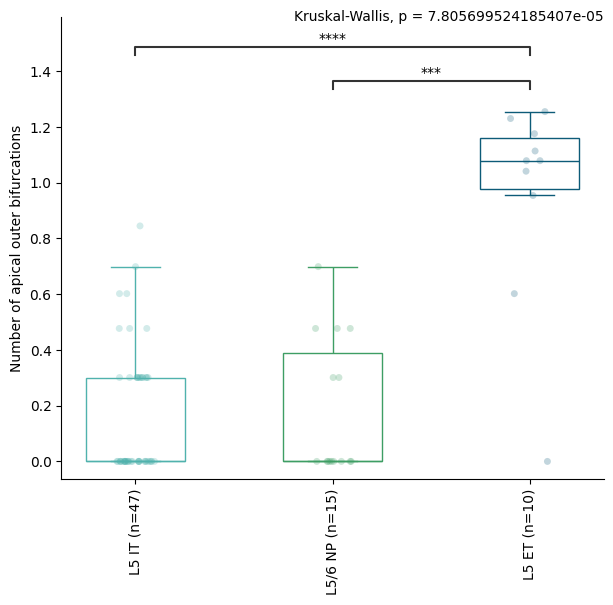

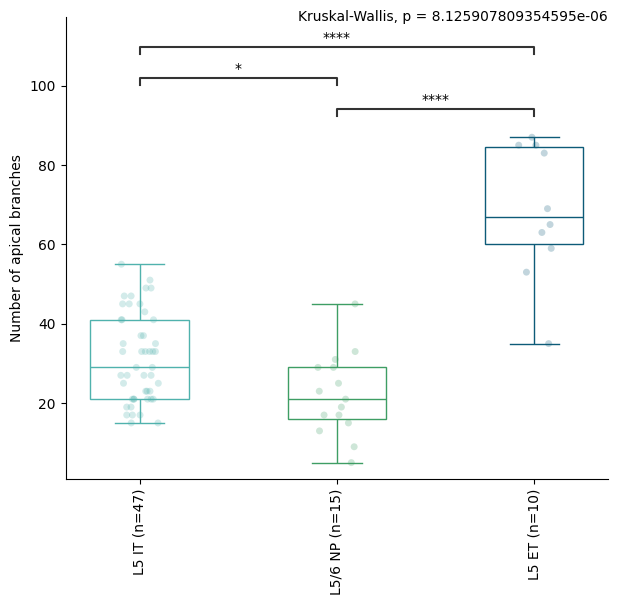

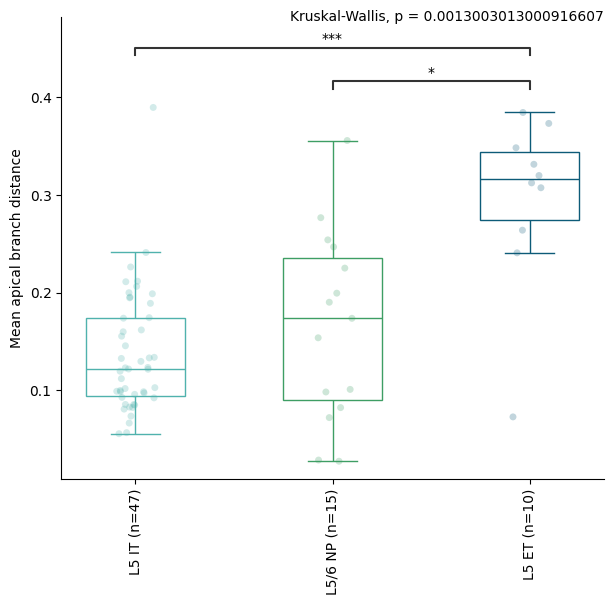

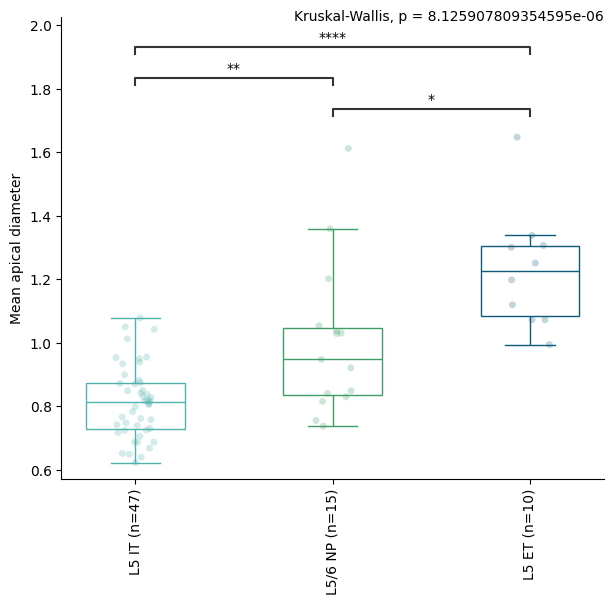

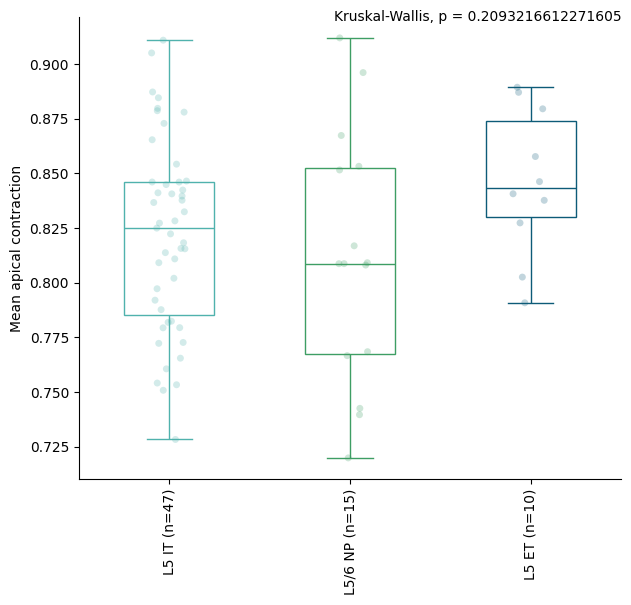

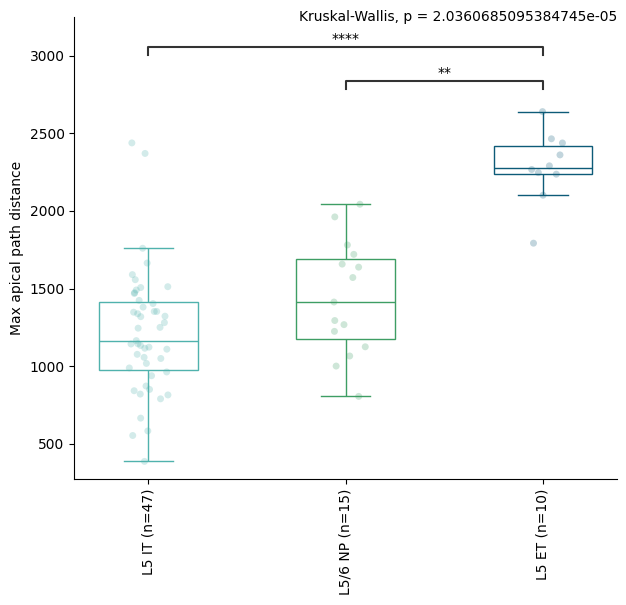

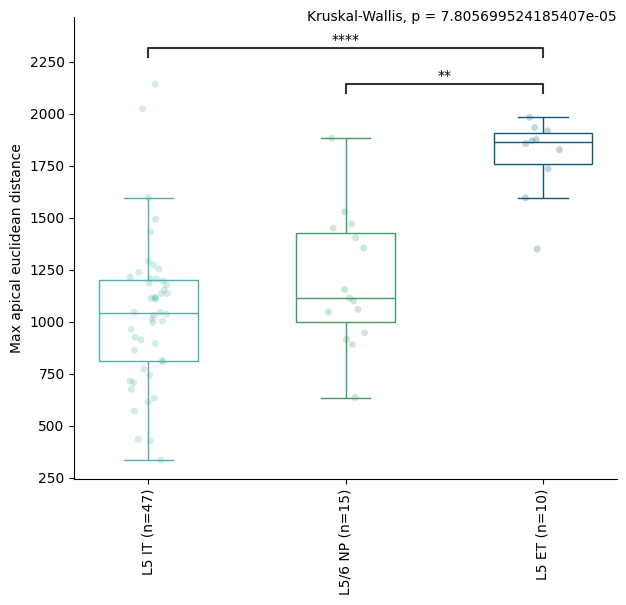

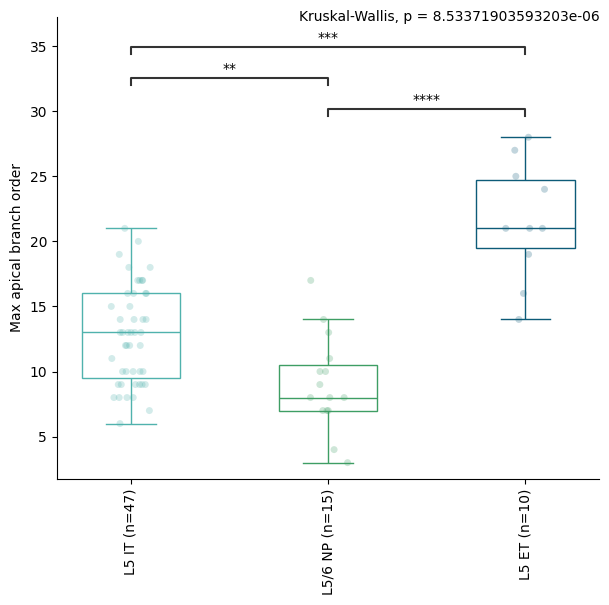

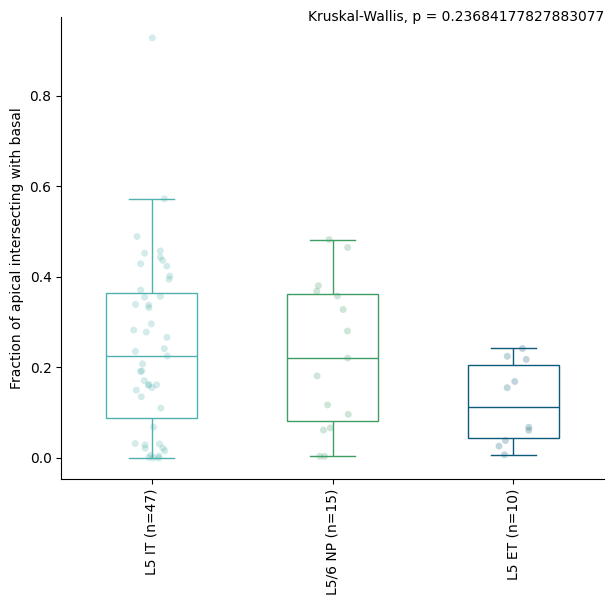

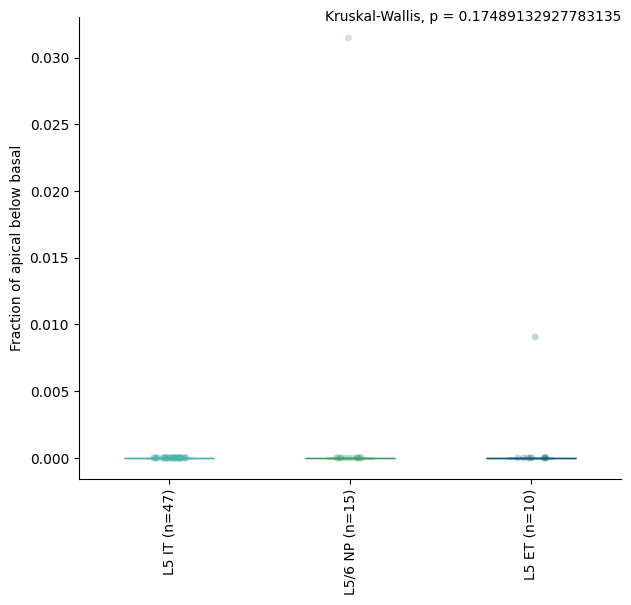

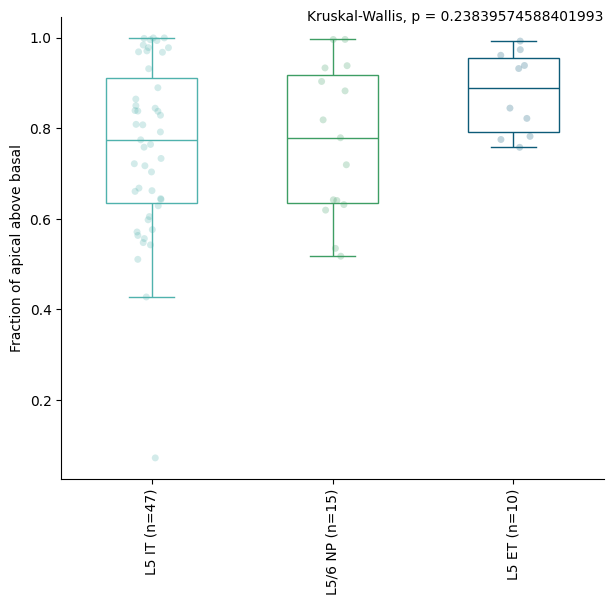

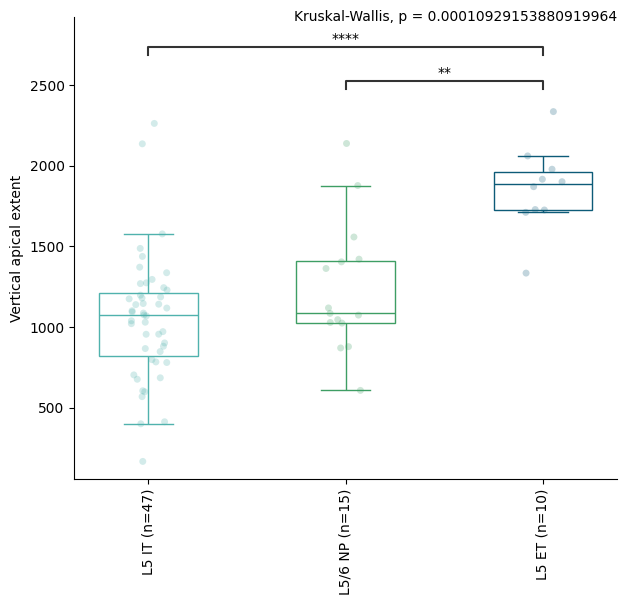

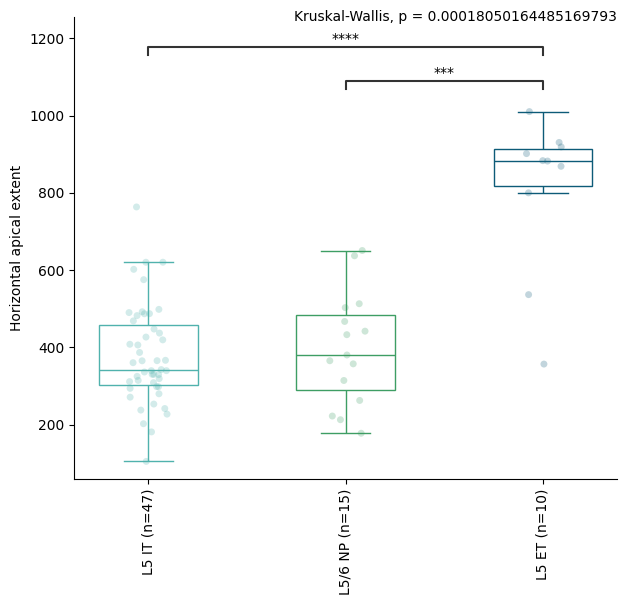

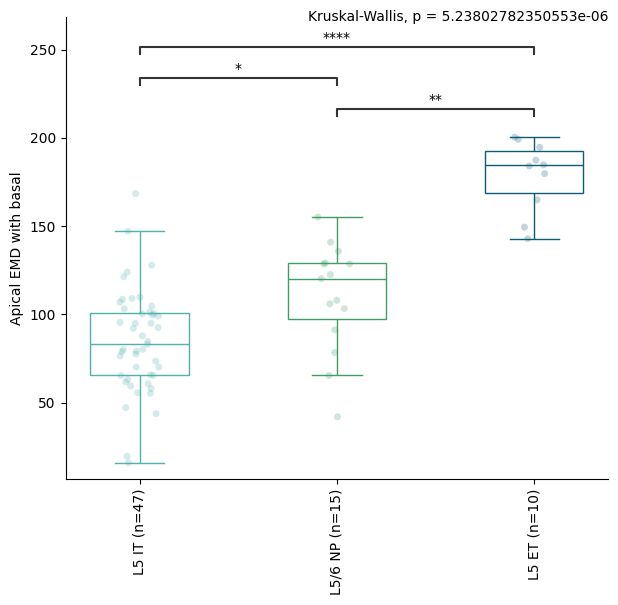

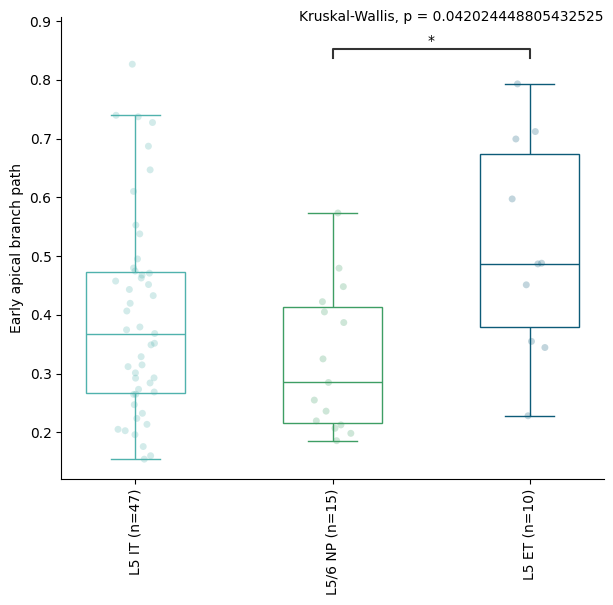

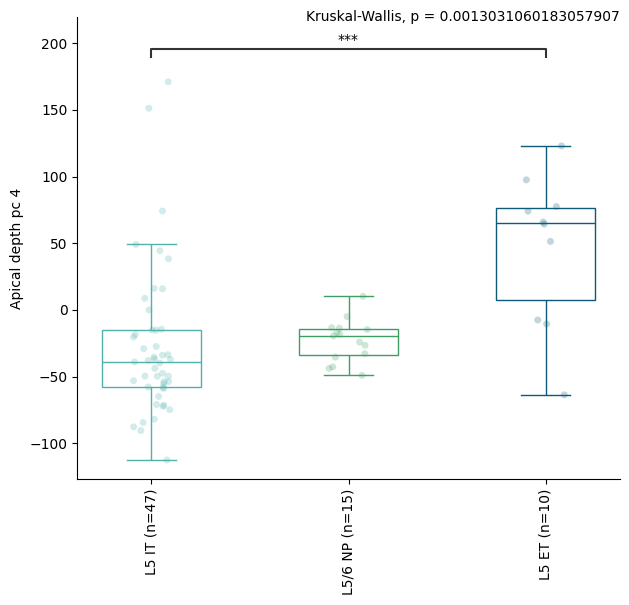

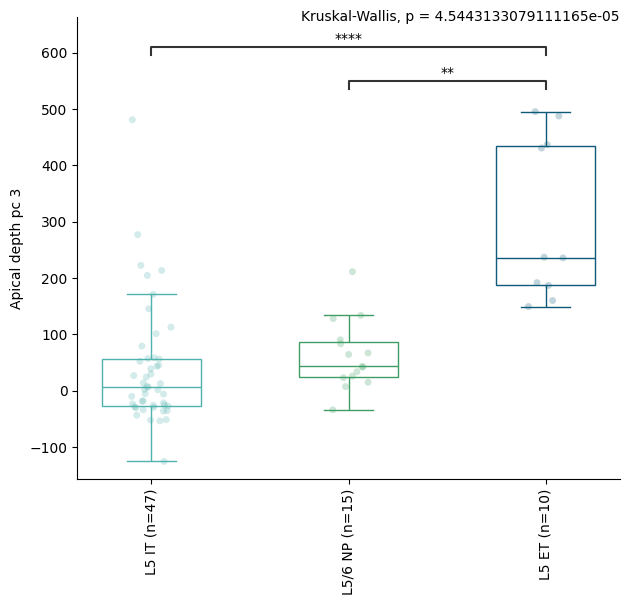

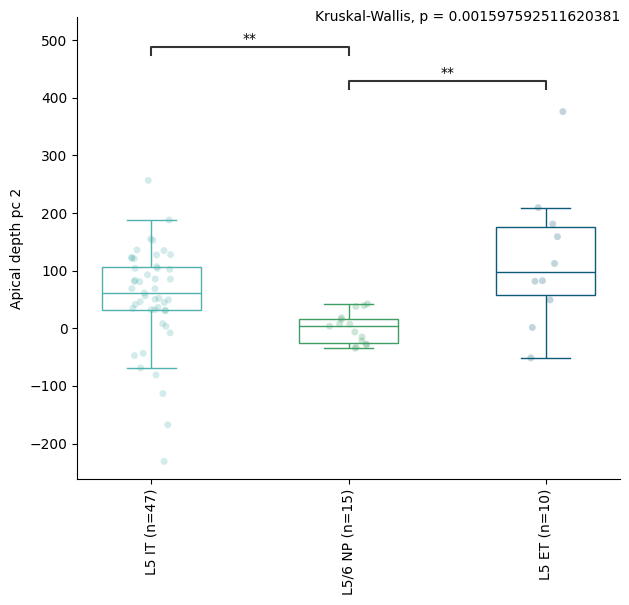

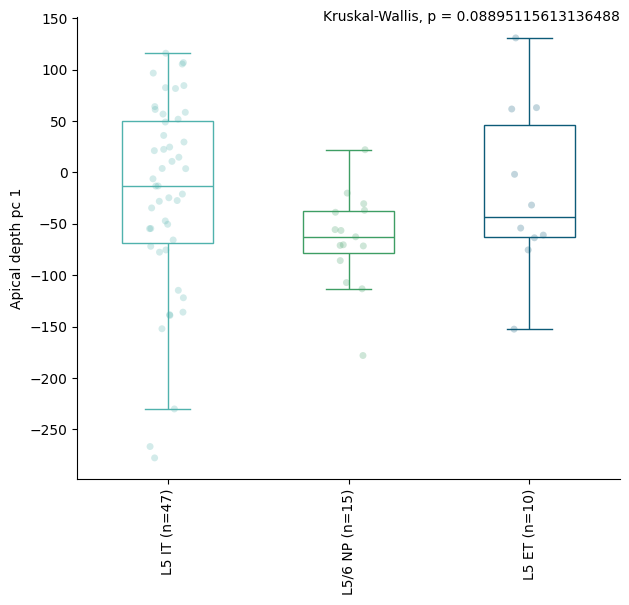

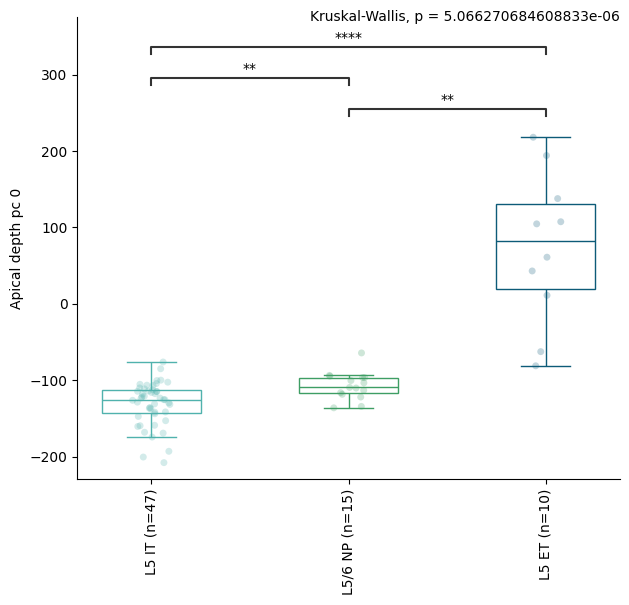

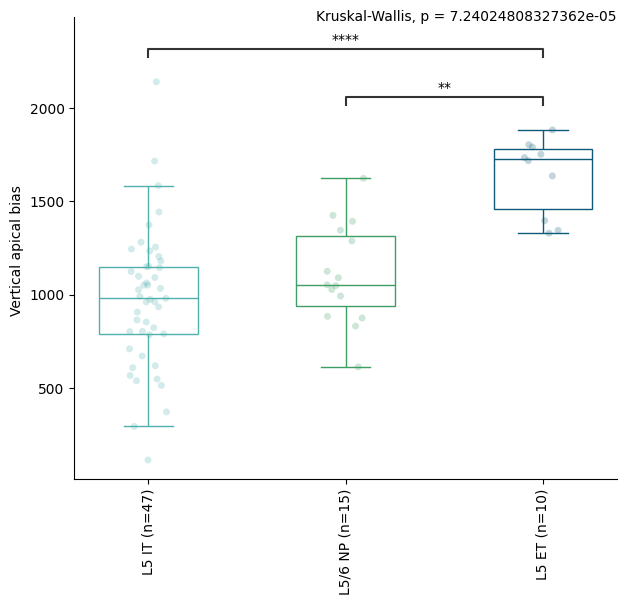

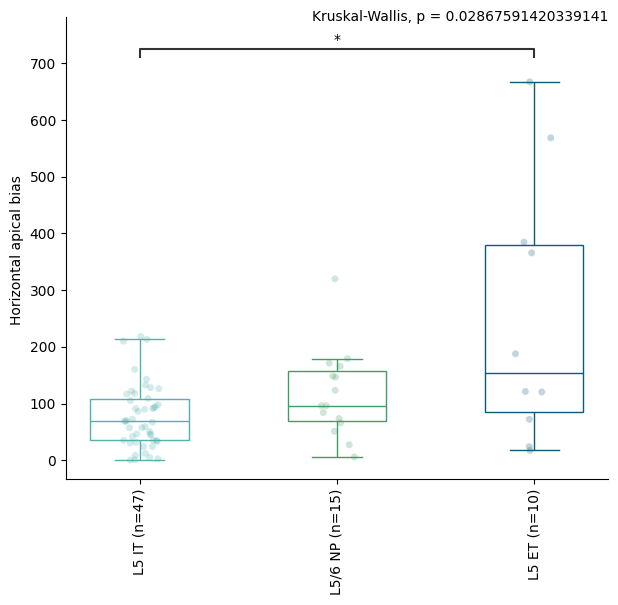

<Figure size 640x480 with 0 Axes>

In [7]:
# subclass x feature box plots

#ADJUST VARS
fig_name = 'human_excitatory_boxplots_dendrite_features_KW_Dunn_FDR_bySubclass_Layer5.pdf'

color_palette = color_dict #colors for x_var
hue_var = 't_type' #seperate strip plots into these categories 
hue_color_palette = color_dict #color palette for hue_var
##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

#######################

fig_path = os.path.join(output_dir, fig_name)
features = raw_feature_wide.columns.tolist()[1:] 

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        while features != []:
            
            #one fig per page, each has page (fig) has 4 rows. 
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
            
            y_var = features.pop()
            
            sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
            format_box_plot(ax) #color line not fill of boxplot


            #add num observations per x_var
            nobs = []
            for t in x_var_order:
                n = len(sorted_clean_data[sorted_clean_data[x_var] == t])
                nobs.append(" (n=%s)" % str(n))
            new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
            ax.set_xticklabels(new_x_tick_labels)

            # add stats (KW w/ Dunn post hoc FDR corrected)

            #plot signif dunn fdr p-vals 
            if y_var in dunn_pvals_fdr.keys(): 
                #kw fdr val was signif so there are dunn fdr vals to plot
                
                this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                this_dunn_pvals_fdr[remove] = np.nan
                dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                #set insignificant pvals to nan 
                p_thresh = 0.05 #threshold for plotting p vals 
                dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                #plot bar for all signif fdr corrected dunn p vals 
                pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                if len(pairs): 
                    #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                    p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                    annotator = Annotator(ax=ax, pairs=pairs, data=sorted_clean_data, x=x_var, y=y_var, order=x_var_order)
                    annotator.configure(text_format="star", loc="inside") #text_format="simple"
                    annotator.set_pvalues_and_annotate(p_values)
                    
            #plot Kruskal-Wallis fdr p-vals
            if y_var in kw_pvals_fdr.keys():
                xlimit = ax.get_xlim()
                ylimit = ax.get_ylim()
                p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

            #rotate and format x_var labels 
            ax.set(xlabel=None)
            ax.tick_params(axis='x', rotation=90)
            ax.set_ylabel(y_var.replace("_", " "), rotation=90)
            ax.spines[['right', 'top']].set_visible(False)

            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf()
        print()



Subclasses within Layer 6

In [8]:
# subclass x feature stats
x_var = 'subclass_label' #what to do box plots on 
x_var_order = [t for t in group_order[x_var] if t.startswith('L6')]

features = raw_feature_wide.columns.tolist()[1:]

# Kruskal-Wallis H test on all features
kw_pvals = dict()
kw_hvals = dict()
for f in features:
    # Create a list of groups dynamically
    groups = [sorted_clean_data.loc[sorted_clean_data[x_var] == x][f].dropna() for x in x_var_order]
    
    # Only include groups that have data
    groups = [group for group in groups if not group.empty]

    if len(groups) < 2:
        print(f"Not enough groups with data for feature {f}")
        continue
    try:
        hvalue, pvalue = kruskal(*groups, nan_policy='omit')
        kw_hvals[f] = hvalue
        kw_pvals[f] = pvalue
    except ValueError as e:
        print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

# FDR correction
kw_pvals_list = list(kw_pvals.values())
kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

# Post Hoc Dunn test for significant KW features, with FDR correction
dunn_pvals_fdr = dict()
for k, v in kw_rejected.items():
    if v:  # if null hypothesis was rejected, calculate Dunn post hoc
        dunn_pvals_fdr[k] = posthoc_dunn(sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)


/tmp/ipykernel_7320/2293067639.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7320/2293067639.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7320/2293067639.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7320/2293067639.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7320/2293067639.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_x

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT vs. L6 CT: Custom statistical test, P_val:4.780e-04
L6 CT vs. L6b: Custom statistical test, P_val:3.739e-02
L6 IT Car3 vs. L6 CT: Custom statistical test, P_val:3.712e-02


/tmp/ipykernel_7320/2293067639.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT vs. L6 CT: Custom statistical test, P_val:5.707e-03


/tmp/ipykernel_7320/2293067639.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT vs. L6 CT: Custom statistical test, P_val:2.988e-03
L6 IT Car3 vs. L6 CT: Custom statistical test, P_val:3.095e-02
L6 IT vs. L6b: Custom statistical test, P_val:3.933e-02


... (25 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT Car3 vs. L6 IT: Custom statistical test, P_val:1.354e-02
L6 CT vs. L6b: Custom statistical test, P_val:1.354e-02
L6 IT Car3 vs. L6 CT: Custom statistical test, P_val:3.469e-03
L6 IT vs. L6b: Custom statistical test, P_val:4.878e-02


/tmp/ipykernel_7320/2293067639.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7320/2293067639.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7320/2293067639.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7320/2293067639.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_7320/2293067639.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_x

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT Car3 vs. L6 IT: Custom statistical test, P_val:2.530e-03
L6 IT Car3 vs. L6 CT: Custom statistical test, P_val:2.340e-02


/tmp/ipykernel_7320/2293067639.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


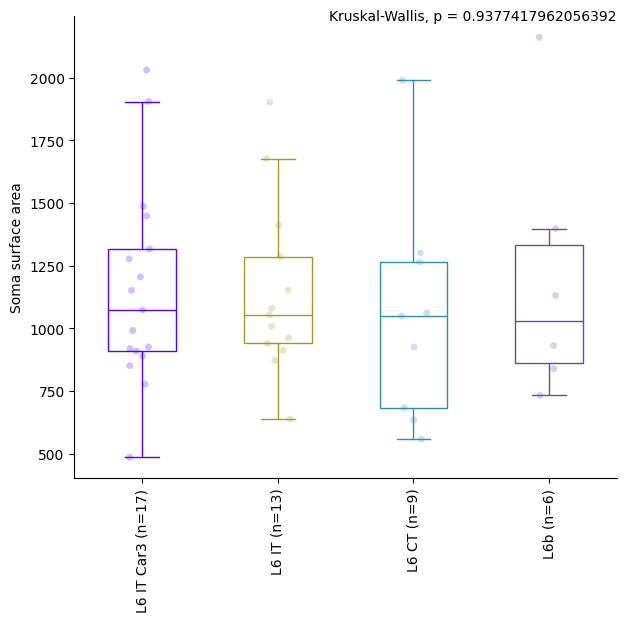

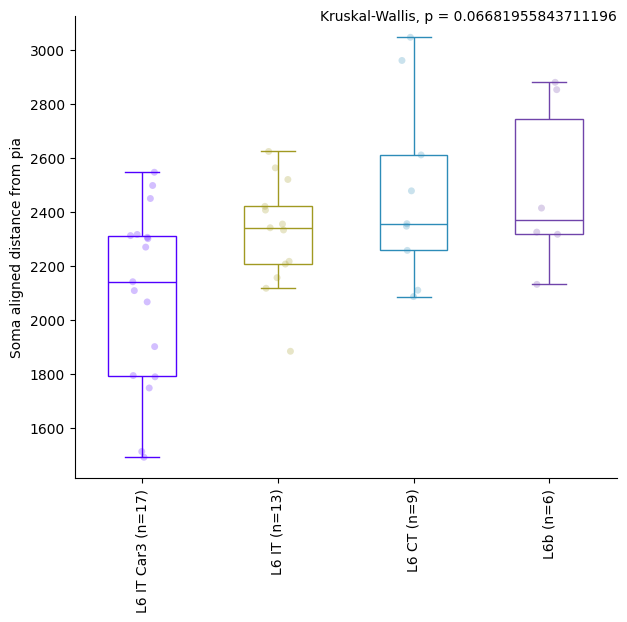

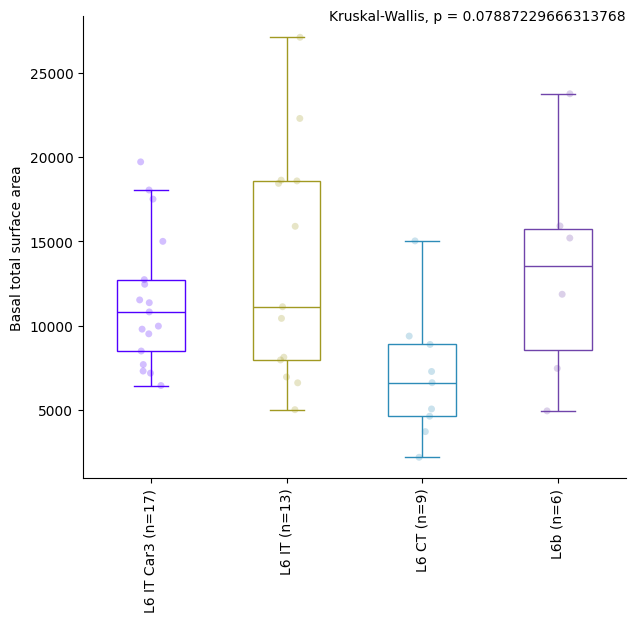

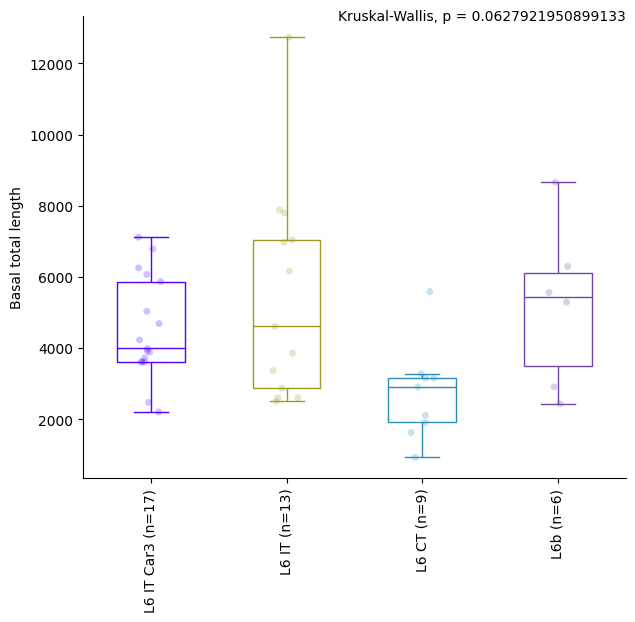

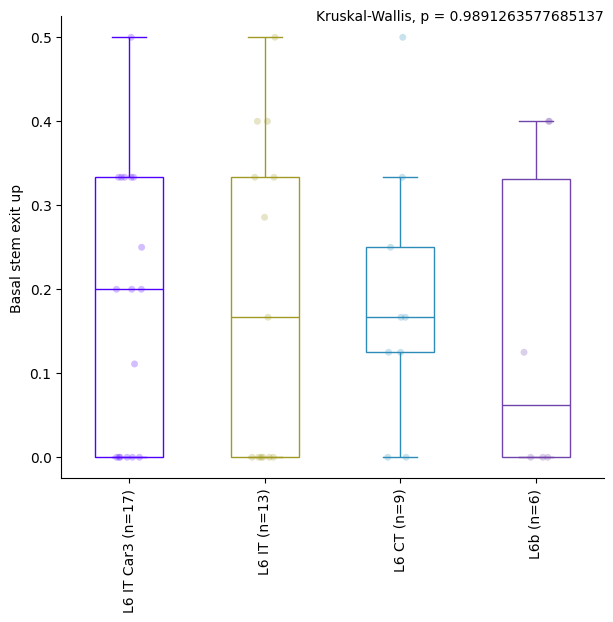

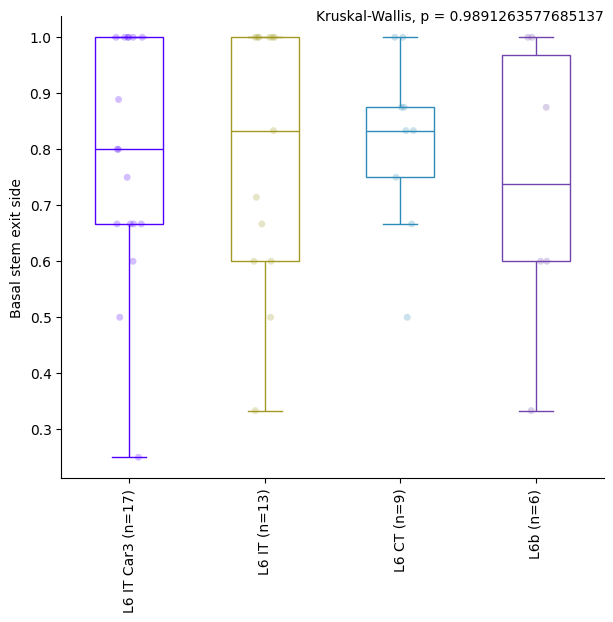

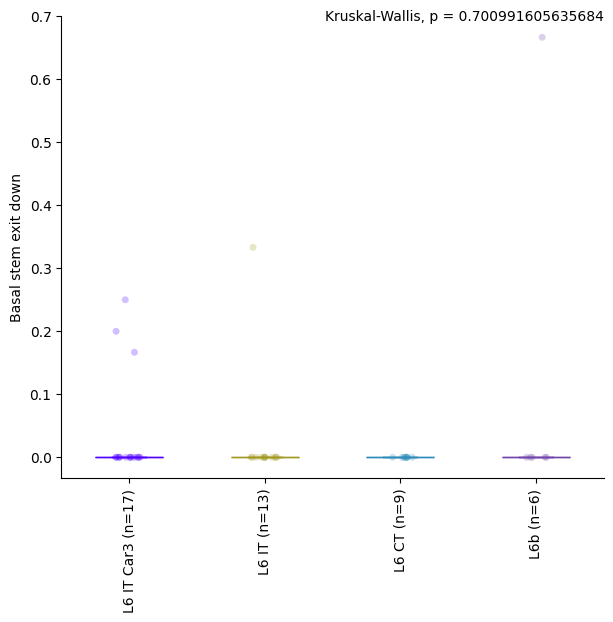

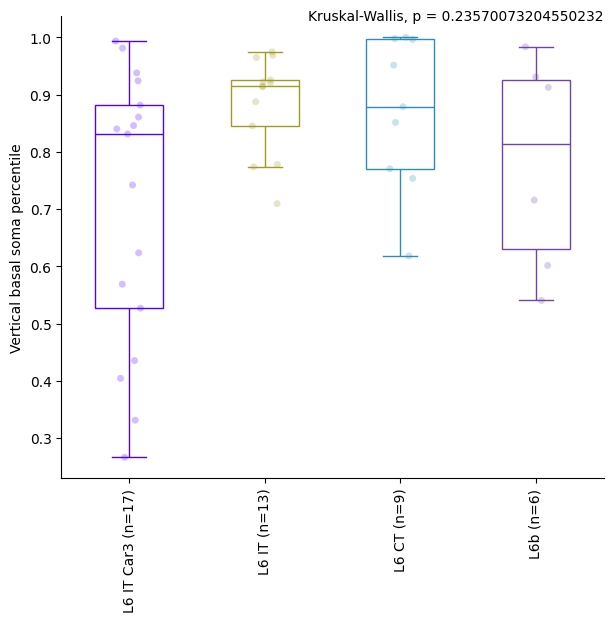

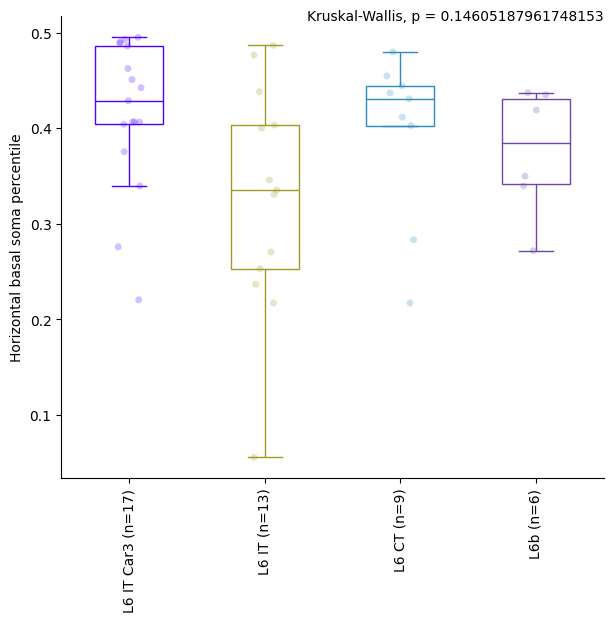

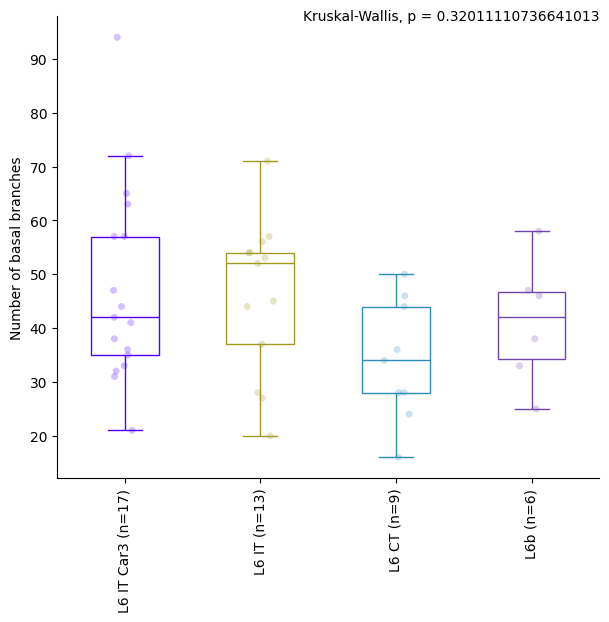

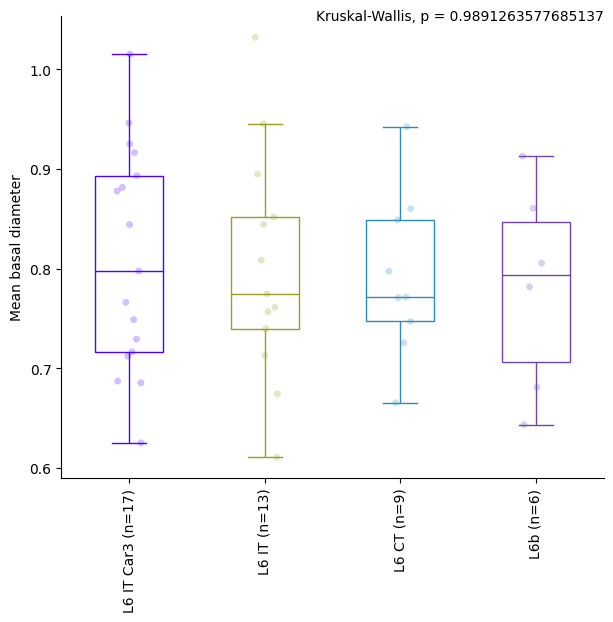

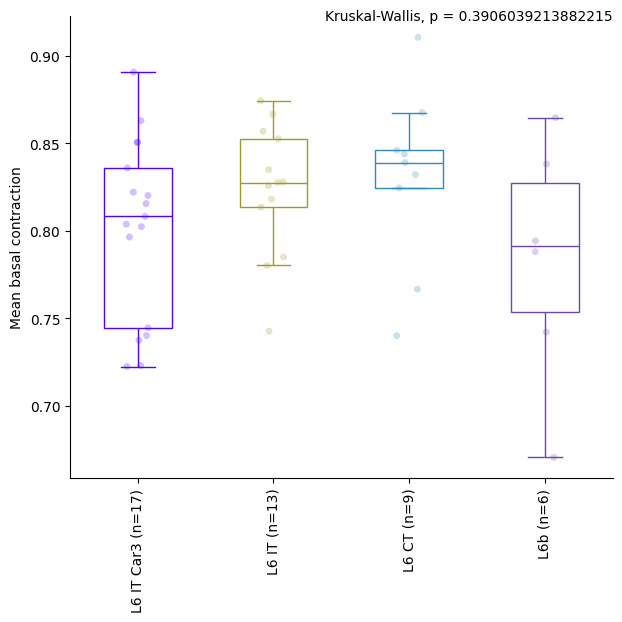

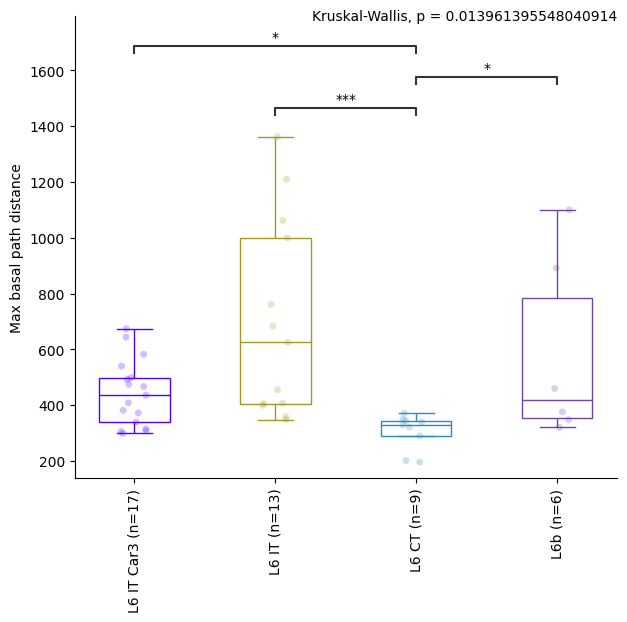

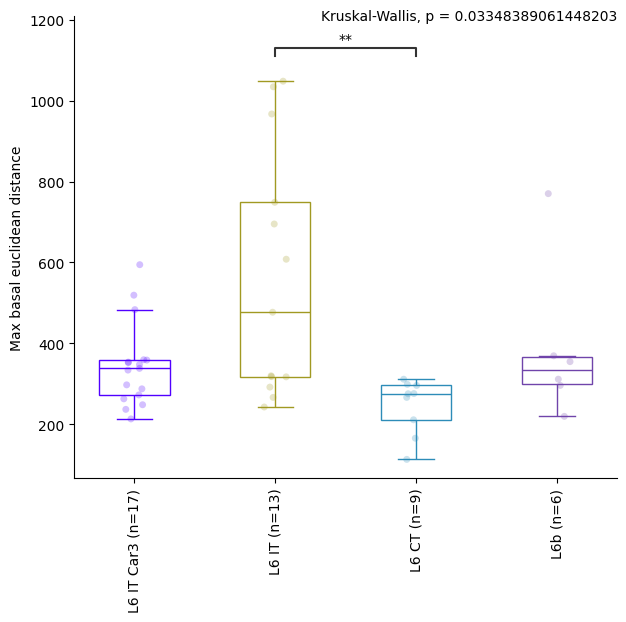

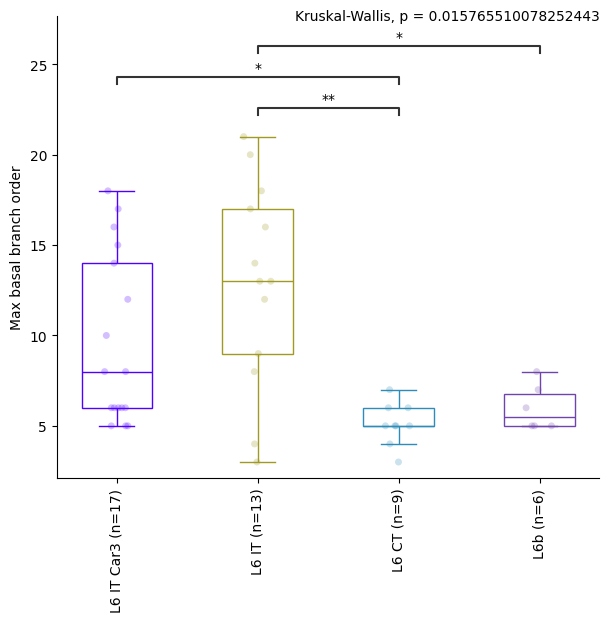

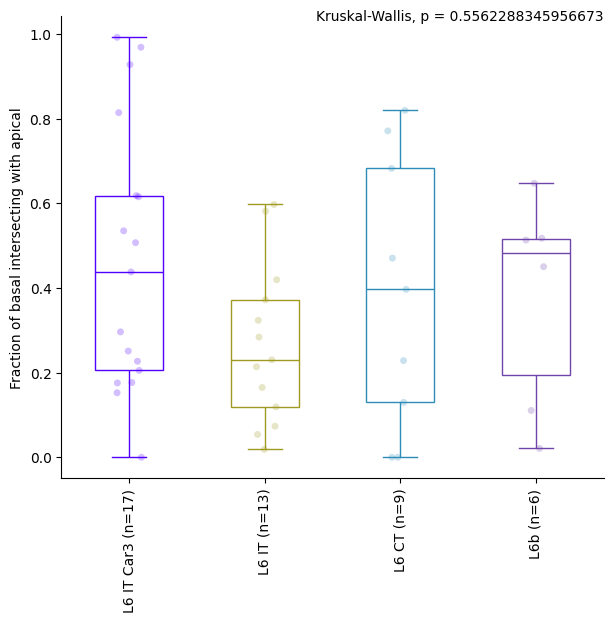

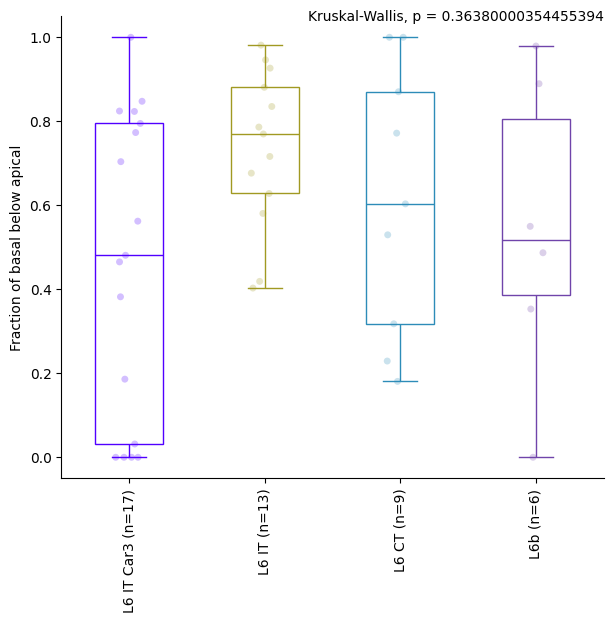

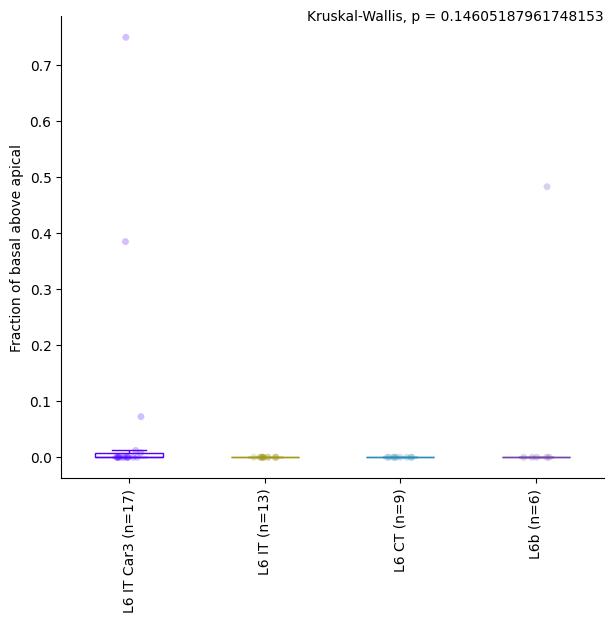

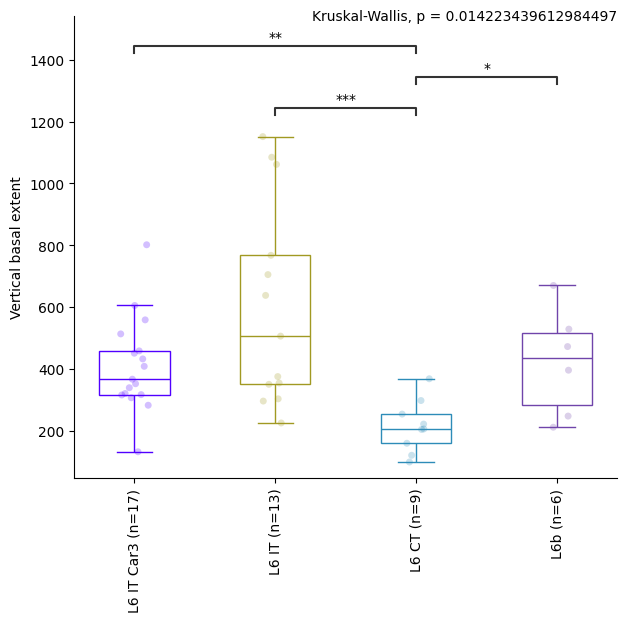

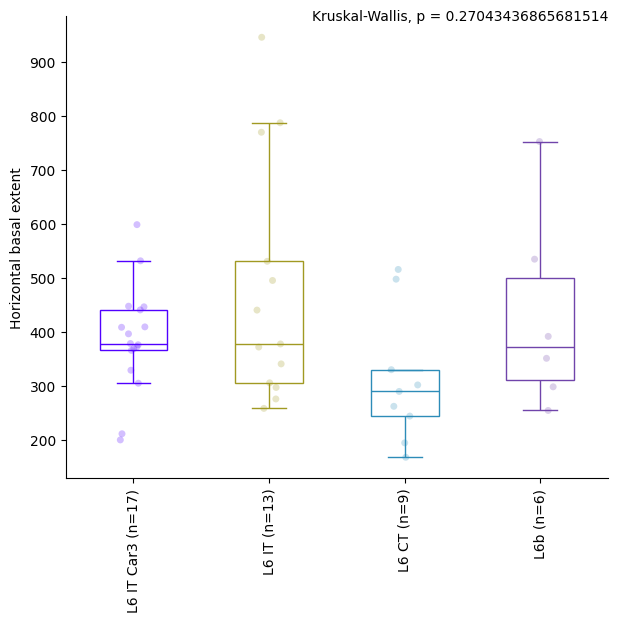

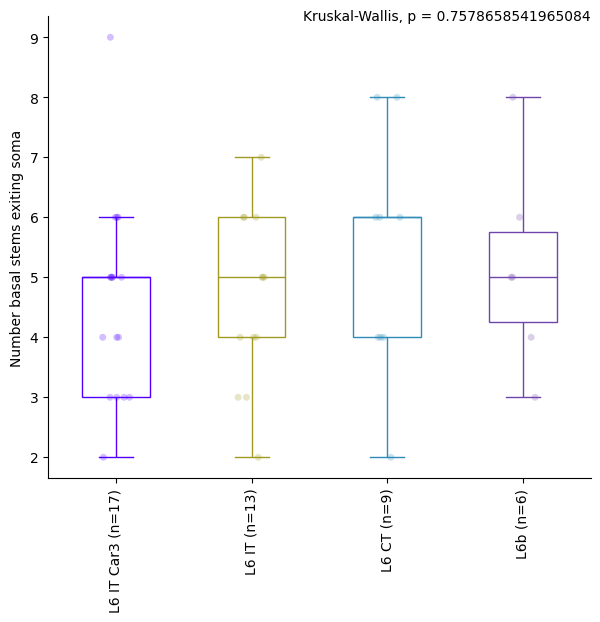

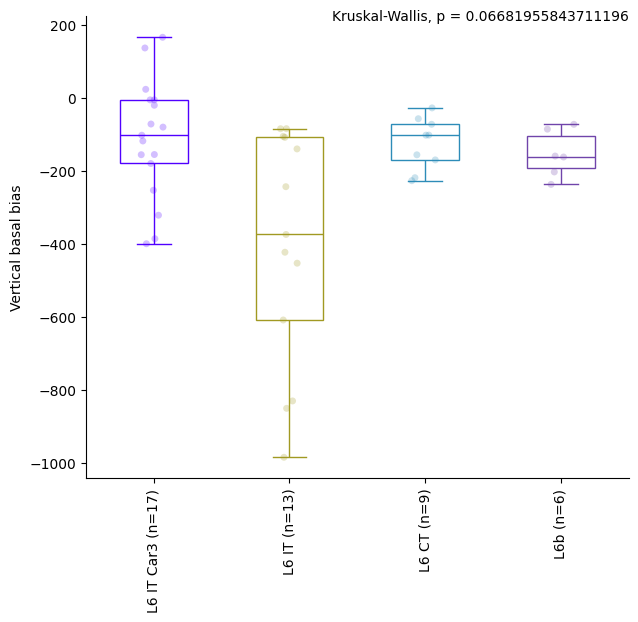

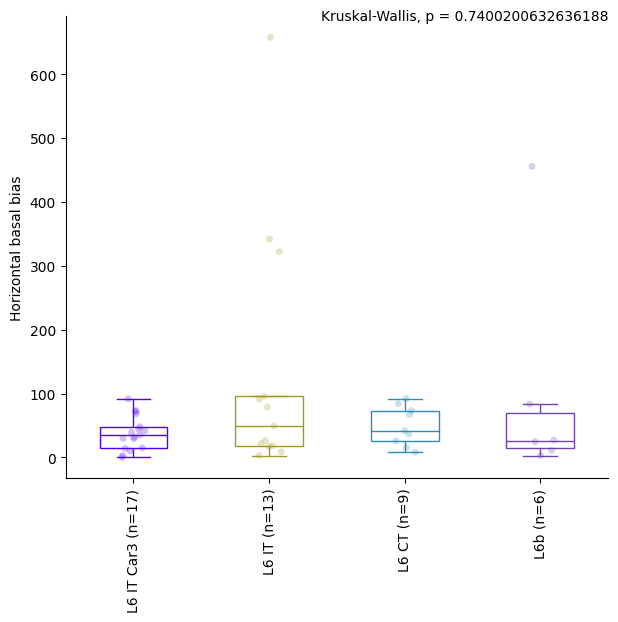

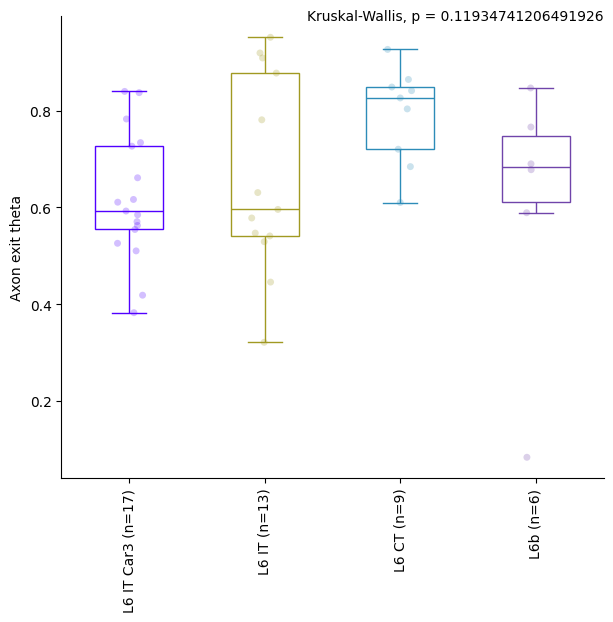

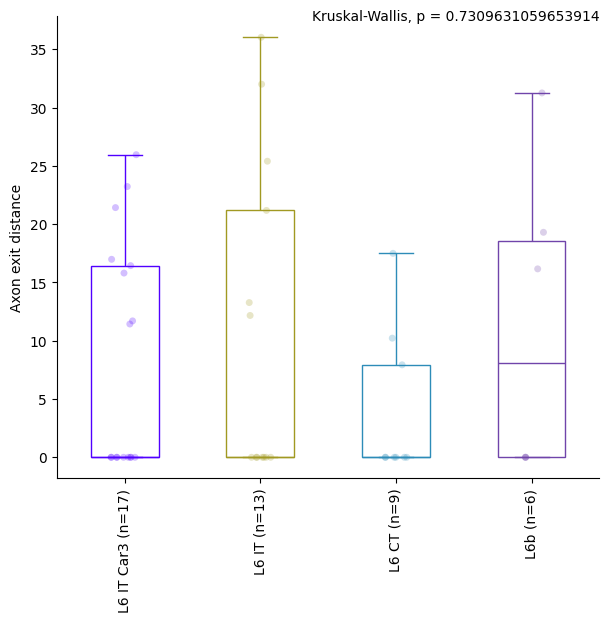

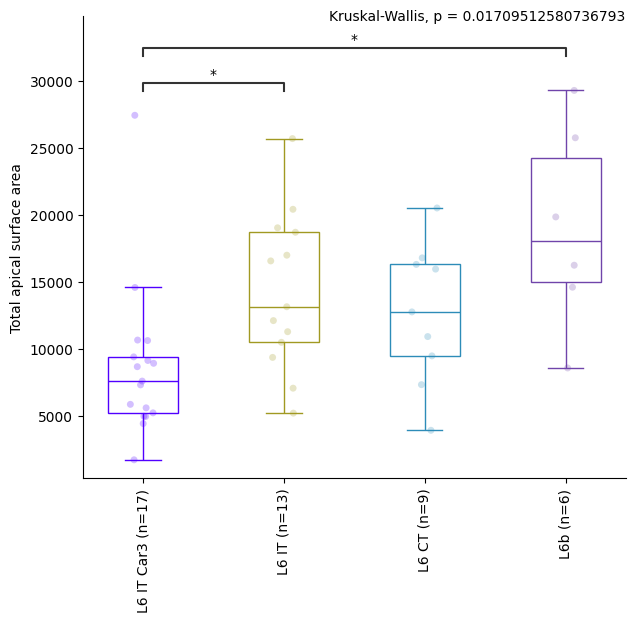

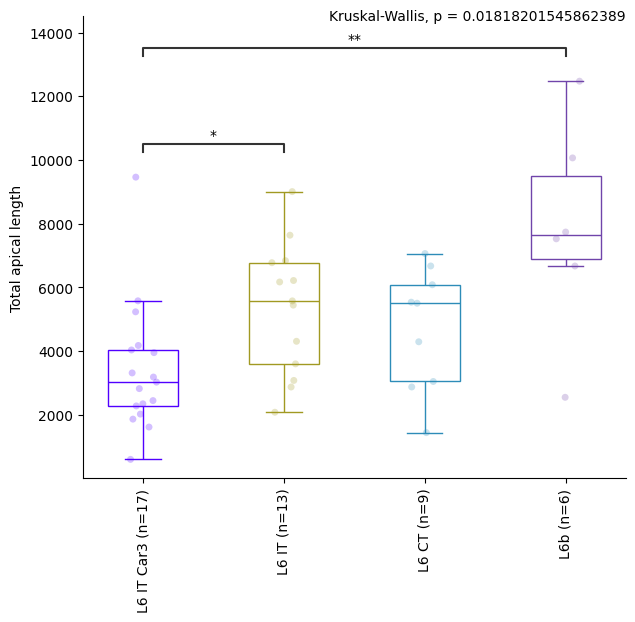

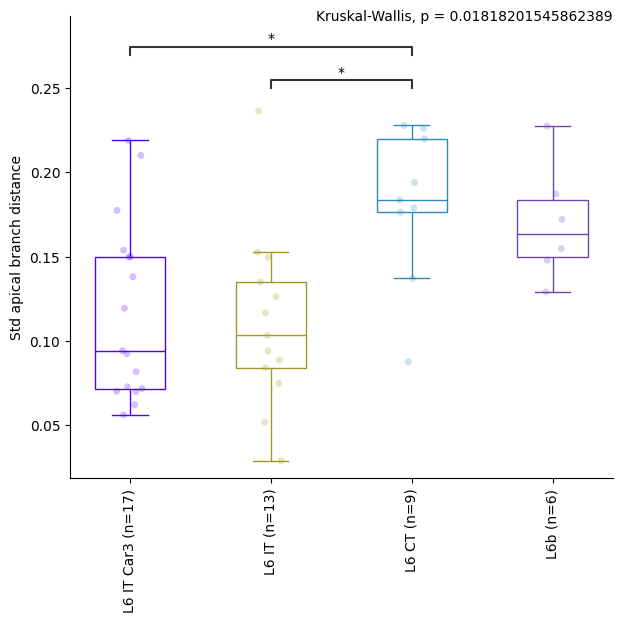

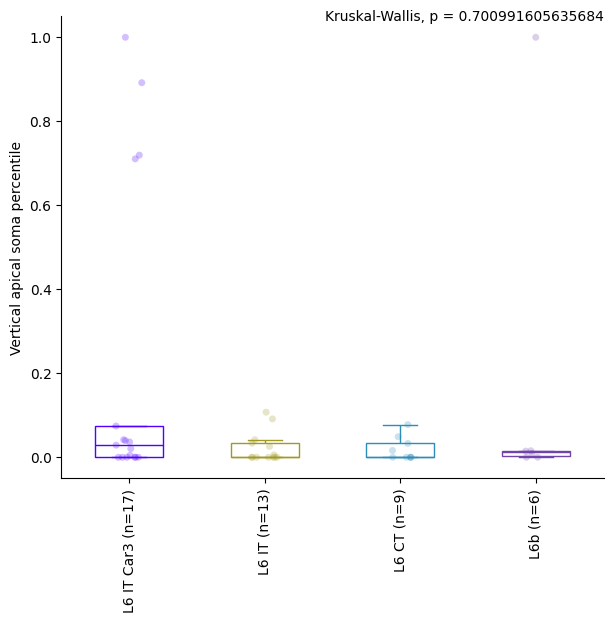

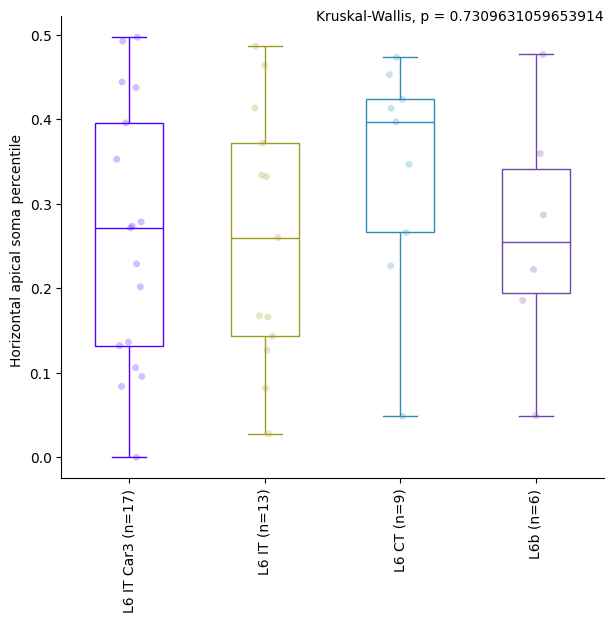

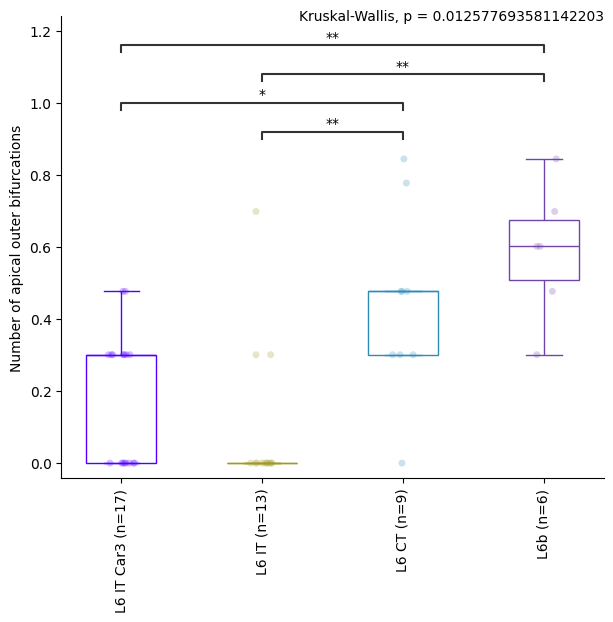

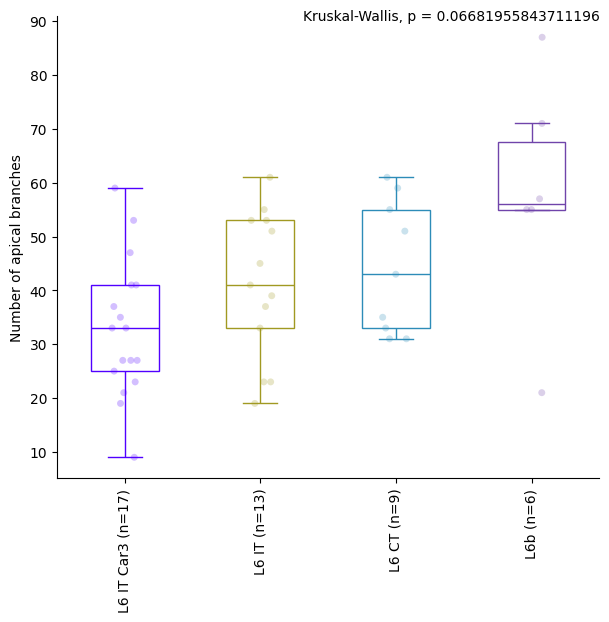

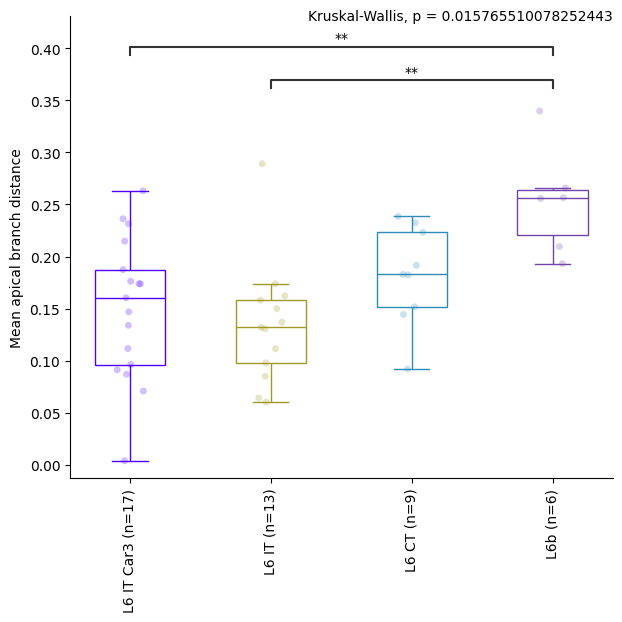

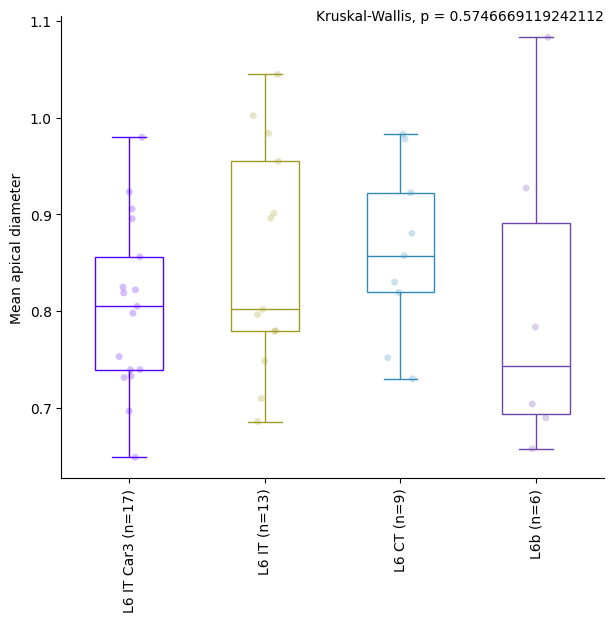

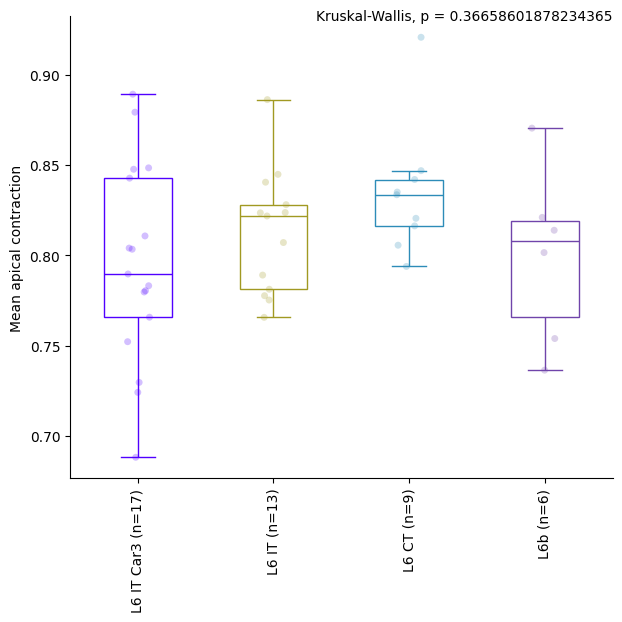

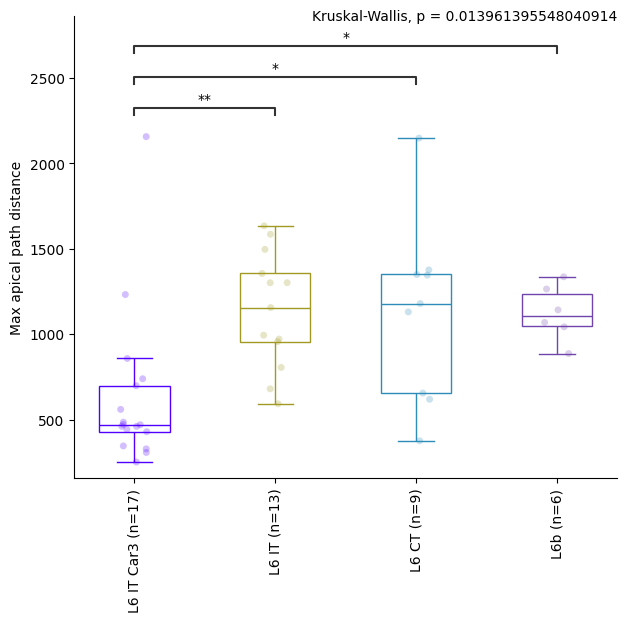

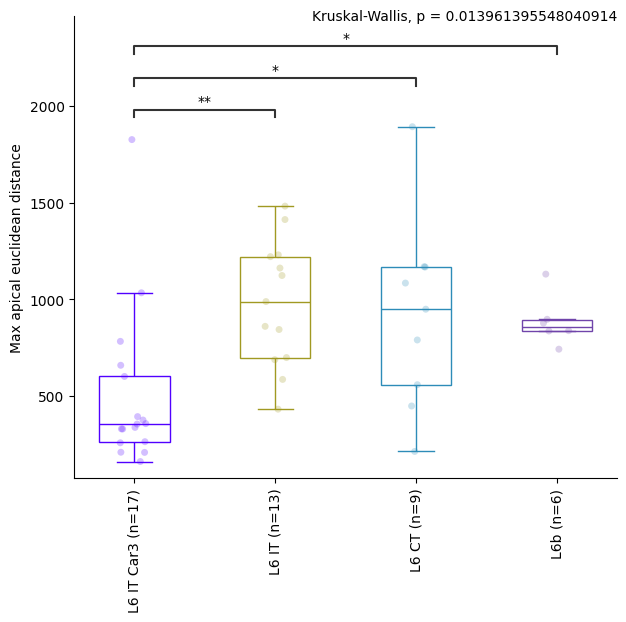

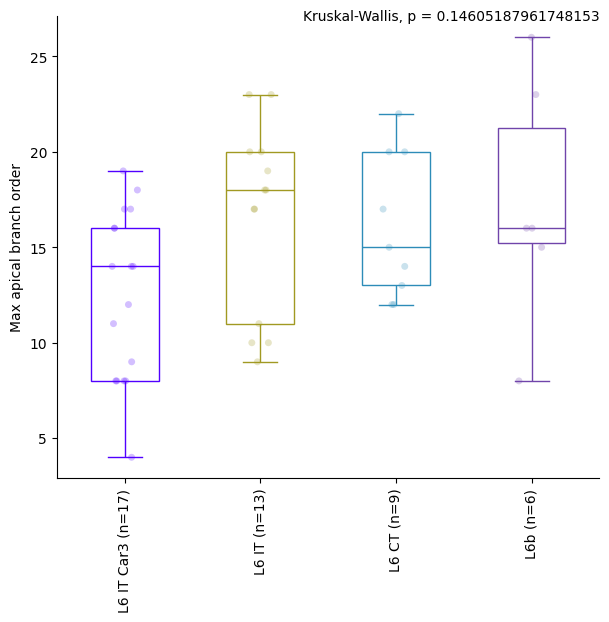

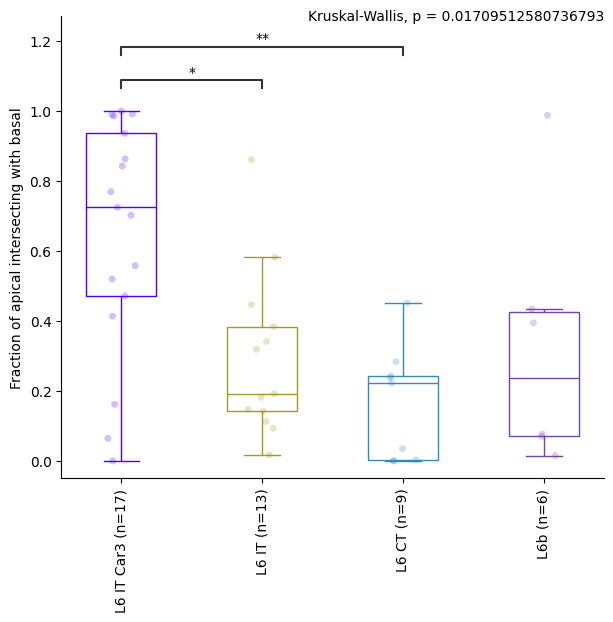

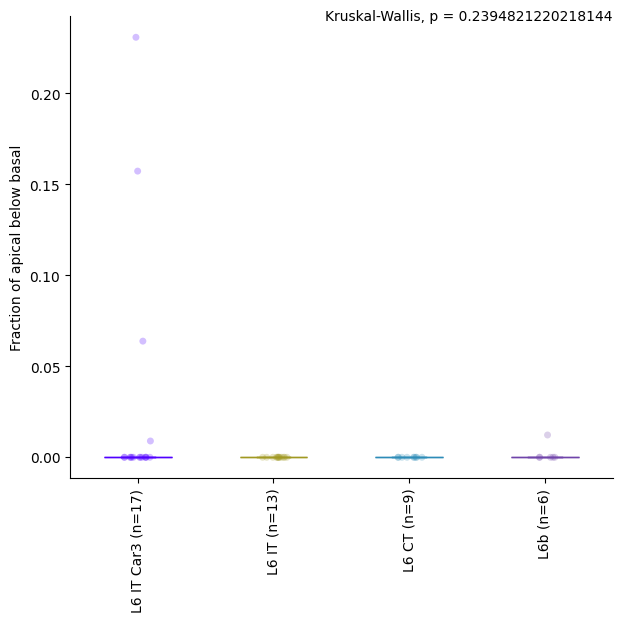

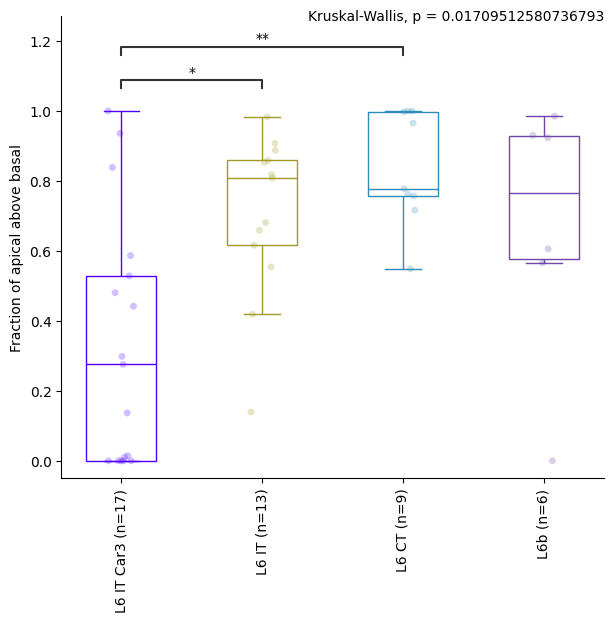

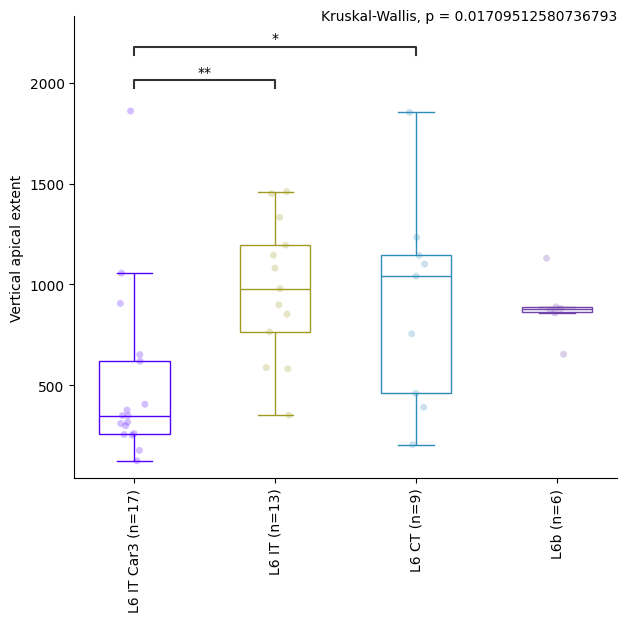

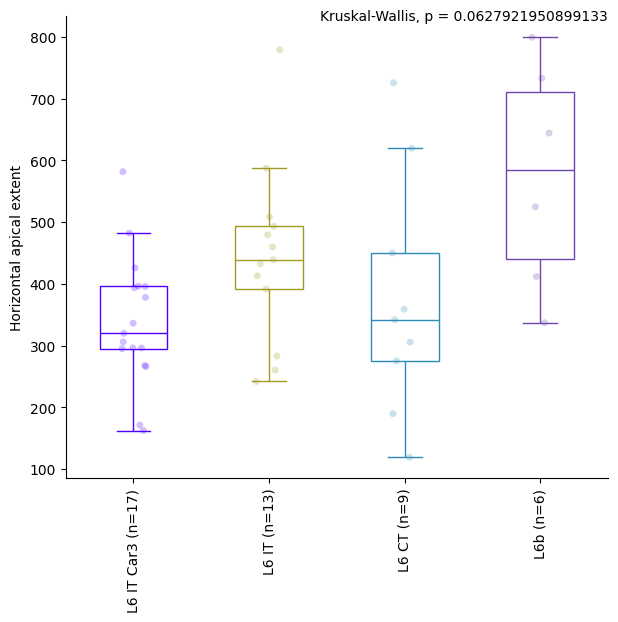

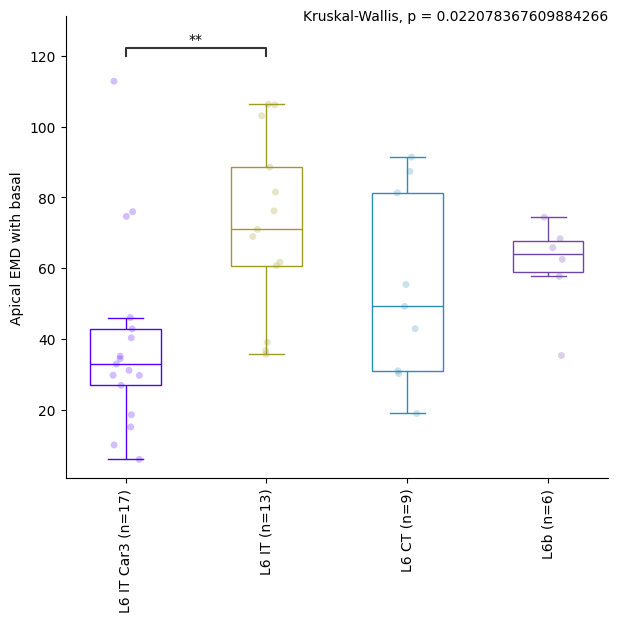

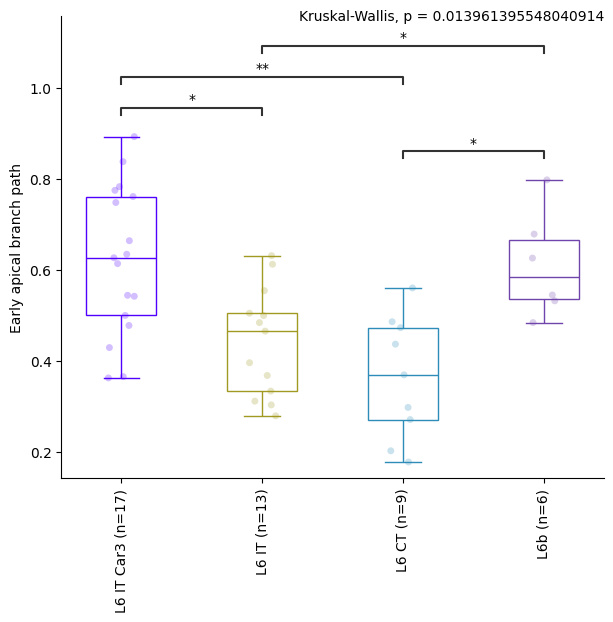

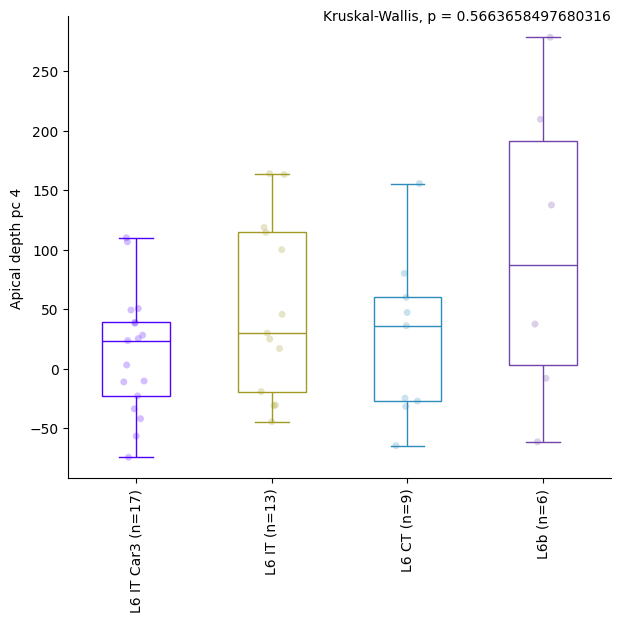

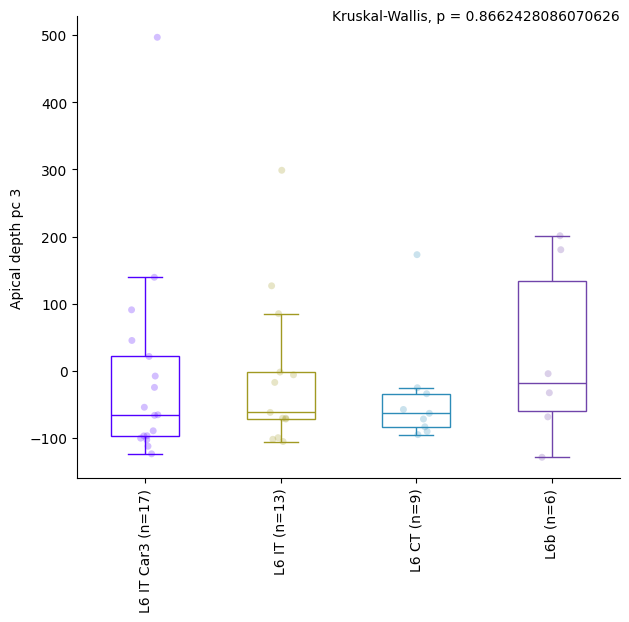

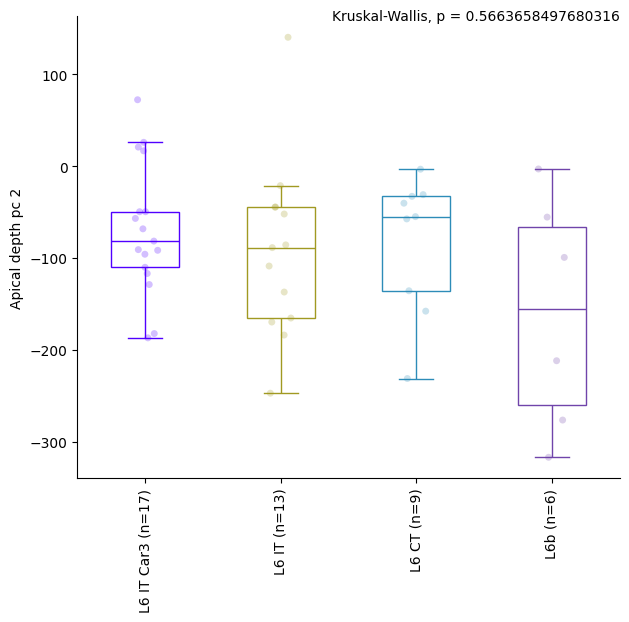

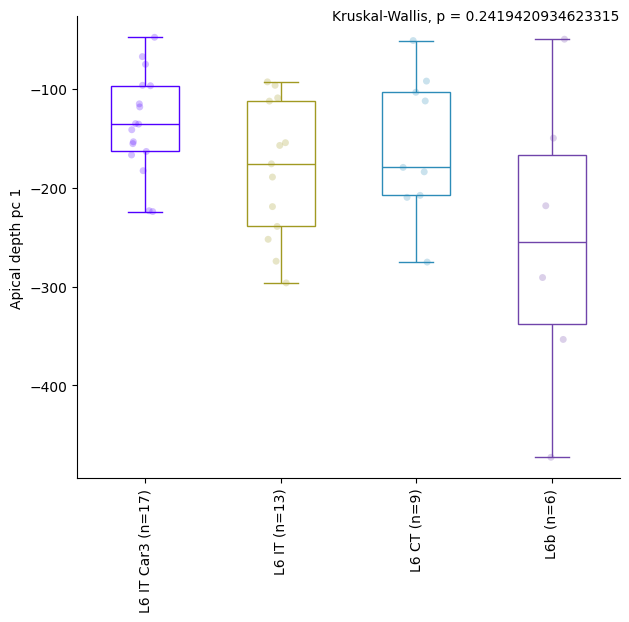

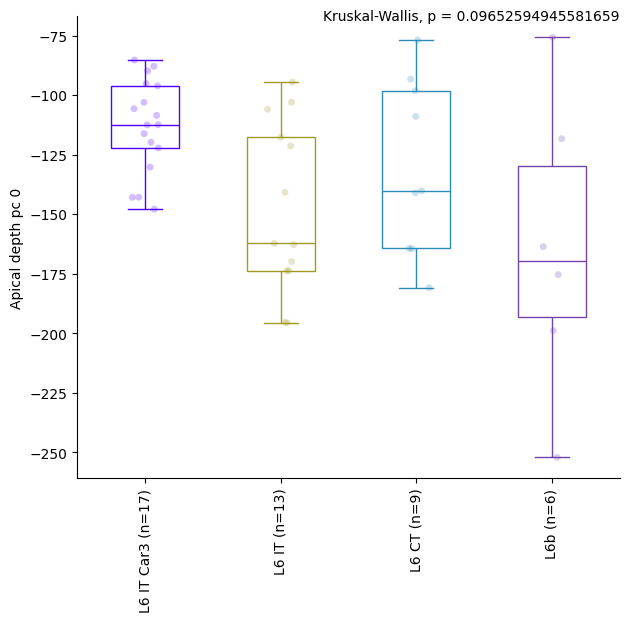

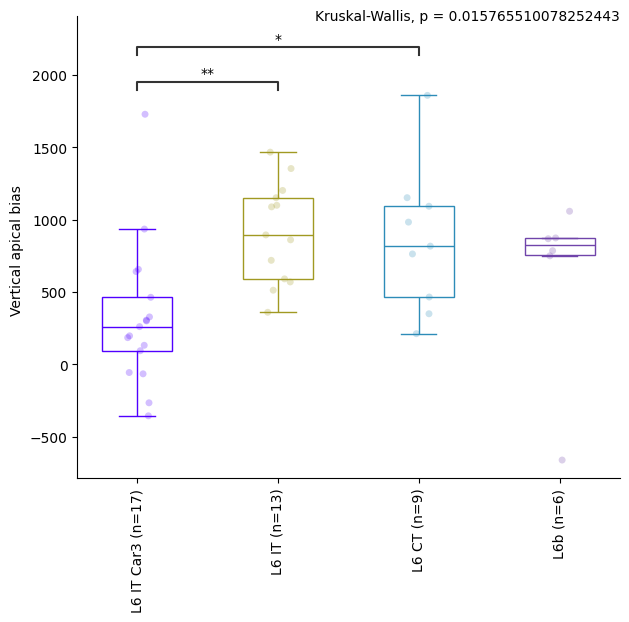

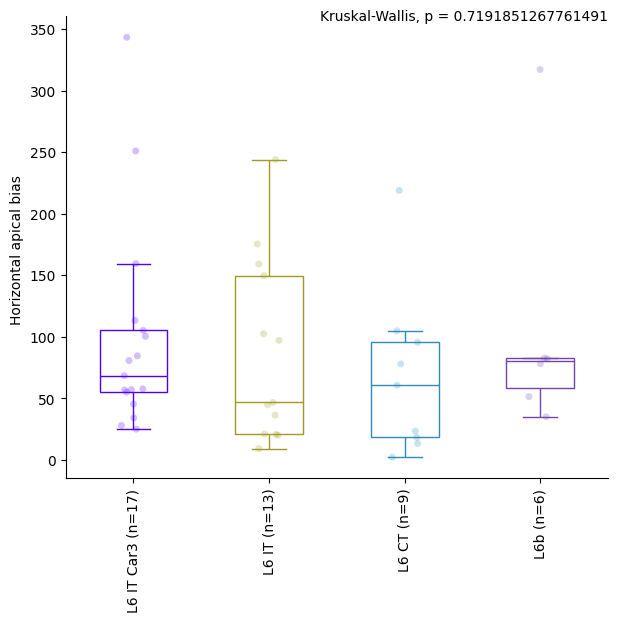

<Figure size 640x480 with 0 Axes>

In [9]:
# subclass x feature box plots

#ADJUST VARS
fig_name = 'human_excitatory_boxplots_dendrite_features_KW_Dunn_FDR_bySubclass_Layer6.pdf'

color_palette = color_dict #colors for x_var
hue_var = 't_type' #seperate strip plots into these categories 
hue_color_palette = color_dict #color palette for hue_var
##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

#######################

fig_path = os.path.join(output_dir, fig_name)
features = raw_feature_wide.columns.tolist()[1:] 

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        while features != []:
            
            #one fig per page, each has page (fig) has 4 rows. 
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
            
            y_var = features.pop()
            
            sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
            format_box_plot(ax) #color line not fill of boxplot


            #add num observations per x_var
            nobs = []
            for t in x_var_order:
                n = len(sorted_clean_data[sorted_clean_data[x_var] == t])
                nobs.append(" (n=%s)" % str(n))
            new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
            ax.set_xticklabels(new_x_tick_labels)

            # add stats (KW w/ Dunn post hoc FDR corrected)

            #plot signif dunn fdr p-vals 
            if y_var in dunn_pvals_fdr.keys(): 
                #kw fdr val was signif so there are dunn fdr vals to plot
                
                this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                this_dunn_pvals_fdr[remove] = np.nan
                dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                #set insignificant pvals to nan 
                p_thresh = 0.05 #threshold for plotting p vals 
                dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                #plot bar for all signif fdr corrected dunn p vals 
                pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                if len(pairs): 
                    #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                    p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                    annotator = Annotator(ax=ax, pairs=pairs, data=sorted_clean_data, x=x_var, y=y_var, order=x_var_order)
                    annotator.configure(text_format="star", loc="inside") #text_format="simple"
                    annotator.set_pvalues_and_annotate(p_values)
                    
            #plot Kruskal-Wallis fdr p-vals
            if y_var in kw_pvals_fdr.keys():
                xlimit = ax.get_xlim()
                ylimit = ax.get_ylim()
                p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

            #rotate and format x_var labels 
            ax.set(xlabel=None)
            ax.tick_params(axis='x', rotation=90)
            ax.set_ylabel(y_var.replace("_", " "), rotation=90)
            ax.spines[['right', 'top']].set_visible(False)

            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf()
        print()



Layer x feature box plots with stats

In [ ]:
# subclass x feature stats
x_var = 'layer' #what to do box plots on 
x_var_order = group_order[x_var]

features = raw_feature_wide.columns.tolist()[1:]

# Kruskal-Wallis H test on all features
kw_pvals = dict()
kw_hvals = dict()
for f in features:
    # Create a list of groups dynamically
    groups = [sorted_clean_data.loc[sorted_clean_data[x_var] == x][f].dropna() for x in x_var_order]
    
    # Only include groups that have data
    groups = [group for group in groups if not group.empty]

    if len(groups) < 2:
        print(f"Not enough groups with data for feature {f}")
        continue
    try:
        hvalue, pvalue = kruskal(*groups, nan_policy='omit')
        kw_hvals[f] = hvalue
        kw_pvals[f] = pvalue
    except ValueError as e:
        print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

# FDR correction
kw_pvals_list = list(kw_pvals.values())
kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

# Post Hoc Dunn test for significant KW features, with FDR correction
dunn_pvals_fdr = dict()
for k, v in kw_rejected.items():
    if v:  # if null hypothesis was rejected, calculate Dunn post hoc
        dunn_pvals_fdr[k] = posthoc_dunn(sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)


In [ ]:
# subclass x feature box plots

#ADJUST VARS
fig_name = 'human_excitatory_boxplots_dendrite_features_KW_Dunn_FDR_byLayer.pdf'

hue_var = 'layer' #seperate strip plots into these categories 
color_palette = color_dicts[hue_var] #colors for x_var

#######################

fig_path = os.path.join(output_dir, fig_name)
features = raw_feature_wide.columns.tolist()[1:] 

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        while features != []:
            
            #one fig per page, each has page (fig) has 4 rows. 
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},            
            y_var = features.pop()
            
            sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
            format_box_plot(ax) #color line not fill of boxplot


            #add num observations per x_var
            nobs = []
            for t in x_var_order:
                n = len(sorted_clean_data[sorted_clean_data[x_var] == t])
                nobs.append(" (n=%s)" % str(n))
            new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
            ax.set_xticklabels(new_x_tick_labels)

            # add stats (KW w/ Dunn post hoc FDR corrected)

            #plot signif dunn fdr p-vals 
            if y_var in dunn_pvals_fdr.keys(): 
                #kw fdr val was signif so there are dunn fdr vals to plot
                
                this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                this_dunn_pvals_fdr[remove] = np.nan
                dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                #set insignificant pvals to nan 
                p_thresh = 0.05 #threshold for plotting p vals 
                dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                #plot bar for all signif fdr corrected dunn p vals 
                pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                if len(pairs): 
                    #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                    p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                    annotator = Annotator(ax=ax, pairs=pairs, data=sorted_clean_data, x=x_var, y=y_var, order=x_var_order)
                    annotator.configure(text_format="star", loc="inside") #text_format="simple"
                    annotator.set_pvalues_and_annotate(p_values)
                    
            #plot Kruskal-Wallis fdr p-vals
            if y_var in kw_pvals_fdr.keys():
                xlimit = ax.get_xlim()
                ylimit = ax.get_ylim()
                p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

            #rotate and format x_var labels 
            ax.set(xlabel=None)
            ax.tick_params(axis='x', rotation=90)
            ax.set_ylabel(y_var.replace("_", " "), rotation=90)
            ax.spines[['right', 'top']].set_visible(False)

            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf()
        print()



Cross areal box plots - subclass

In [ ]:
# subclass x feature box plots

x_var = 'lobe_group'
group1_label = 'TemL'
group2_label = 'Other'
group_var = 'subclass_label'

features = raw_feature_wide.columns.tolist()[1:]
# groups = sorted_clean_data[group_var].unique()

n_min_cells = 3
combo_counts = sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()


# Collect p-values and stats by (subclass, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = sorted_clean_data[sorted_clean_data[group_var] == group]
    for f in features:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


In [ ]:
# subclass x feature box plots
fig_name = 'human_excitatory_boxplots_dendrite_features_lobe_MWU_FDR_bySubclass.pdf'

x_var = 'subclass_label'
hue_var = 'lobe_group'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = ['TemL', 'Other']
color_palette = color_dicts[hue_var]

fig_path = os.path.join(output_dir, fig_name)
features = raw_feature_wide.columns.tolist()[1:]

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            sns.set_context('poster')
            strip = sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)
            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
            
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'TemL')])
                nO = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'Other')])
                nobs.append("\n(n TemL={})\n(n Other={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=10)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'TemL'), (subclass, 'Other')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf

    print("Boxplots with Mann-Whitney U stats saved.")


Cross areal box plots - ttype 

In [ ]:
# ttype x feature box plots

x_var = 'lobe_group'
group1_label = 'TemL'
group2_label = 'Other'
group_var = 't_type'

features = raw_feature_wide.columns.tolist()[1:]
# groups = sorted_clean_data[group_var].unique()

n_min_cells = 3
combo_counts = sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()


# Collect p-values and stats by (ttype, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = sorted_clean_data[sorted_clean_data[group_var] == group]
    for f in features:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


In [ ]:
# ttype x feature box plots
fig_name = 'human_excitatory_boxplots_dendrite_features_lobe_MWU_FDR_byTtype.pdf'

x_var = 't_type'
hue_var = 'lobe_group'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = ['TemL', 'Other']
color_palette = color_dicts[hue_var]

fig_path = os.path.join(output_dir, fig_name)
features = raw_feature_wide.columns.tolist()[1:]

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            sns.set_context('poster')
            strip = sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)
            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
            
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'TemL')])
                nO = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'Other')])
                nobs.append("\n(n TemL={})\n(n Other={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=10)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'TemL'), (subclass, 'Other')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf


Cross areal box plots - subclass - TemL vs FroL

In [ ]:
# subclass x feature box plots

x_var = 'lobe'
x_var_order = group_order[x_var]
group1_label = 'TemL'
group2_label = 'FroL'
group_var = 'subclass_label'

features = raw_feature_wide.columns.tolist()[1:]
# groups = sorted_clean_data[group_var].unique()

this_sorted_clean_data = sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)]
n_min_cells = 3
combo_counts = this_sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()


# Collect p-values and stats by (subclass, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = this_sorted_clean_data[this_sorted_clean_data[group_var] == group]
    for f in features:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


In [ ]:
# subclass x feature box plots
fig_name = 'human_excitatory_boxplots_dendrite_features_lobe_teml_frol_MWU_FDR_bySubclass.pdf'

x_var = 'subclass_label'
hue_var = 'lobe'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = ['TemL', 'FroL']
color_palette = color_dicts[hue_var]

this_sorted_clean_data = sorted_clean_data[sorted_clean_data[hue_var].isin(hue_order)]

fig_path = os.path.join(output_dir, fig_name)
features = raw_feature_wide.columns.tolist()[1:]

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            sns.set_context('poster')
            strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)
            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
            
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == 'TemL')])
                nO = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == 'FroL')])
                nobs.append("\n(n TemL={})\n(n FroL={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=10)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'TemL'), (subclass, 'FroL')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf

    print("Boxplots with Mann-Whitney U stats saved.")


Cross areal box plots - ttype - TemL vs FroL

In [ ]:
# ttype x feature box plots

x_var = 'lobe'
x_var_order = group_order[x_var]
group1_label = 'TemL'
group2_label = 'FroL'
group_var = 't_type'

features = raw_feature_wide.columns.tolist()[1:]
# groups = sorted_clean_data[group_var].unique()

this_sorted_clean_data = sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)]
n_min_cells = 3
combo_counts = this_sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()


# Collect p-values and stats by (ttype, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = this_sorted_clean_data[this_sorted_clean_data[group_var] == group]
    for f in features:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


In [ ]:
# ttype x feature box plots
fig_name = 'human_excitatory_boxplots_dendrite_features_lobe_teml_frol_MWU_FDR_byTtype.pdf'

x_var = 't_type'
hue_var = 'lobe'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = ['TemL', 'FroL']
color_palette = color_dicts[hue_var]

this_sorted_clean_data = sorted_clean_data[sorted_clean_data[hue_var].isin(hue_order)]

fig_path = os.path.join(output_dir, fig_name)
features = raw_feature_wide.columns.tolist()[1:]

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            sns.set_context('poster')
            strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)
            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
            
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == 'TemL')])
                nO = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == 'FroL')])
                nobs.append("\n(n TemL={})\n(n FroL={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=10)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'TemL'), (subclass, 'FroL')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf


Cross paradigm box plots - subclass

In [ ]:
# subclass x feature box plots

x_var = 'paradigm'
group1_label = 'acute'
group2_label = 'culture'
group_var = 'subclass_label'

features = raw_feature_wide.columns.tolist()[1:]
# groups = sorted_clean_data[group_var].unique()

n_min_cells = 3
combo_counts = sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()


# Collect p-values and stats by (subclass, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = sorted_clean_data[sorted_clean_data[group_var] == group]
    for f in features:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


In [ ]:
#Save stats
rows = []
for (subclass, feature), pval in mw_pvals.items():
    rows.append({
        'subclass': subclass,
        'feature': feature,
        'mw_stat': mw_stats.get((subclass, feature)),
        'pval_raw': pval,
        'pval_fdr': mw_pvals_fdr.get((subclass, feature)),
        'rejected_pval_fdr': mw_rejected.get((subclass, feature)),
        'group1': group1_label,
        'group2': group2_label
    })

mw_stats_df = pd.DataFrame(rows)

# optional: sort for readability
mw_stats_df = mw_stats_df.sort_values(
    ['subclass', 'pval_fdr'],
    ascending=[True, True]
)

# save
mw_stats_df.to_csv(os.path.join(output_dir, r'morphology_feature_box_plot_stats_paradigm_subclass.csv'), index=False)
mw_stats_df

In [ ]:
# subclass x feature box plots
fig_name = 'human_excitatory_boxplots_dendrite_features_paradigm_MWU_FDR_bySubclass.pdf'

x_var = 'subclass_label'
hue_var = 'paradigm'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = ['acute', 'culture']
color_palette = color_dicts[hue_var]

fig_path = os.path.join(output_dir, fig_name)
features = raw_feature_wide.columns.tolist()[1:]

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            sns.set_context('poster')
            strip = sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)
            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
            
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'acute')])
                nO = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'culture')])
                nobs.append("\n(n acute={})\n(n culture={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=10)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'acute'), (subclass, 'culture')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf

    print("Boxplots with Mann-Whitney U stats saved.")


Cross paradigm box plots - ttype

In [ ]:
# ttype x feature box plots

x_var = 'paradigm'
group1_label = 'acute'
group2_label = 'culture'
group_var = 't_type'

features = raw_feature_wide.columns.tolist()[1:]
# groups = sorted_clean_data[group_var].unique()

n_min_cells = 3
combo_counts = sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()


# Collect p-values and stats by (ttype, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = sorted_clean_data[sorted_clean_data[group_var] == group]
    for f in features:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


In [ ]:
# ttype x feature box plots
fig_name = 'human_excitatory_boxplots_dendrite_features_paradigm_MWU_FDR_byTtype.pdf'

x_var = 't_type'
hue_var = 'paradigm'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = ['acute', 'culture']
color_palette = color_dicts[hue_var]

fig_path = os.path.join(output_dir, fig_name)
features = raw_feature_wide.columns.tolist()[1:]

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            sns.set_context('poster')
            strip = sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)
            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
            
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'acute')])
                nO = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'culture')])
                nobs.append("\n(n acute={})\n(n culture={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=10)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'acute'), (subclass, 'culture')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf


Other metadata box plots - subclass

In [ ]:
#add other metadata
additional_metadata_cols = ['group', 'age(yrs)', 'sex', 'medical_conditions'] #'paradigm',
additional_metadata = pd.read_csv(metadata_path, index_col='cell_id')[additional_metadata_cols]
additional_metadata = additional_metadata.rename(columns={'age(yrs)' : 'age'})

sorted_clean_data = sorted_clean_data.merge(additional_metadata, how='left', left_on='specimen_id', right_index=True)

#format metadata column labels 
sorted_clean_data['medical_conditions'] = sorted_clean_data['medical_conditions'].str.lower()
sorted_clean_data['sex'] = sorted_clean_data['sex'].replace('F or M?', 'unknown')
sorted_clean_data['age_bin'] = pd.cut(pd.to_numeric(sorted_clean_data['age'], errors='coerce'), bins=[18, 40, 60, 100], labels=['18-40', '40-60', '60-100'])
sorted_clean_data['age_bin'] = sorted_clean_data['age_bin'].astype('object').fillna('unknown')
sorted_clean_data['lobe_group'] = sorted_clean_data['lobe'].apply(lambda x: x if x == 'TemL' else 'Other')
sorted_clean_data['group'] = sorted_clean_data['group'].replace('pilot', 'IVSCC')


KW functions

In [ ]:
def compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features):

    # STORE RESULTS
    kw_pvals = {}
    kw_hvals = {}
    dunn_tables = {}

    # KW per (subclass, feature)
    for subclass in x_var_order:
        sub_df = sorted_clean_data[sorted_clean_data[x_var] == subclass]

        for f in features:
            groups = [
                sub_df[sub_df[group_var] == g][f].dropna()
                for g in group_order
            ]

            groups = [g for g in groups if len(g) > 0]

            if len(groups) < 2:
                continue

            try:
                h, p = kruskal(*groups)
                kw_hvals[(subclass, f)] = h
                kw_pvals[(subclass, f)] = p
            except Exception as e:
                print(f"KW failed: {subclass}, {f} -> {e}")

    # FDR correction (over all subclass-feature tests)
    pvals = list(kw_pvals.values())
    rej, pvals_fdr = fdrcorrection(pvals, alpha=0.05)

    kw_pvals_fdr = dict(zip(kw_pvals.keys(), pvals_fdr))
    kw_rejected = dict(zip(kw_pvals.keys(), rej))

    # Dunn post hoc ONLY for significant KW results
    # (within each subclass × feature)
    for (subclass, f), sig in kw_rejected.items():

        if not sig:
            continue

        sub_df = sorted_clean_data[sorted_clean_data[x_var] == subclass]
        sub_df = sub_df[sub_df[group_var].isin(group_order)]
        
        try:
            dunn = posthoc_dunn(
                sub_df,
                val_col=f,
                group_col=group_var,
                p_adjust='fdr_bh'
            )
            dunn_tables[(subclass, f)] = dunn

        except Exception as e:
            print(f"Dunn failed: {subclass}, {f} -> {e}")

    return kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables

In [ ]:
def get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected):

    rows = []
    for (subclass, feature), p in kw_pvals.items():
        rows.append({
            'subclass': subclass,
            'feature': feature,
            'kw_H': kw_hvals.get((subclass, feature)),
            'pval_raw': p,
            'pval_fdr': kw_pvals_fdr.get((subclass, feature)),
            'rejected_fdr': kw_rejected.get((subclass, feature)),
        })

    kw_stats_df = pd.DataFrame(rows)
    kw_stats_df = kw_stats_df.sort_values(['subclass', 'pval_fdr'], ascending=True)

    return kw_stats_df


In [ ]:
def get_dunn_stats_df(dunn_tables):
    dunn_rows = []

    for (subclass, feature), dunn_df in dunn_tables.items():

        # iterate upper triangle only
        for i, g1 in enumerate(dunn_df.index):

            for j, g2 in enumerate(dunn_df.columns):

                if j <= i:
                    continue

                dunn_rows.append({
                    'subclass': subclass,
                    'feature': feature,
                    'group1': g1,
                    'group2': g2,
                    'dunn_pval_fdr': dunn_df.loc[g1, g2]
                })

    dunn_stats_df = pd.DataFrame(dunn_rows)
    return dunn_stats_df

In [ ]:
def plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_order, y_vars, hue_var, hue_order, palette, dunn_tables, figsize=(8, 6)):

    # x_var, hue_var cleanup
    this_sorted_clean_data = sorted_clean_data.copy()

    # strip old categorical behavior completely
    this_sorted_clean_data[x_var] = this_sorted_clean_data[x_var].astype(str)
    this_sorted_clean_data[hue_var] = this_sorted_clean_data[hue_var].astype(str)

    # enforce clean order explicitly
    this_sorted_clean_data[x_var] = pd.Categorical( this_sorted_clean_data[x_var], categories=x_order, ordered=True )
    this_sorted_clean_data[hue_var] = pd.Categorical( this_sorted_clean_data[hue_var], categories=hue_order, ordered=True )
    this_sorted_clean_data = this_sorted_clean_data[ this_sorted_clean_data[x_var].isin(x_order) ]

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)

        with PdfPages(fig_path) as pdf:

            for y_var in y_vars:

                fig, ax = plt.subplots(
                    nrows=1,
                    ncols=1,
                    figsize=figsize,
                    sharex=True,
                    gridspec_kw={'wspace': 0, 'hspace': 0.1}
                )

                sns.set_context('poster')

                strip = sns.stripplot( data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order, hue_order=hue_order, palette=palette, dodge=True, alpha=0.75, size=4, ax=ax )
                sns.boxplot( data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order, hue_order=hue_order, palette=palette, showfliers=False, width=0.6, linewidth=1, saturation=1, ax=ax )

                # formatting
                format_box_plot(ax)
                sns.despine(ax=ax, right=True, top=True)

                ax.set_xlabel("")
                ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)

                # tighter category spacing
                # ax.margins(x=0.01)

                # remove auto legend
                if ax.legend_ is not None:
                    ax.legend_.remove()

                # custom legend handles
                custom_handles = [
                    Line2D(
                        [0], [0],
                        marker='o',
                        color='w',
                        label=group,
                        markerfacecolor=palette[i],
                        markeredgecolor=palette[i],
                        markersize=8,
                        alpha=0.7
                    )
                    for i, group in enumerate(hue_order)
                ]

                ax.legend(
                    handles=custom_handles,
                    title=hue_var,
                    bbox_to_anchor=(1.02, 1),
                    loc='upper left',
                    borderaxespad=0
                )

                # rotate labels
                ax.tick_params(axis='x', rotation=90, labelsize=10)

                #add num observations per x_var
                nobs = []
                for s in x_order:
                    counts = []
                    for h in hue_order:
                        n = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == h) & (~this_sorted_clean_data[y_var].isna())])
                        counts.append(f"({h}={n})")
                    label = "\n".join(counts)
                    nobs.append(label)

                new_x_tick_labels = [x_order[i] + "\n" + nobs[i] for i in range(len(x_order))]
                ax.set_xticklabels(new_x_tick_labels)
                ax.tick_params(axis='x', rotation=90, labelsize=10)


                # ADD DUNN SIGNIFICANCE
                pairs = []
                pvals = []

                for subclass in x_order:
                    key = (subclass, y_var)

                    if key not in dunn_tables:
                        continue

                    dunn = dunn_tables[key]

                    mask = np.tril(np.ones(dunn.shape), k=0).astype(bool)
                    dunn = dunn.copy()
                    dunn[mask] = np.nan

                    melted = dunn.melt(ignore_index=False).reset_index()
                    melted = melted.dropna()
                    melted = melted[melted['value'] < 0.05]

                    for _, row in melted.iterrows():
                        pairs.append([
                            (subclass, row['index']),
                            (subclass, row['variable'])
                        ])
                        pvals.append(row['value'])

                if len(pairs) > 0:
                    annot = Annotator(
                        ax,
                        pairs,
                        data=this_sorted_clean_data,
                        x=x_var,
                        y=y_var,
                        hue=hue_var,
                        order=x_order,
                        hue_order=hue_order
                    )

                    annot.configure(
                        text_format="star",
                        loc="inside",
                        fontsize=14
                    )

                    annot.set_pvalues_and_annotate(pvals)

                plt.tight_layout()
                pdf.savefig(fig, bbox_inches='tight', dpi=600)
                plt.show()

            plt.close(fig)

MW functions

In [ ]:
def compute_mw_stats(sorted_clean_data, x_var, group1_label, group2_label, group_var, features):

    n_min_cells = 3
    combo_counts = sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
    groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()


    # Collect p-values and stats by (subclass, feature)
    mw_pvals = dict()
    mw_stats = dict()

    for group in groups:
        sub_data = sorted_clean_data[sorted_clean_data[group_var] == group]
        for f in features:
            group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
            group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

            if group1.empty or group2.empty:
                continue

            try:
                stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
                mw_pvals[(group, f)] = pval
                mw_stats[(group, f)] = stat
            except ValueError as e:
                print(f'Mann-Whitney failed for {group}, {f}: {e}')

    # FDR correction across all tests (subclass-feature pairs)
    mw_pvals_list = list(mw_pvals.values())
    mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

    mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
    mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))

    return mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected


In [ ]:
def get_mw_stats_df(mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected):

    #Save stats
    rows = []
    for (subclass, feature), pval in mw_pvals.items():
        rows.append({
            'subclass': subclass,
            'feature': feature,
            'mw_stat': mw_stats.get((subclass, feature)),
            'pval_raw': pval,
            'pval_fdr': mw_pvals_fdr.get((subclass, feature)),
            'rejected_pval_fdr': mw_rejected.get((subclass, feature)),
            'group1': group1_label,
            'group2': group2_label
        })

    mw_stats_df = pd.DataFrame(rows)
    if len(mw_stats_df)>0:
        mw_stats_df = mw_stats_df.sort_values( ['subclass', 'pval_fdr'], ascending=[True, True])
    return mw_stats_df


In [ ]:
def plot_box_plots_with_mw_dunn_stats(fig_path, sorted_clean_data, x_var, x_order, y_vars, hue_var, group1_label, group2_label, palette, mw_pvals_fdr, mw_rejected):

    # x_var, hue_var cleanup
    this_sorted_clean_data = sorted_clean_data.copy()

    # strip old categorical behavior completely
    this_sorted_clean_data[x_var] = this_sorted_clean_data[x_var].astype(str)
    this_sorted_clean_data[hue_var] = this_sorted_clean_data[hue_var].astype(str)

    # enforce clean order explicitly
    this_sorted_clean_data[x_var] = pd.Categorical( this_sorted_clean_data[x_var], categories=x_order, ordered=True )
    this_sorted_clean_data[hue_var] = pd.Categorical( this_sorted_clean_data[hue_var], categories=[group1_label, group2_label], ordered=True )
    this_sorted_clean_data = this_sorted_clean_data[ this_sorted_clean_data[x_var].isin(x_order) ]

    print(len(this_sorted_clean_data))

    with warnings.catch_warnings():
        warnings.simplefilter(action='ignore', category=FutureWarning)

        with PdfPages(fig_path) as pdf:
            for y_var in y_vars:
                fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

                sns.set_context('poster')
                strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
                sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)

                #format 
                format_box_plot(ax) #clear fill of box plots, color edges
                sns.despine(right=True, top=True)
                ax.set_xlabel("")
                ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)

                # remove auto legend
                if ax.legend_ is not None:
                    ax.legend_.remove()

                # custom legend handles
                custom_handles = [
                    Line2D(
                        [0], [0],
                        marker='o',
                        color='w',
                        label=group,
                        markerfacecolor=palette[i],
                        markeredgecolor=palette[i],
                        markersize=8,
                        alpha=0.7
                    )
                    for i, group in enumerate([group1_label, group2_label])
                ]

                ax.legend(
                    handles=custom_handles,
                    title=hue_var,
                    bbox_to_anchor=(1.02, 1),
                    loc='upper left',
                    borderaxespad=0
                )


                #add num observations per x_var
                nobs = []
                for s in x_order:
                    nT = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == group1_label) & (~this_sorted_clean_data[y_var].isna())])
                    nO = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == group2_label) & (~this_sorted_clean_data[y_var].isna())])
                    nobs.append("\n(n {}={})\n(n {}={})".format(group1_label, nT, group2_label, nO))
                new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
                ax.set_xticklabels(new_x_tick_labels)
                ax.tick_params(axis='x', rotation=90, labelsize=10)

                # Annotate p-values
                pairs = []
                p_values = []
                for subclass in x_order:
                    key = (subclass, y_var)
                    if key in mw_pvals_fdr:
                        pval = mw_pvals_fdr[key]
                        sig = mw_rejected.get(key, False)
                        if sig:
                            pairs.append([(subclass, 'acute'), (subclass, 'culture')])  # or vice versa
                            p_values.append(pval)

                # Only annotate if there are significant results
                if pairs:
                    annotator = Annotator(ax, pairs, data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                    annotator.configure(text_format="star", loc="inside", fontsize=14)
                    annotator.set_pvalues_and_annotate(p_values)

                # fig.tight_layout()
                pdf.savefig(dpi=600, bbox_inches='tight')
            plt.show()
            plt.clf
        

Cross disease state box plots - subclass

In [ ]:
#compute KW - FDR - Dunn stats for all medical conditions
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'medical_conditions'
group_order = sorted_clean_data[group_var].unique().tolist()
# #removing groups that only have one cell
# group_count = sorted_clean_data[group_var].value_counts()
# group_order = group_count[group_count > 1].index.tolist()

features = raw_feature_wide.columns.tolist()[1:]
kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'morphology_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'morphology_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs.csv'), index=False)

#plot box plots
fig_name = f'morphology_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables)


#### *removing single cells with `hydrocephalus` and `hydrocephalus or tumor?` conditions 

In [ ]:
#compute MW - FDR stats for epilepsy and tumor medical conditions
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()

group_var = 'medical_conditions'
group1_label = 'epilepsy'
group2_label = 'tumor'
suffix = '_removeHydrocephalus'
features = raw_feature_wide.columns.tolist()[1:]
mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected = compute_mw_stats(sorted_clean_data, x_var, group1_label, group2_label, group_var, features)

#save stats
mw_stats_df = get_mw_stats_df(mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected)
mw_stats_df.to_csv(os.path.join(output_dir, f'morphology_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.csv'), index=False)

#plot box plots
fig_name = f'morphology_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order))
plot_box_plots_with_mw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group1_label, group2_label, palette, mw_pvals_fdr, mw_rejected)


Cross age box plots - subclass

In [ ]:
#compute KW - FDR - Dunn stats for all ages (including unknown)
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'age_bin'
group_order = sorted(sorted_clean_data[group_var].unique().tolist())

features = raw_feature_wide.columns.tolist()[1:]
kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'morphology_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'morphology_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs.csv'), index=False)

#plot box plots
fig_name = f'morphology_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables)


#### *removing `unknown` age cells

In [ ]:
#compute KW - FDR - Dunn stats for all medical conditions
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'age_bin'
group_order = sorted(sorted_clean_data[group_var].unique().tolist())
suffix = '_removeUnknown'
group_order.remove('unknown')
features = raw_feature_wide.columns.tolist()[1:]
kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'morphology_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR{suffix}.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'morphology_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs{suffix}.csv'), index=False)

#plot box plots
fig_name = f'morphology_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR{suffix}.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables)


Cross sex box plots - subclass

In [ ]:
#compute KW - FDR - Dunn stats for all sexes (including unknown)

x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'sex'
group_order = sorted_clean_data[group_var].unique().tolist()
features = raw_feature_wide.columns.tolist()[1:]

kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'morphology_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'morphology_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs.csv'), index=False)

#plot box plots
fig_name = f'morphology_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables)


#### *removing 8 cells with `unknown` sex

In [ ]:
#compute MW - FDR stats for F and M sexes only 
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()

group_var = 'sex'
group1_label = 'F'
group2_label = 'M'
suffix = '_removeUnknown'
features = raw_feature_wide.columns.tolist()[1:]
mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected = compute_mw_stats(sorted_clean_data, x_var, group1_label, group2_label, group_var, features)

#save stats
mw_stats_df = get_mw_stats_df(mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected)
mw_stats_df.to_csv(os.path.join(output_dir, f'morphology_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.csv'), index=False)

#plot box plots
fig_name = f'morphology_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order))
plot_box_plots_with_mw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group1_label, group2_label, palette, mw_pvals_fdr, mw_rejected)


Cross lab box plots - subclass

In [ ]:
#compute KW - FDR - Dunn stats for all sexes (including unknown)

x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'group'
group_order = sorted_clean_data[group_var].unique().tolist()
features = raw_feature_wide.columns.tolist()[1:]

kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'morphology_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'morphology_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs.csv'), index=False)

#plot box plots
fig_name = f'morphology_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables)


Cross paradigm box plots - stats [duplicate analysis from above, to match this formatting]

In [ ]:
#compute MW - FDR stats for F and M sexes only 
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()

group_var = 'paradigm'
group1_label = 'acute'
group2_label = 'culture'
features = raw_feature_wide.columns.tolist()[1:]
mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected = compute_mw_stats(sorted_clean_data, x_var, group1_label, group2_label, group_var, features)

#save stats
mw_stats_df = get_mw_stats_df(mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected)
mw_stats_df.to_csv(os.path.join(output_dir, f'morphology_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR.csv'), index=False)

#plot box plots
fig_name = f'morphology_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette = list(color_dicts[group_var].values())
plot_box_plots_with_mw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group1_label, group2_label, palette, mw_pvals_fdr, mw_rejected)


Cross lobe box plots - subclass

In [ ]:
#compute KW - FDR - Dunn stats for all sexes (including unknown)

x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'lobe'
group_order = sorted_clean_data[group_var].unique().tolist()
features = raw_feature_wide.columns.tolist()[1:]

kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'morphology_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'morphology_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs.csv'), index=False)

#plot box plots
fig_name = f'morphology_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables)


#### *group non-TemL as `Other`

In [ ]:
#compute MW - FDR stats for F and M sexes only 
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()

group_var = 'lobe_group'
group1_label = 'TemL'
group2_label = 'Other'
suffix = '_groupNonTemL'
features = raw_feature_wide.columns.tolist()[1:]
mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected = compute_mw_stats(sorted_clean_data, x_var, group1_label, group2_label, group_var, features)

#save stats
mw_stats_df = get_mw_stats_df(mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected)
mw_stats_df.to_csv(os.path.join(output_dir, f'morphology_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.csv'), index=False)

#plot box plots
fig_name = f'morphology_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette = list(color_dicts[group_var].values())
plot_box_plots_with_mw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group1_label, group2_label, palette, mw_pvals_fdr, mw_rejected)


Distal apical subclass stats

In [6]:
# Most distal (y) apical node for each cell per subclass 

all_groups= group_order['subclass_label']

group_data_dict = {}
for group in all_groups:
    #get group data 
    group_data = sorted_clean_data[sorted_clean_data.subclass_label == group]

    #
    soma_depths_y = []
    distal_apicals_y = []
    num_nodes = 0
    for sp in group_data.specimen_id.values:
        swc_pth = sorted_clean_data.SWC_layer_aligned[sorted_clean_data.specimen_id == sp].iloc[0]
        nrn = morphology_from_swc(swc_pth)
        if nrn.has_type(4): 
            #neuron has apical, get the most distal one
            apical_nodes = nrn.get_node_by_types([4])
            most_distal_apical = -100000000000000
            for node in apical_nodes: most_distal_apical = max(node['y'], most_distal_apical)
            distal_apicals_y.append(most_distal_apical)
            soma_depths_y.append(sorted_clean_data.soma_distance_from_pia[sorted_clean_data.specimen_id == sp].iloc[0]) #plot the soma for this cell
            num_nodes += 1
    group_data_dict[group] = {'somas': soma_depths_y,
                              'apicals': distal_apicals_y, 
                              'label': "{} (n={})".format(group,num_nodes)}


In [8]:


# Combine data into a DataFrame
data_list = []
for group, vals in group_data_dict.items():
    for y in vals['apicals']:
        data_list.append({'subclass': group, 'distal_apical_y': y})

df_apical = pd.DataFrame(data_list)

# Kruskal-Wallis test (omnibus test)
groups = [df_apical.loc[df_apical['subclass']==g, 'distal_apical_y'] for g in df_apical['subclass'].unique()]
kw_stat, kw_p = kruskal(*groups)
print(f"Kruskal-Wallis: H={kw_stat:.3f}, p={kw_p:.3e}")

# Post-hoc Dunn test (only if KW is significant)
if kw_p < 0.05:
    # p_adjust='fdr_bh' applies FDR correction across pairwise comparisons
    dunn_p = posthoc_dunn(df_apical, val_col='distal_apical_y', group_col='subclass', p_adjust='fdr_bh')
    print("\nPost-hoc Dunn test (FDR-corrected):")
    print(dunn_p)
else:
    print("KW not significant — no post-hoc needed")


Kruskal-Wallis: H=226.838, p=1.381e-44

Post-hoc Dunn test (FDR-corrected):
                 L2/3 IT         L4 IT         L5 ET         L5 IT  \
L2/3 IT     1.000000e+00  6.902509e-17  1.298262e-01  9.546899e-14   
L4 IT       6.902509e-17  1.000000e+00  1.987252e-07  9.365459e-01   
L5 ET       1.298262e-01  1.987252e-07  1.000000e+00  3.266308e-07   
L5 IT       9.546899e-14  9.365459e-01  3.266308e-07  1.000000e+00   
L5/6 NP     6.866171e-07  8.291371e-01  4.989564e-06  8.467779e-01   
L6 CT       3.985376e-10  1.542051e-02  5.956412e-09  1.900832e-02   
L6 IT       5.583809e-12  1.760260e-02  2.155572e-09  2.349506e-02   
L6 IT Car3  1.819224e-15  4.745099e-03  1.418309e-10  8.114323e-03   
L6b         1.252661e-07  2.967375e-02  1.252661e-07  3.479661e-02   

                 L5/6 NP         L6 CT         L6 IT    L6 IT Car3  \
L2/3 IT     6.866171e-07  3.985376e-10  5.583809e-12  1.819224e-15   
L4 IT       8.291371e-01  1.542051e-02  1.760260e-02  4.745099e-03   
L5 ET       4

In [10]:
#save stats
kw_df = pd.DataFrame({
    'feature': ['distal_apical_y'],
    'H_stat': [kw_stat],
    'p_value': [kw_p]
})
kw_df.to_csv(os.path.join(output_dir, "subclass_apical_distal_y_krukal_wallis.csv"), index=False)

long_rows = []
for g1, g2 in itertools.combinations(dunn_p.columns, 2):
    long_rows.append({
        'sunclass_1': g1,
        'subclaas_2': g2,
        'p_value_fdr': dunn_p.loc[g1, g2]
    })
dunn_long = pd.DataFrame(long_rows)
dunn_long.to_csv(os.path.join(output_dir, "subclass_apical_distal_y_post_hoc_dunn.csv"), index=False)

/opt/conda/lib/python3.10/site-packages/matplotlib_scalebar/scalebar.py:457: UserWarning: Drawing scalebar on axes with unequal aspect ratio; either call ax.set_aspect(1) or suppress the warning with rotation='horizontal-only'.
  warnings.warn(


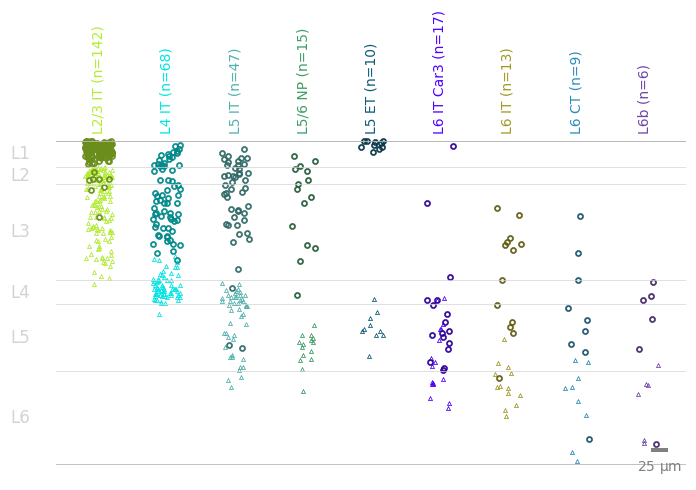

<Figure size 640x480 with 0 Axes>

In [11]:
# plot basal and apical dendrite histograms with soma depth loctions by subclass 

# TODO how to get um x axis on histos? need (avg) distance between nodes?

#within a group, what to sort by
fig_path = os.path.join(output_dir, 'human_excitatory_soma_superficial_apical_bySubclass.pdf')

#get set of all groups (subclasses)
all_groups = list(group_data_dict.keys())

#formatting text 
group_title_font_size = 10
group_title_start_height = 100 #starting height for group (e.g., region) title 
layer_label_font_size = 12
cell_title_start_height = 30 #starting height for cell title 

with PdfPages(fig_path) as pdf:
    with warnings.catch_warnings():
        warnings.simplefilter(action='ignore', category=FutureWarning)

        fig, ax = plt.subplots(nrows=1,ncols=1, figsize=(7,5)) #,sharey=True, figsize=(20,10)) 

        ax.axis('off')
        xloc = 0
        xoffset = 0
        ax.set_anchor('W')
        ax.axhline(0, c="lightgrey",linewidth=0.50)
        buffer = 100

        for l in layer_info:ax.axhline(-layer_info[l], c=layer_colors[l],linewidth=0.50)
        for l in layer_labels:ax.text(-30,-layer_labels[l], "{}".format(l),verticalalignment='center', horizontalalignment='left',fontsize=layer_label_font_size, color='lightgrey') 
        
        for i, group in enumerate(all_groups):
            #get group data 
            group_data = sorted_clean_data[sorted_clean_data.subclass_label == group]

            if len(group_data) == 0: continue

            #colors for subclass
            hex_color = color_dict[group][1:]
            contrast_level = 0.6 #0.45 #0.6 
            lighter_color_rgb = tuple(int(hex_color[i:i+2], 16) for i in (0, 2, 4))
            darker_color_rgb = tuple([int((contrast_level*x)) for x in lighter_color_rgb])
            grey_hex = '#8f8f8f'
            dark_hex = '#%02x%02x%02x' % darker_color_rgb
            hex_color = '#'+hex_color

            bin_width = 5 #um
            depth_bins = [int(sub[2:])*bin_width*-1 for sub in aligned_histogram.filter(regex='2_').columns.tolist()] 

            #plot soma depths first 
            xoffset += buffer 
            soma_depths_y = np.array(group_data_dict[group]['somas'])*-1
            soma_depths_x = np.ones(len(soma_depths_y))*xoffset
            jitter = np.array([random.randint(-2000,2000)*0.01 for n in soma_depths_y])
            soma_depths_x = soma_depths_x + jitter
            sns.scatterplot(x=soma_depths_x, y=soma_depths_y, ax=ax, color=hex_color, edgecolor=hex_color, s=10, marker=r"$\bigtriangleup$") 

            #plot distal apicals second
            distal_apicals_y = group_data_dict[group]['apicals']
            distal_apicals_x = np.ones(len(distal_apicals_y))*xoffset
            jitter = np.array([random.randint(-2000,2000)*0.01 for n in distal_apicals_y])
            distal_apicals_x = distal_apicals_x + jitter
            sns.scatterplot(x=distal_apicals_x, y=distal_apicals_y, ax=ax, color=dark_hex, edgecolor=dark_hex, s=20, marker="$\circ$")


            #save label 
            ax.text(xoffset,group_title_start_height,
            group_data_dict[group]['label'],
            horizontalalignment='center',fontsize=group_title_font_size, color=hex_color, rotation=90)

            #add a scale bar 
            if i == 0:
                scalebar = ScaleBar(1, "um", location='lower right', frameon=False, length_fraction=0.05, color = 'grey')
                ax.add_artist(scalebar)

    #save fig
    plt.tight_layout()
    pdf.savefig(fig, bbox_inches='tight')
    plt.show() #show the fig
    plt.clf() #destoy current fig to save memory

